# 🏁 Milestone 1 — Formula 1 Podium Prediction Companion

**Team:** Omar Osama · Mohamed Ayman · Moataz Ashraf · Omar Emad **Course:** CSEN 903 — Advanced Computer Lab (GUC, Winter 2026)

**Task:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before lights out**.

### How to read this notebook
| Marker | Meaning |
|---|---|
| ✅ | Mechanical / standard step — implemented, runs as-is. |
| **DECISION** | A choice we made and defend. It is marked `# DECISION:` in the code, justified in the markdown next to it, and backed by numbers in `DECISION_LOG.md`. |
| ✍️ **WRITE-UP** | Our interpretation of the plots and numbers above it. |

**Scope switch:** `DATA_SCOPE` (§1) selects the modelling seasons — `"modern"` (2006–2024, main) or `"all"` (1950–2024); §14.2 compares both on identical validation/test seasons.

Every decision is listed with the evidence behind it in `DECISION_LOG.md`. §18 prints the current choices and the D1–D16 cleaning summary.

### Contents
1. Setup & configuration
2. Load raw tables (immutable)
3. Audit — sentinels, keys, grain (**before** cleaning)
4. EDA — before cleaning
5. Cleaning — implements `F1_Cleaning_Plan.md` (fixed steps + decisions D1–D16)
6. Audit & EDA — after cleaning (before/after comparison)
7. Data-engineering questions (Q1–Q3)
8. Modeling table — one row per (raceId, driverId), leakage-safe features
9. Feature selection evidence
10. Train / validation / test split
11. Preprocessing & preprocessing-order experiments
12. Evaluation harness
13. Models — baseline, statistical models, shallow FFNN
14. Final evaluation on the unseen test set
15. Feature-group ablation
16. Explainability (XAI)
17. Inference function
18. Decision log, limitations & report material

## 1. Setup & configuration ✅

In [1]:
import os, sys, re, glob, json, warnings, subprocess, importlib, hashlib, html
from pathlib import Path

def _ensure(pkg, pip_name=None):
    # Install a package if missing (Kaggle needs Internet = ON in the notebook settings).
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=False)
        return importlib.import_module(pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.13.7 | pandas 3.0.6 | numpy 2.5.4


In [2]:
# ---- Data location: auto-detect Kaggle input, else ./data --------------------------
KAGGLE_DEFAULT = Path("/kaggle/input/formula-1-world-championship-1950-2020")

def find_data_dir():
    if (KAGGLE_DEFAULT / "races.csv").exists():
        return KAGGLE_DEFAULT
    hits = glob.glob("/kaggle/input/**/races.csv", recursive=True)
    if hits:
        return Path(hits[0]).parent
    for cand in [Path("data"), Path("../data"), Path(".")]:
        if (cand / "races.csv").exists():
            return cand
    raise FileNotFoundError("races.csv not found: attach the Kaggle dataset or put the CSVs in ./data")

DATA_DIR = Path(os.environ["F1_DATA_DIR"]) if os.environ.get("F1_DATA_DIR") else find_data_dir()
OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name, fig=None):
    # Save the current figure for the PDF report, then show it.
    fig = fig or plt.gcf()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)

print("DATA_DIR =", DATA_DIR.resolve())
print("Figures ->", FIG_DIR.resolve())

DATA_DIR = C:\Users\user\Downloads\ACL\data
Figures -> C:\Users\user\Downloads\ACL\outputs\figures


In [3]:
# ---- Scope switch (cleaning plan §1) ------------------------------------------------------
DATA_SCOPE = "modern"        # "modern" = 2006–2024 (main choice) | "all" = 1950–2024 (comparison trial, §14.2)
SCOPE_YEARS = {"modern": (2006, 2024), "all": (1950, 2024)}
TRAIN_END = 2020                                   # train = first scope season .. 2020
VAL_YEARS, TEST_YEARS = (2021, 2022), (2023, 2024)  # identical for both scopes: only the training seasons differ
MODERN_FROM = 2006           # knockout-qualifying era; from here grid = 0 means a pit-lane start (D5)

CB_DIR = Path("codebooks"); CB_DIR.mkdir(exist_ok=True)
print(f"DATA_SCOPE = {DATA_SCOPE} {SCOPE_YEARS[DATA_SCOPE]} | train ..{TRAIN_END} | val {VAL_YEARS} | test {TEST_YEARS}")

DATA_SCOPE = modern (2006, 2024) | train ..2020 | val (2021, 2022) | test (2023, 2024)


## 2. Load raw tables ✅
All 14 CSVs are read **as strings** with `keep_default_na=False`, so nothing is silently converted: the literal `\N` sentinels stay visible for the audit. `RAW` is never modified — every cleaning step works on copies (`T`).

In [4]:
TABLES = ["circuits", "constructor_results", "constructor_standings", "constructors",
          "driver_standings", "drivers", "lap_times", "pit_stops", "qualifying",
          "races", "results", "seasons", "sprint_results", "status"]

RAW = {t: pd.read_csv(DATA_DIR / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}

def frame_hash(tables):
    h = hashlib.sha256()
    for t in sorted(tables):
        h.update(t.encode())
        h.update(pd.util.hash_pandas_object(tables[t], index=True).values.tobytes())
    return h.hexdigest()

RAW_HASH = frame_hash(RAW)   # re-checked at the end of cleaning (§6): RAW must be unchanged

overview = pd.DataFrame({t: {"rows": len(df), "cols": df.shape[1], "columns": ", ".join(df.columns)}
                         for t, df in RAW.items()}).T
overview

,rows,cols,columns
circuits,77,9,"circuitId, circuitRef, name, location, country..."
constructor_results,12625,5,"constructorResultsId, raceId, constructorId, p..."
constructor_standings,13391,7,"constructorStandingsId, raceId, constructorId,..."
constructors,212,5,"constructorId, constructorRef, name, nationali..."
driver_standings,34863,7,"driverStandingsId, raceId, driverId, points, p..."
drivers,861,9,"driverId, driverRef, number, code, forename, s..."
lap_times,589081,6,"raceId, driverId, lap, position, time, millise..."
pit_stops,11371,7,"raceId, driverId, stop, lap, time, duration, m..."
qualifying,10494,9,"qualifyId, raceId, driverId, constructorId, nu..."
races,1125,18,"raceId, year, round, circuitId, name, date, ti..."


## 3. Audit — before cleaning ✅
### 3.1 Sentinel scan
We look for every token that *means* missing but isn't `NaN`: the Ergast `\N`, empty strings, and whitespace-only cells. We also flag string values with leading/trailing whitespace — a classic source of silent join failures.

In [5]:
SENTINELS = {r"\N", "", "NULL", "null", "NaN", "nan", "None"}

def sentinel_report(tables):
    rows = []
    for t, df in tables.items():
        for c in df.columns:
            s = df[c].astype("string")
            is_sent = s.isin(SENTINELS) | s.str.strip().eq("")
            ws = s.notna() & s.ne(s.str.strip()) & ~is_sent
            rows.append({"table": t, "column": c, "n": len(s),
                         "sentinel_count": int(is_sent.sum()),
                         "sentinel_pct": round(100 * is_sent.mean(), 2) if len(s) else 0.0,
                         "untrimmed_whitespace": int(ws.sum()),
                         "tokens": ", ".join(sorted(set(s[is_sent].dropna().unique())))})
    return pd.DataFrame(rows)

sent_before = sentinel_report(RAW)
sent_before.query("sentinel_count > 0 or untrimmed_whitespace > 0").sort_values("sentinel_pct", ascending=False)

,table,column,n,sentinel_count,sentinel_pct,untrimmed_whitespace,tokens
13,constructor_results,status,12625,12608,99.87,0,\N
81,races,sprint_time,1125,1110,98.67,0,\N
80,races,sprint_date,1125,1107,98.40,0,\N
77,races,fp3_time,1125,1072,95.29,0,\N
79,races,quali_time,1125,1057,93.96,0,\N
75,races,fp2_time,1125,1057,93.96,0,\N
73,races,fp1_time,1125,1057,93.96,0,\N
76,races,fp3_date,1125,1053,93.60,0,\N
35,drivers,number,861,802,93.15,0,\N
78,races,quali_date,1125,1035,92.00,0,\N


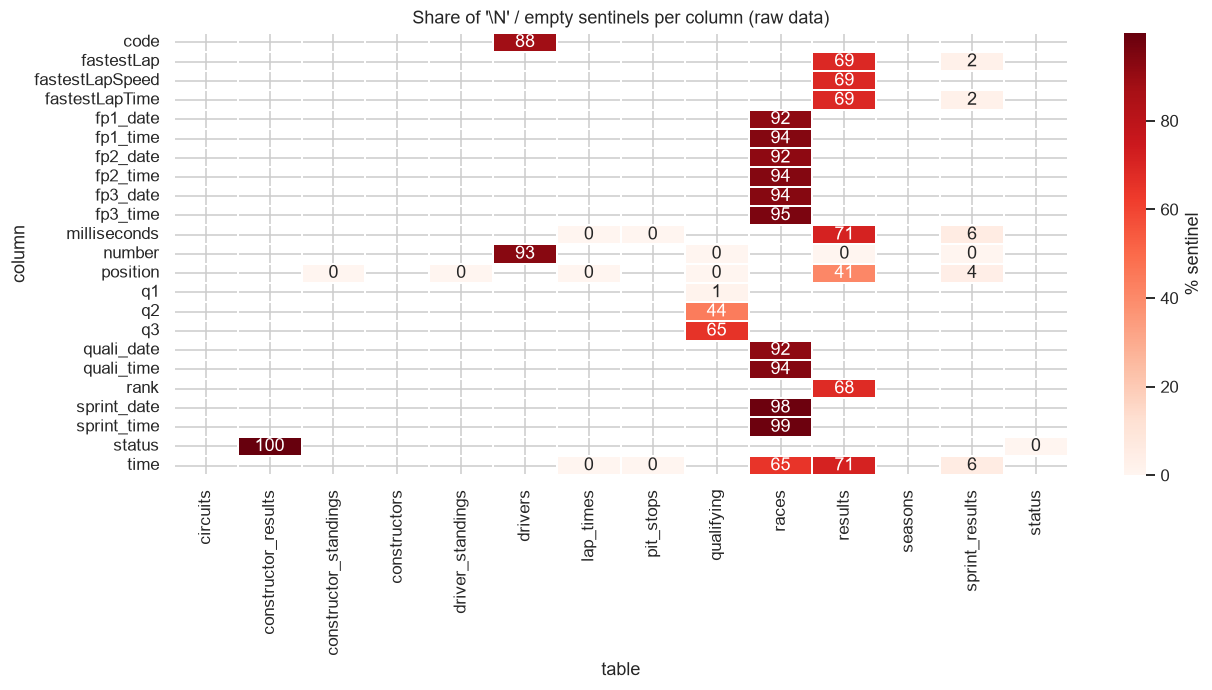

In [6]:
piv = sent_before.pivot_table(index="column", columns="table", values="sentinel_pct")
piv = piv.loc[piv.max(axis=1) > 0]
plt.figure(figsize=(12, max(4, 0.28 * len(piv))))
sns.heatmap(piv, cmap="Reds", annot=True, fmt=".0f", cbar_kws={"label": "% sentinel"}, linewidths=.3)
plt.title(r"Share of '\N' / empty sentinels per column (raw data)")
plt.tight_layout(); savefig("audit_sentinels_heatmap")

### 3.2 Primary keys and foreign keys
- **PK check:** unique **and** non-null (sentinels count as null).
- **Natural-grain check:** the business key each table *should* be unique on (e.g. results should be unique per `(raceId, driverId)`).
- **FK check:** every child value must exist in the parent table. Null FKs are reported separately from orphans.

In [7]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"], "constructors": ["constructorId"],
    "driver_standings": ["driverStandingsId"], "drivers": ["driverId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"], "races": ["raceId"], "results": ["resultId"],
    "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}
NATURAL_KEYS = {
    "results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
    "sprint_results": ["raceId", "driverId"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "constructor_results": ["raceId", "constructorId"],
    "races": ["year", "round"],
}
FOREIGN_KEYS = [  # (child_table, child_col, parent_table, parent_col)
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    *[(t, "raceId", "races", "raceId") for t in ["results", "qualifying", "sprint_results", "lap_times", "pit_stops",
                                                 "driver_standings", "constructor_standings", "constructor_results"]],
    *[(t, "driverId", "drivers", "driverId") for t in ["results", "qualifying", "sprint_results", "lap_times",
                                                       "pit_stops", "driver_standings"]],
    *[(t, "constructorId", "constructors", "constructorId") for t in ["results", "qualifying", "sprint_results",
                                                                      "constructor_standings", "constructor_results"]],
    ("results", "statusId", "status", "statusId"), ("sprint_results", "statusId", "status", "statusId"),
]

def _null(s):
    return s.isna() | s.astype("string").isin(SENTINELS)

def key_report(tables, keys, label):
    rows = []
    for t, cols in keys.items():
        df = tables[t]
        null_rows = df[cols].apply(_null).any(axis=1)
        dup_rows = df.duplicated(cols, keep=False)
        rows.append({"table": t, "key": "+".join(cols), "check": label, "rows": len(df),
                     "null_key_rows": int(null_rows.sum()), "duplicate_key_rows": int(dup_rows.sum()),
                     "ok": bool(null_rows.sum() == 0 and dup_rows.sum() == 0)})
    return pd.DataFrame(rows)

def fk_report(tables):
    rows = []
    for ct, cc, pt, pc in FOREIGN_KEYS:
        child = tables[ct][cc]
        nulls = _null(child)
        parent_vals = set(tables[pt][pc].dropna().astype(str))
        orphan = ~nulls & ~child.astype(str).isin(parent_vals)
        rows.append({"child": f"{ct}.{cc}", "parent": f"{pt}.{pc}", "rows": len(child),
                     "null_fk": int(nulls.sum()), "orphans": int(orphan.sum()),
                     "example_orphans": ", ".join(child[orphan].astype(str).unique()[:5]),
                     "ok": bool(orphan.sum() == 0)})
    return pd.DataFrame(rows)

pk_before = pd.concat([key_report(RAW, PRIMARY_KEYS, "primary key"),
                       key_report(RAW, NATURAL_KEYS, "natural grain")], ignore_index=True)
fk_before = fk_report(RAW)
display(pk_before)
display(fk_before)

,table,key,check,rows,null_key_rows,duplicate_key_rows,ok
0,circuits,circuitId,primary key,77,0,0,True
1,constructor_results,constructorResultsId,primary key,12625,0,0,True
2,constructor_standings,constructorStandingsId,primary key,13391,0,0,True
3,constructors,constructorId,primary key,212,0,0,True
4,driver_standings,driverStandingsId,primary key,34863,0,0,True
5,drivers,driverId,primary key,861,0,0,True
6,lap_times,raceId+driverId+lap,primary key,589081,0,0,True
7,pit_stops,raceId+driverId+stop,primary key,11371,0,0,True
8,qualifying,qualifyId,primary key,10494,0,0,True
9,races,raceId,primary key,1125,0,0,True


,child,parent,rows,null_fk,orphans,example_orphans,ok
0,races.circuitId,circuits.circuitId,1125,0,0,,True
1,races.year,seasons.year,1125,0,0,,True
2,results.raceId,races.raceId,26759,0,0,,True
3,qualifying.raceId,races.raceId,10494,0,0,,True
4,sprint_results.raceId,races.raceId,360,0,0,,True
5,lap_times.raceId,races.raceId,589081,0,0,,True
6,pit_stops.raceId,races.raceId,11371,0,0,,True
7,driver_standings.raceId,races.raceId,34863,0,0,,True
8,constructor_standings.raceId,races.raceId,13391,0,0,,True
9,constructor_results.raceId,races.raceId,12625,0,0,,True


### 3.3 Grain: drivers appearing more than once in the same race ✅

176 result rows belong to 85 duplicated (raceId, driverId) pairs


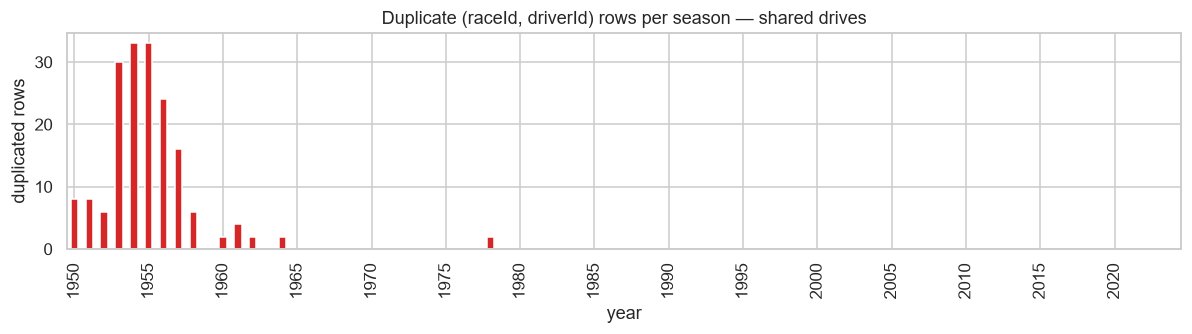

,year,raceId,driverId,constructorId,resultId,grid,positionOrder,points,laps,statusId
13188,1978,540,229,54,13189,0,26,0,0,81
13191,1978,540,229,57,13192,0,29,0,0,97
17362,1964,717,373,172,17363,1,7,0,102,60
24298,1964,717,373,172,24304,1,12,0,54,98
17740,1962,733,465,172,17741,0,22,0,0,54
17743,1962,733,465,97,17744,0,25,0,0,54
17961,1961,742,475,102,17962,20,19,0,56,2
17963,1961,742,475,172,17964,5,21,0,44,23
18062,1961,745,418,172,18063,11,17,0,23,6
24297,1961,745,418,172,24303,15,11,0,92,18


In [8]:
res_raw = RAW["results"].merge(RAW["races"][["raceId", "year"]], on="raceId", how="left")
dup_mask = res_raw.duplicated(["raceId", "driverId"], keep=False)
dups_raw = res_raw[dup_mask].sort_values(["raceId", "driverId", "resultId"])
print(f"{dup_mask.sum()} result rows belong to {dups_raw.groupby(['raceId','driverId']).ngroups} duplicated (raceId, driverId) pairs")

fig, ax = plt.subplots(figsize=(11, 3.2))
dups_raw.groupby("year").size().reindex(sorted(res_raw.year.unique()), fill_value=0).plot.bar(ax=ax, color="tab:red")
ax.set_xticks(ax.get_xticks()[::5]); ax.set_ylabel("duplicated rows"); ax.set_title("Duplicate (raceId, driverId) rows per season — shared drives")
plt.tight_layout(); savefig("audit_duplicates_per_year")

dups_raw[["year", "raceId", "driverId", "constructorId", "resultId", "grid", "positionOrder", "points", "laps", "statusId"]].head(12)

## 4. EDA — before cleaning ✅
Raw-data exploration that motivates the cleaning and later decisions. Values are coerced on the fly (`errors="coerce"`) only for plotting; `RAW` stays untouched.

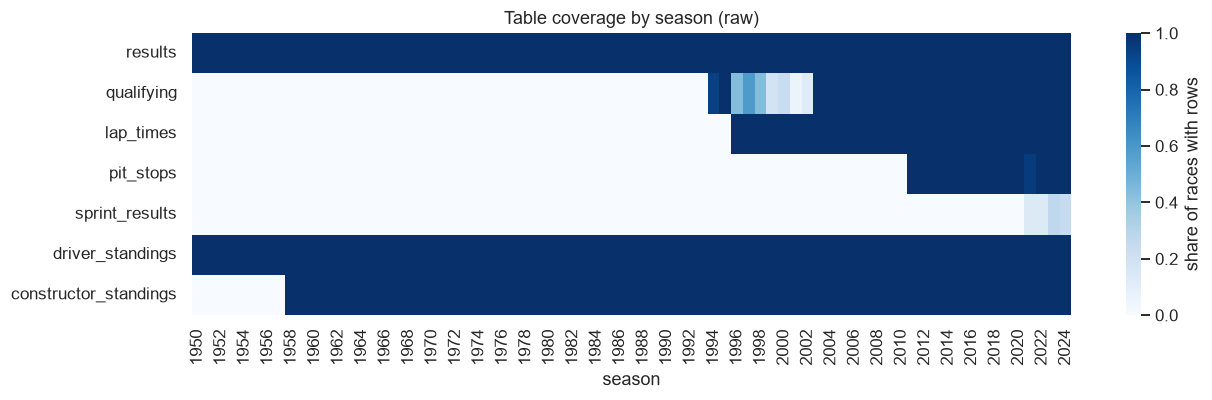

In [9]:
def num(s):  # temporary coercion for plots only
    return pd.to_numeric(s.replace(r"\N", np.nan), errors="coerce")

races_y = RAW["races"].assign(year=num(RAW["races"]["year"]))[["raceId", "year"]]

# Which tables actually have data in which seasons? (coverage drift)
cov = {}
for t in ["results", "qualifying", "lap_times", "pit_stops", "sprint_results", "driver_standings", "constructor_standings"]:
    cov[t] = RAW[t][["raceId"]].drop_duplicates().merge(races_y, on="raceId").groupby("year").size()
cov = pd.DataFrame(cov).reindex(sorted(races_y.year.dropna().unique())).fillna(0)
cov = cov.div(races_y.groupby("year").size(), axis=0)  # share of races covered

plt.figure(figsize=(12, 3.8))
sns.heatmap(cov.T, cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "share of races with rows"})
plt.title("Table coverage by season (raw)"); plt.xlabel("season")
plt.tight_layout(); savefig("eda_raw_table_coverage")

### 4.1 D1 — first season with data, per table
The plan assumes lap times from 1996, pit stops from 2011 and sprints from 2021. We verify this on *this* Kaggle copy instead of trusting it; if it differs, the run stops. Pit-stop features are missing before the first pit season and get a `pit_data_available` flag (§8).

In [10]:
FIRST_SEASON = {t: int(RAW[t][["raceId"]].drop_duplicates().merge(races_y, on="raceId").year.min())
                for t in ["qualifying", "lap_times", "pit_stops", "sprint_results"]}
EXPECTED_FIRST = {"lap_times": 1996, "pit_stops": 2011, "sprint_results": 2021}
display(pd.Series(FIRST_SEASON, name="first season with rows").to_frame().T)
mismatch = {t: (FIRST_SEASON[t], e) for t, e in EXPECTED_FIRST.items() if FIRST_SEASON[t] != e}
assert not mismatch, f"coverage differs from the plan's assumption — stop and review: {mismatch}"

,qualifying,lap_times,pit_stops,sprint_results
first season with rows,1994,1996,2011,2021


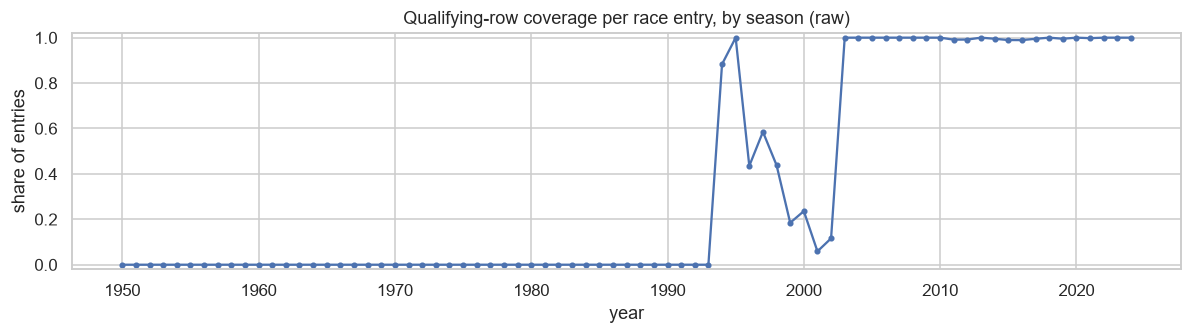

year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
quali_coverage,0.0,0.0,0.0,0.0,0.88,1.0,0.44,0.59,0.44,0.18,0.24,0.06,0.12,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,0.99,1.0,1.0,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [11]:
# Qualifying coverage at the grain we care about: share of race entries that have a qualifying row
res_y = RAW["results"][["raceId", "driverId"]].merge(races_y, on="raceId")
qkeys = set(zip(RAW["qualifying"].raceId, RAW["qualifying"].driverId))
res_y["has_quali"] = [k in qkeys for k in zip(res_y.raceId, res_y.driverId)]
qcov = res_y.groupby("year").has_quali.mean()

fig, ax = plt.subplots(figsize=(11, 3.2))
qcov.plot(ax=ax, marker="o", ms=3); ax.set_ylim(-.02, 1.02)
ax.set_ylabel("share of entries"); ax.set_title("Qualifying-row coverage per race entry, by season (raw)")
plt.tight_layout(); savefig("eda_raw_quali_coverage")
qcov[qcov.index >= 1990].round(2).to_frame("quali_coverage").T

In [12]:
# Raw formats of duration-like strings: one regex "shape" per value, to see what the parser must handle
def shape(v):
    if v in SENTINELS: return "<sentinel>"
    return re.sub(r"\d", "9", v)

for t, c in [("qualifying", "q1"), ("results", "fastestLapTime"), ("pit_stops", "duration"),
             ("lap_times", "time"), ("results", "time")]:
    vc = RAW[t][c].map(shape).value_counts()
    print(f"{t}.{c}: {len(vc)} shapes ->", dict(vc.head(6)))

qualifying.q1: 3 shapes -> {'9:99.999': np.int64(10337), '<sentinel>': np.int64(156), '99:99.999': np.int64(1)}
results.fastestLapTime: 2 shapes -> {'<sentinel>': np.int64(18507), '9:99.999': np.int64(8252)}
pit_stops.duration: 3 shapes -> {'99.999': np.int64(10854), '99:99.999': np.int64(460), '9:99.999': np.int64(57)}


lap_times.time: 3 shapes -> {'9:99.999': np.int64(588455), '99:99.999': np.int64(583), '9:99:99.999': np.int64(43)}
results.time: 22 shapes -> {'<sentinel>': np.int64(19079), '+99.999': np.int64(2973), '+9:99.999': np.int64(1614), '9:99:99.999': np.int64(765), '+9.999': np.int64(732), '+9:99.99': np.int64(281)}


In [13]:
# Categorical hygiene: inconsistent spellings that would break joins (Q2 depends on these)
print("drivers.nationality :", sorted(RAW["drivers"].nationality.unique()))
print()
print("circuits.country   :", sorted(RAW["circuits"].country.unique()))

drivers.nationality : ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

circuits.country   : ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


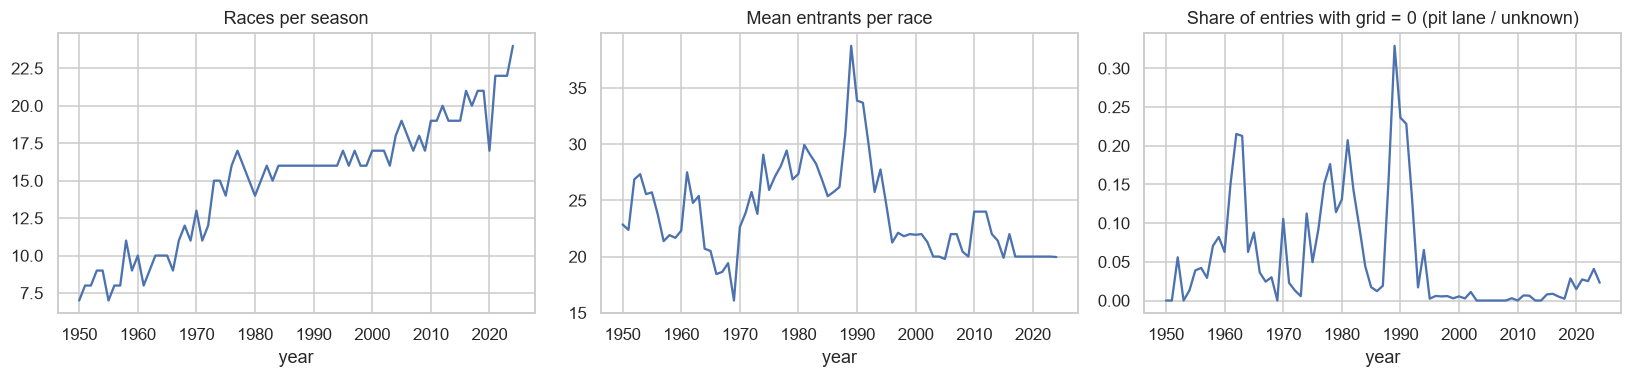

In [14]:
res_num = RAW["results"].assign(**{c: num(RAW["results"][c]) for c in ["grid", "positionOrder", "points"]}).merge(races_y, on="raceId")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
res_num.groupby("year").raceId.nunique().plot(ax=axes[0], title="Races per season")
res_num.groupby(["year", "raceId"]).size().groupby("year").mean().plot(ax=axes[1], title="Mean entrants per race")
(res_num.grid == 0).groupby(res_num.year).mean().plot(ax=axes[2], title="Share of entries with grid = 0 (pit lane / unknown)")
plt.tight_layout(); savefig("eda_raw_season_overview")

✍️ **WRITE-UP (EDA before cleaning)**
- **Sentinels.** `\N` is concentrated in two kinds of column:
  - *structural*: session dates and times (recorded only from 2021), driver codes and numbers (modern drivers only), fastest-lap data (from 2004);
  - *outcome*: `results.time` / `milliseconds` are 71 % missing (everyone not classified on the lead lap) and `position` 41 % (not classified).

  Only `q2` / `q3` are missing for a pre-race reason (knocked out of qualifying). §5.3 labels every column. → fixed steps 3 and 7.
- **Coverage drift.** Qualifying rows start in 1994 but cover only 6–59 % of entries in 1996–2002, and are complete (≥ 99 %) from 2003. Lap times start in 1996, pit stops in 2011 and sprints in 2021 (asserted in §4.1). → modern scope 2006+ (D1), the `pit_data_available` flag, and structural NaN for `reached_q2` / `reached_q3` before 2006.
- **Formats.** Durations appear as `m:ss.sss`, `mm:ss.sss` and `h:mm:ss.sss` (lap times, red-flag pit stops), so one parser handles all three (§5.2). `results.time` has 22 different shapes (absolute times and `+gap`) and is dropped.
- **Categories.** `'Argentinian '` (trailing space, next to `'Argentine'`), `'USA'` vs `'United States'`, and one HTML entity. → strip / unescape and ISO codes (D15).
- **Grain.** 176 rows form 85 duplicated (raceId, driverId) pairs, almost all 1950s shared drives. → D3.
- **`grid = 0`.** In raw data this is mostly non-qualifiers (1,300+ DNQ / DNPQ rows), plus 45 pre-2006 starters with an unknown slot and 77 modern pit-lane starts. → D2, then D5.

## 5. Cleaning ✅
Implements `F1_Cleaning_Plan.md`. Each step has a short note (what, why, decision D#), the code, and a check (assertion or printed count). Every rule writes a row to `outputs/cleaning_log.csv`.

**Cleaning runs on all seasons.** `DATA_SCOPE` only decides which rows enter the modelling table (§8). This way the history features of a 2006 race can still look back at 2005 instead of starting cold.

Order: strip / unescape → sentinels → typing → durations → **D4** Indy → **D2** non-starters → **D3** shared drives → **D5** grid = 0 → **D8** outliers → **D9** lap cleaning → codebooks **D11 / D12 / D15** → **D10** target → **D13 / D7** standings → **D14** sprints → **D16** abnormal races.

In [15]:
CLEANING_LOG = []

def log_step(step, table, rule, column="", rows_before=None, rows_after=None, rows_affected=None,
             cells_affected=None, notes=""):
    if rows_affected is None and rows_before is not None:
        rows_affected = rows_before - rows_after
    CLEANING_LOG.append({"step": step, "table": table, "column": column, "rule": rule,
                         "rows_affected": rows_affected, "cells_affected": cells_affected,
                         "rows_before": rows_before, "rows_after": rows_after, "notes": notes})

def assert_keys(tables, label, skip_grain=()):
    # Fixed step 8: PK unique + non-null, natural grain, FK integrity. Raises instead of just reporting.
    grain = {t: k for t, k in NATURAL_KEYS.items() if t not in skip_grain}
    pk = pd.concat([key_report(tables, PRIMARY_KEYS, "primary key"), key_report(tables, grain, "natural grain")])
    fk = fk_report(tables)
    assert pk.ok.all(), f"[{label}] key check failed:\n{pk[~pk.ok]}"
    assert fk.ok.all(), f"[{label}] FK check failed:\n{fk[~fk.ok]}"
    print(f"✅ PK / grain / FK assertions pass after: {label}" + (f" (grain of {sorted(skip_grain)} not yet fixed)" if skip_grain else ""))

### 5.1 Fixed steps — strip, `html.unescape`, sentinels → `NaN`
Raw strings contain trailing spaces (`'Argentinian '`, §4) and HTML entities (`'Lotus-Pratt &amp; Whitney'`). Either would break joins or display. After that, every sentinel token (`\N`, `""`, `NULL`, `NaN`, `None`) becomes a real missing value.

In [16]:
T = {t: df.copy() for t, df in RAW.items()}   # cleaning happens on copies only

for t, df in T.items():
    n_ws = n_html = n_sent = 0
    for c in df.columns:
        s = df[c].astype("string")
        stripped = s.str.strip()
        has_amp = stripped.str.contains("&", regex=False).fillna(False)
        unesc = stripped.where(~has_amp, stripped[has_amp].map(html.unescape))
        is_sent = unesc.isin(SENTINELS) | unesc.eq("")
        n_ws += int((s != stripped).sum()); n_html += int((stripped != unesc).sum()); n_sent += int(is_sent.sum())
        T[t][c] = unesc.mask(is_sent)
    for rule, n in [("strip whitespace", n_ws), ("html.unescape", n_html), ("sentinel -> NaN", n_sent)]:
        if n:
            log_step("F3", t, rule, cells_affected=n)

pd.DataFrame(CLEANING_LOG)[["table", "rule", "cells_affected"]]

,table,rule,cells_affected
0,constructor_results,sentinel -> NaN,12608
1,constructors,html.unescape,1
2,drivers,strip whitespace,1
3,drivers,sentinel -> NaN,1559
4,qualifying,sentinel -> NaN,11668
5,races,sentinel -> NaN,11349
6,results,sentinel -> NaN,122887
7,sprint_results,sentinel -> NaN,73


### 5.2 Fixed steps — semantic typing and durations in seconds
IDs and counts → `Int64` (an integer type that allows missing values); points and speeds → `float64`; dates → `datetime64`; times of day → `timedelta`. Durations (`q1–q3`, `fastestLapTime`, lap times, pit-stop durations) → seconds, handling both `m:ss.sss` and `h:mm:ss.sss`.
**Check:** missing values after parsing must equal the sentinel count before parsing; any extra missing value would be a parse failure.
`results.time` (and `sprint_results.time`) are **dropped**. They mix the winner's absolute time with gaps (`+5.478`), and they are post-race anyway.

In [17]:
def parse_duration(s):
    # '1:27.452' -> 87.452 s, '1:34:50.616' -> 5690.616 s, '22.5' -> 22.5 s; unparsable -> NaN.
    s = s.astype("string")
    parts = s.str.split(":", expand=True)
    parts = parts.apply(lambda col: pd.to_numeric(col, errors="coerce"))
    n_parts = s.str.count(":").add(1)
    out = pd.Series(np.nan, index=s.index, dtype="float64")
    for n in [1, 2, 3]:
        m = n_parts.eq(n).fillna(False).to_numpy(bool)
        if not m.any():
            continue
        vals = parts.loc[m, list(range(n))].astype("float64").to_numpy(dtype="float64", na_value=np.nan)
        weights = np.array([60.0 ** (n - 1 - i) for i in range(n)])
        out.loc[m] = vals @ weights
    return out

SCHEMA = {  # table: {int: [...], float: [...], date: [...], duration: [...], tod: [...]}
    "circuits": {"int": ["circuitId", "alt"], "float": ["lat", "lng"]},
    "constructor_results": {"int": ["constructorResultsId", "raceId", "constructorId"], "float": ["points"]},
    "constructor_standings": {"int": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"], "float": ["points"]},
    "constructors": {"int": ["constructorId"]},
    "driver_standings": {"int": ["driverStandingsId", "raceId", "driverId", "position", "wins"], "float": ["points"]},
    "drivers": {"int": ["driverId", "number"], "date": ["dob"]},
    "lap_times": {"int": ["raceId", "driverId", "lap", "position", "milliseconds"], "duration": ["time"]},
    "pit_stops": {"int": ["raceId", "driverId", "stop", "lap", "milliseconds"], "duration": ["duration"], "tod": ["time"]},
    "qualifying": {"int": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"], "duration": ["q1", "q2", "q3"]},
    "races": {"int": ["raceId", "year", "round", "circuitId"],
              "date": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
              "tod": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]},
    "results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position", "positionOrder",
                        "laps", "milliseconds", "fastestLap", "rank", "statusId"],
                "float": ["points", "fastestLapSpeed"], "duration": ["fastestLapTime"]},
    "seasons": {"int": ["year"]},
    "sprint_results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                               "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
                       "float": ["points"], "duration": ["fastestLapTime"]},
    "status": {"int": ["statusId"]},
}

for t, spec in SCHEMA.items():
    df = T[t]
    for c in spec.get("int", []):
        df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
    for c in spec.get("float", []):
        df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    for c in spec.get("date", []):
        df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in spec.get("duration", []):
        df[f"{c}_sec"] = parse_duration(df[c])
    for c in spec.get("tod", []):
        df[c] = pd.to_timedelta(df[c], errors="coerce")
    log_step("F4/F5", t, "semantic typing (+ durations -> *_sec)",
             cells_affected=int(len(df) * sum(len(v) for v in spec.values())),
             notes=", ".join(f"{k}: {len(v)}" for k, v in spec.items()))

# Typing must not invent new missing values: compare NaN counts with the sentinel audit
lost = []
for t, spec in SCHEMA.items():
    for kind in ["int", "float", "date", "tod"]:
        for c in spec.get(kind, []):
            raw_missing = _null(RAW[t][c].str.strip()).sum(); now_missing = T[t][c].isna().sum()
            if now_missing != raw_missing:
                lost.append((t, c, int(raw_missing), int(now_missing)))
    for c in spec.get("duration", []):
        raw_missing = _null(RAW[t][c].str.strip()).sum(); now_missing = T[t][f"{c}_sec"].isna().sum()
        if now_missing != raw_missing:
            lost.append((t, f"{c}_sec", int(raw_missing), int(now_missing)))
PARSE_FAILURES = pd.DataFrame(lost, columns=["table", "column", "missing_raw", "missing_after_typing"])
assert PARSE_FAILURES.empty, f"parse failures — list and explain them:\n{PARSE_FAILURES}"
print("✅ missing values after typing == sentinels before typing (0 parse failures)")

# F6: drop the mixed absolute-time / gap column (post-race information anyway)
for t in ["results", "sprint_results"]:
    T[t] = T[t].drop(columns=["time"])
    log_step("F6", t, "drop 'time' (mixes absolute race time with gaps; post-race)", column="time",
             cells_affected=len(T[t]))

✅ missing values after typing == sentinels before typing (0 parse failures)


### 5.3 Fixed step — what kind of missing is it?
Each column with missing values gets one of three labels:
- **structural:** the field didn't exist or wasn't recorded yet.
- **outcome:** missing because of how the race went. These can **never** be features.
- **pre-race-informative:** missing for a reason known before the race (e.g. `q3` missing because the driver was knocked out). These become features.

The table is saved to `outputs/missingness_types.csv`, and the run stops if any column is left unlabelled.

In [18]:
_FASTEST = "fastest-lap data only recorded from 2004 (and post-race anyway)"
_SCHED = "session schedule only recorded from 2021 (sprint fields only on sprint weekends)"
MISSING_TYPES = {  # (table, column): (type, reason)
    ("constructor_results", "status"): ("outcome", "'D' marks a disqualified constructor result; post-race"),
    ("drivers", "number"): ("structural", "permanent car numbers only exist from 2014"),
    ("drivers", "code"): ("structural", "3-letter codes only assigned to modern drivers"),
    **{("qualifying", c): ("pre-race-informative", "no Q1 time set (crash, exclusion, no lap)") for c in ["q1", "q1_sec"]},
    **{("qualifying", c): ("pre-race-informative",
                           "knocked out before this session (2006+); structural before 2006 (single-session formats)")
       for c in ["q2", "q2_sec", "q3", "q3_sec"]},
    ("races", "time"): ("structural", "race start time only recorded from 2005"),
    **{("races", c): ("structural", _SCHED) for c in ["fp1_date", "fp1_time", "fp2_date", "fp2_time", "fp3_date",
                                                      "fp3_time", "quali_date", "quali_time", "sprint_date", "sprint_time"]},
    ("results", "number"): ("structural", "car number not recorded for a few early entries"),
    ("results", "position"): ("outcome", "not classified (retired, DSQ, ...)"),
    ("results", "milliseconds"): ("outcome", "only for classified finishers"),
    **{("results", c): ("structural", _FASTEST) for c in ["fastestLap", "rank", "fastestLapTime", "fastestLapTime_sec",
                                                          "fastestLapSpeed"]},
    **{("sprint_results", c): ("outcome", "sprint not finished / not classified")
       for c in ["position", "milliseconds", "fastestLap", "fastestLapTime", "fastestLapTime_sec"]},
}
rows = []
for t, df in T.items():
    for c in df.columns:
        n = int(df[c].isna().sum())
        if n:
            typ, why = MISSING_TYPES.get((t, c), (None, None))
            rows.append({"table": t, "column": c, "missing": n, "missing_pct": round(100 * n / len(df), 2),
                         "type": typ, "reason": why})
MISSINGNESS = pd.DataFrame(rows)
assert MISSINGNESS.type.notna().all(), f"label these columns:\n{MISSINGNESS[MISSINGNESS.type.isna()]}"
MISSINGNESS["usable_as_feature"] = MISSINGNESS.type.eq("pre-race-informative")
MISSINGNESS.to_csv(OUT_DIR / "missingness_types.csv", index=False)
MISSINGNESS.sort_values(["type", "missing_pct"], ascending=[True, False])

,table,column,missing,missing_pct,type,reason,usable_as_feature
0,constructor_results,status,12608,99.87,outcome,'D' marks a disqualified constructor result; p...,False
22,results,milliseconds,19079,71.30,outcome,only for classified finishers,False
21,results,position,10953,40.93,outcome,"not classified (retired, DSQ, ...)",False
29,sprint_results,milliseconds,20,5.56,outcome,sprint not finished / not classified,False
28,sprint_results,position,15,4.17,outcome,sprint not finished / not classified,False
30,sprint_results,fastestLap,9,2.50,outcome,sprint not finished / not classified,False
31,sprint_results,fastestLapTime,9,2.50,outcome,sprint not finished / not classified,False
32,sprint_results,fastestLapTime_sec,9,2.50,outcome,sprint not finished / not classified,False
5,qualifying,q3,6865,65.42,pre-race-informative,knocked out before this session (2006+); struc...,True
8,qualifying,q3_sec,6865,65.42,pre-race-informative,knocked out before this session (2006+); struc...,True


### 5.4 D4 — exclude the Indianapolis 500 (1950–1960)
Indy counted for the championship on paper only. It was an American oval race with an almost separate set of drivers and a 33-car grid. It would distort home-race analysis (Q2), race counts and form history. All 11 races are removed from `races` **and every table that references them**, so foreign keys stay intact. This only affects the "all" scope.

In [19]:
RACE_CHILDREN = ["results", "qualifying", "sprint_results", "lap_times", "pit_stops",
                 "driver_standings", "constructor_standings", "constructor_results"]
INDY_IDS = set(T["races"].loc[T["races"]["name"].str.contains("Indianapolis", na=False), "raceId"])
print("Indianapolis 500 races:", len(INDY_IDS),
      sorted(T["races"].loc[T["races"].raceId.isin(INDY_IDS), "year"].tolist()))
assert len(INDY_IDS) == 11, "expected 11 Indy 500 races (1950–60)"

for t in ["races", *RACE_CHILDREN]:
    before = len(T[t])
    T[t] = T[t][~T[t].raceId.isin(INDY_IDS)].reset_index(drop=True)
    log_step("D4", t, "exclude Indianapolis 500 (1950–60)", rows_before=before, rows_after=len(T[t]))
assert_keys(T, "D4 Indy exclusion", skip_grain={"results"})

Indianapolis 500 races: 11 [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]


✅ PK / grain / FK assertions pass after: D4 Indy exclusion (grain of ['results'] not yet fixed)


### 5.5 D2 — drop entries with no grid slot at the cutoff
The prediction is made after the grid is set, so an entry that never got a grid slot isn't a prediction row.
- **Dropped:**
  - `Did not qualify`, `Did not prequalify`, `107% Rule` and `Not qualified`, whatever their grid value;
  - `Excluded` or `Withdrew` with `grid == 0`.
- **Kept:** `Withdrew` **with a grid slot**. From 2006 this is how a non-start after qualifying is recorded (there is no "Did not start" label). At the cutoff we *would* have predicted for them, so dropping them would mean choosing rows by what happened later.

In [20]:
STATUS_LABEL = T["status"].set_index("statusId")["status"]
NO_SLOT = {"Did not qualify", "Did not prequalify", "107% Rule", "Not qualified"}   # never had a grid slot
NO_SLOT_IF_GRID0 = {"Excluded", "Withdrew"}                                       # only when grid == 0

res = T["results"]
yr = res.raceId.map(T["races"].set_index("raceId").year)
st = res.statusId.map(STATUS_LABEL)
drop = (st.isin(NO_SLOT) | (st.isin(NO_SLOT_IF_GRID0) & res.grid.eq(0))).fillna(False).to_numpy(bool)

D2_COUNTS = (pd.DataFrame({"status": st[drop], "modern": yr[drop] >= MODERN_FROM})
             .groupby("status").agg(**{"all (1950–2024)": ("modern", "size"), "modern (2006–2024)": ("modern", "sum")}))
kept_withdrew = int((st.eq("Withdrew") & res.grid.gt(0)).sum())
kept_withdrew_modern = int((st.eq("Withdrew") & res.grid.gt(0) & (yr >= MODERN_FROM)).sum())
display(D2_COUNTS)
print(f"Kept: 'Withdrew' with a grid slot -> {kept_withdrew} rows (modern: {kept_withdrew_modern})")

before = len(res)
T["results"] = res[~drop].reset_index(drop=True)
for status, row in D2_COUNTS.iterrows():
    log_step("D2", "results", f"drop non-starter without grid slot: {status}", rows_affected=int(row.iloc[0]),
             notes=f"modern scope: {int(row.iloc[1])}")
log_step("D2", "results", "total non-starters dropped", rows_before=before, rows_after=len(T["results"]),
         notes=f"kept {kept_withdrew} 'Withdrew' rows with grid > 0")
assert_keys(T, "D2 non-starters", skip_grain={"results"})

,all (1950–2024),modern (2006–2024)
status,,
107% Rule,9,0
Did not prequalify,331,0
Did not qualify,1025,4
Excluded,6,0
Withdrew,164,5


Kept: 'Withdrew' with a grid slot -> 84 rows (modern: 12)


✅ PK / grain / FK assertions pass after: D2 non-starters (grain of ['results'] not yet fixed)


### 5.6 D3 — merge shared drives into one row per (raceId, driverId)
Until 1957 a driver could drive several cars in one race. The plan merges them:
- **Pre-race fields** (`grid`, `constructorId`, `number`) come from the **earliest `resultId`**, i.e. the car the driver started in. This avoids choosing them by outcome.
- **Outcome fields:**
  - `points` are summed;
  - `positionOrder` is the best (minimum);
  - `status` comes from the best-placed row;
  - so `podium = 1` if **any** of the driver's cars finished on the podium.

"Keep the earliest row" would throw away real podiums (the old placeholder dropped 18 podium rows and kept only 6). "Keep the best row" would take the *pre-race* fields from a row picked by the result. Nothing to merge from 2006.

In [21]:
PRE_RACE_COLS = ["resultId", "grid", "constructorId", "number"]
KEY = ["raceId", "driverId"]

def merge_shared_drives(res):
    res = res.sort_values("resultId")
    dup = res.duplicated(KEY, keep=False).to_numpy()
    multi = res[dup]
    best = multi.sort_values(["positionOrder", "resultId"]).groupby(KEY).head(1).set_index(KEY)
    first = multi.groupby(KEY).head(1).set_index(KEY)
    merged = best.copy()
    merged[PRE_RACE_COLS] = first[PRE_RACE_COLS]                      # the car the driver started in
    merged["points"] = multi.groupby(KEY).points.sum(min_count=1)
    merged["positionOrder"] = multi.groupby(KEY).positionOrder.min()
    merged["n_cars_merged"] = multi.groupby(KEY).size()
    out = pd.concat([res[~dup].assign(n_cars_merged=1), merged.reset_index()], ignore_index=True)
    out["n_cars_merged"] = out["n_cars_merged"].astype("Int64")
    return out.sort_values("resultId").reset_index(drop=True), multi

before = len(T["results"])
T["results"], SHARED_ROWS = merge_shared_drives(T["results"])
print(f"results: {before} -> {len(T['results'])} rows | {SHARED_ROWS.groupby(KEY).ngroups} (raceId, driverId) "
      f"pairs merged from {len(SHARED_ROWS)} rows")
log_step("D3", "results", "merge shared drives (pre-race fields from earliest resultId; podium if any car)",
         rows_before=before, rows_after=len(T["results"]))
assert not T["results"].duplicated(KEY).any(), "grain still not unique"
assert_keys(T, "D3 shared drives")

# Races whose number of podium rows is not 3 — explain each one
pod = T["results"][T["results"].positionOrder <= 3]
n_pod = pod.groupby("raceId").size()
shared_pos = pod.groupby("raceId").positionOrder.apply(lambda s: s.duplicated().any())
merged_races = set(SHARED_ROWS.raceId)
odd = n_pod[n_pod != 3].rename("podium_rows").to_frame()
odd["explanation"] = [
    "one car shared by several drivers: each is credited with the same podium place" if shared_pos[r]
    else "driver merged from several cars (D3)" if r in merged_races else "UNEXPLAINED — investigate"
    for r in odd.index]
PODIUM_EXCEPTIONS = odd.join(T["races"].set_index("raceId")[["year", "name"]])
assert not PODIUM_EXCEPTIONS.explanation.str.startswith("UNEXPLAINED").any(), PODIUM_EXCEPTIONS
print(f"{len(PODIUM_EXCEPTIONS)} races without exactly 3 podium rows (seasons "
      f"{PODIUM_EXCEPTIONS.year.min()}–{PODIUM_EXCEPTIONS.year.max()}):")
PODIUM_EXCEPTIONS.sort_values("year")

results: 24819 -> 24755 rows | 61 (raceId, driverId) pairs merged from 125 rows


✅ PK / grain / FK assertions pass after: D3 shared drives
15 races without exactly 3 podium rows (seasons 1950–1960):


,podium_rows,explanation,year,name
raceId,,,,
839,4,one car shared by several drivers: each is cre...,1950,Italian Grand Prix
828,5,one car shared by several drivers: each is cre...,1951,French Grand Prix
831,4,one car shared by several drivers: each is cre...,1951,Italian Grand Prix
810,4,one car shared by several drivers: each is cre...,1953,Dutch Grand Prix
806,4,one car shared by several drivers: each is cre...,1954,Italian Grand Prix
804,4,one car shared by several drivers: each is cre...,1954,German Grand Prix
792,5,one car shared by several drivers: each is cre...,1955,Argentine Grand Prix
793,4,one car shared by several drivers: each is cre...,1955,Monaco Grand Prix
784,4,one car shared by several drivers: each is cre...,1956,Argentine Grand Prix


### 5.7 D5 — `grid = 0`
Left as 0, a pit-lane starter would look *better than pole*.
- **2006+:** 0 means a pit-lane start, which really is behind the last slot. So `grid = field_size + 1` and `pitlane_start = 1`.
- **Before 2006:** 0 often just means "not recorded". So `grid = NaN` and `grid_unknown = 1`; inventing a slot would be a guess.
- `field_size = max(rows in the race, highest grid number in the race)`. This handles races with grid numbers above the number of rows (Formula 2 cars mixed into the field in some old races).
- `grid_pct = grid / field_size` makes grid comparable across field sizes.

D2 ran first, so non-qualifiers with grid 0 are already gone. The original value is kept as `grid_raw` for auditing; it is not a feature.

In [22]:
res = T["results"]
yr = res.raceId.map(T["races"].set_index("raceId").year)
rows_per_race = res.groupby("raceId").driverId.transform("size").astype("float64")
max_grid = res.groupby("raceId").grid.transform("max").astype("float64")
field_size = np.fmax(rows_per_race, max_grid)
zero = res.grid.eq(0).fillna(False).to_numpy(bool)
modern = (yr >= MODERN_FROM).to_numpy(bool)

res["grid_raw"] = res["grid"]
res["field_size"] = field_size.astype("Int64")
res["pitlane_start"] = (zero & modern).astype(int)
res["grid_unknown"] = (zero & ~modern).astype(int)
res["grid"] = np.where(zero & modern, field_size + 1, np.where(zero & ~modern, np.nan, res.grid.astype("float64")))
res["grid_pct"] = res["grid"] / field_size

assert res.loc[res.pitlane_start == 1, "grid"].gt(res.loc[res.pitlane_start == 1, "field_size"]).all()
assert (res.grid.isna() == res.grid_unknown.eq(1)).all(), "grid is missing exactly when the pre-2006 slot is unknown"
print(f"pit-lane starts (2006+): {int(res.pitlane_start.sum())} -> grid = field_size + 1 | "
      f"unknown slots (pre-2006): {int(res.grid_unknown.sum())} -> NaN")
print("races where max grid > rows in race:", int((max_grid > rows_per_race).groupby(res.raceId).any().sum()))
log_step("D5", "results", "grid 0 -> field_size + 1 (2006+, pitlane_start = 1)", column="grid",
         cells_affected=int(res.pitlane_start.sum()))
log_step("D5", "results", "grid 0 -> NaN (pre-2006, grid_unknown = 1)", column="grid",
         cells_affected=int(res.grid_unknown.sum()))

pit-lane starts (2006+): 77 -> grid = field_size + 1 | unknown slots (pre-2006): 45 -> NaN
races where max grid > rows in race: 43


### 5.8 D8 — timing outliers (cell → `NaN` + `<col>_outlier` flag; rows are never deleted)
**Change to the plan: hard limits only, for both tables.** The robust z-score `z = 0.6745·(x − median)/MAD` (MAD = median absolute deviation) is still computed within each group, but only so we can report how many cells it *would* flag.
- **Pit stops:** flag stops outside **[1.5 s, 120 s]**. Under 1.5 s is physically impossible; over 120 s means a red-flag suspension or a repair, not a pit stop.
- **Qualifying:** flag times above **2 × the session median**, per race and session.
- **Why not the z-score:** times within a race or session are tightly packed, so |z| > 3.5 also catches **genuine** slow stops and slow laps. In this data it flagged about 13 % of all pit stops and about 500 qualifying times, which would have made slow teams look faster. Both downstream features use medians anyway, so they are robust to the remaining slow-but-real values.
- The driver still raced, so only the cell is cleared, never the row.

In [23]:
def robust_z(x, groups):
    med = x.groupby(groups).transform("median")
    mad = (x - med).abs().groupby(groups).transform("median")
    return 0.6745 * (x - med) / mad.where(mad > 0), med

# ---- pit stops: per-race robust z + hard limits ------------------------------------------
ps = T["pit_stops"]
PIT_BEFORE = ps["duration_sec"].copy()
z, med = robust_z(ps.duration_sec, ps.raceId)
flag_z = (z.abs() > 3.5).fillna(False)                                  # reported only, not applied
flag_hard = ((ps.duration_sec > 120) | (ps.duration_sec < 1.5)).fillna(False)
ps["duration_sec_outlier"] = flag_hard.to_numpy(bool)
ps.loc[ps.duration_sec_outlier, "duration_sec"] = np.nan
log_step("D8", "pit_stops", "outside [1.5 s, 120 s] -> NaN (hard limits only)", column="duration_sec",
         cells_affected=int(ps.duration_sec_outlier.sum()),
         notes=f"robust z > 3.5 would have flagged {int(flag_z.sum())} ({flag_z.mean():.1%}) - not applied")

# ---- qualifying: hard limit only (> 2 x session median) -----------------------------------
q = T["qualifying"]
Q_BEFORE = q[["raceId", "q1_sec", "q2_sec", "q3_sec"]].copy()
qrows = []
for c in ["q1_sec", "q2_sec", "q3_sec"]:
    zq, medq = robust_z(q[c], q.raceId)
    flag = (q[c] > 2 * medq).fillna(False).to_numpy(bool)
    q[f"{c}_outlier"] = flag
    qrows.append({"column": c, "flagged_hard_limit": int(flag.sum()),
                  "would_be_flagged_by_z>3.5": int((zq.abs() > 3.5).sum())})
    log_step("D8", "qualifying", "time > 2 x session median -> NaN", column=c, cells_affected=int(flag.sum()))
    q.loc[flag, c] = np.nan
display(pd.DataFrame(qrows).set_index("column"))

summary = pd.DataFrame({"pit_stops.duration_sec": [len(ps), int(flag_z.sum()), int(flag_hard.sum()),
                                                   int(ps.duration_sec_outlier.sum())]},
                       index=["values", "would be flagged by z > 3.5", "hard limits", "set to NaN"]).T
display(summary)

# Examples, including the 16:42.640 Q1 time (raceId 255) and red-flag pit stops
ex_q = (Q_BEFORE.assign(driverId=q.driverId)[q[["q1_sec_outlier", "q2_sec_outlier", "q3_sec_outlier"]].any(axis=1)]
        .head(8))
display(ex_q)
assert 255 in set(ex_q.raceId) or q.loc[q.raceId.eq(255), "q1_sec_outlier"].any(), "expected raceId 255 Q1 outlier"
display(ps.assign(duration_raw=PIT_BEFORE)[ps.duration_sec_outlier]
          .sort_values("duration_raw", ascending=False)[["raceId", "driverId", "stop", "lap", "duration", "duration_raw"]].head(6))

,flagged_hard_limit,would_be_flagged_by_z>3.5
column,,
q1_sec,1,509
q2_sec,0,120
q3_sec,0,74


,values,would be flagged by z > 3.5,hard limits,set to NaN
pit_stops.duration_sec,11371,1491,481,481


,raceId,q1_sec,q2_sec,q3_sec,driverId
2567,255,1002.64,NaN,NaN,87


,raceId,driverId,stop,lap,duration,duration_raw
9156,1083,840,1,1,51:09.017,3069.017
9155,1083,20,1,1,51:07.301,3067.301
9157,1083,854,1,1,51:05.174,3065.174
9154,1083,825,1,1,51:03.613,3063.613
9152,1083,817,1,1,51:03.314,3063.314
9151,1083,822,1,1,50:55.732,3055.732


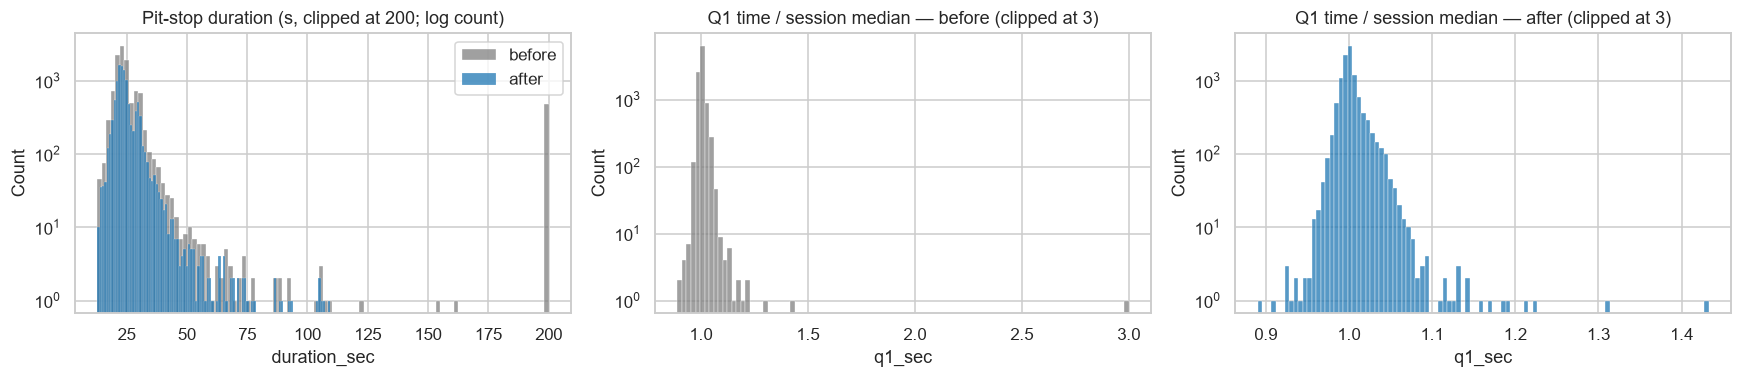

In [24]:
# Before / after distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
sns.histplot(PIT_BEFORE.clip(upper=200), bins=100, ax=axes[0], color="grey", label="before")
sns.histplot(ps.duration_sec, bins=100, ax=axes[0], color="tab:blue", label="after"); axes[0].set_yscale("log")
axes[0].set_title("Pit-stop duration (s, clipped at 200; log count)"); axes[0].legend()
for ax, (label, frame) in zip(axes[1:], [("before", Q_BEFORE), ("after", q)]):
    ratio = frame.q1_sec / frame.groupby("raceId").q1_sec.transform("median")
    sns.histplot(ratio.clip(upper=3), bins=100, ax=ax, color="grey" if label == "before" else "tab:blue")
    ax.set_yscale("log"); ax.set_title(f"Q1 time / session median — {label} (clipped at 3)")
plt.tight_layout(); savefig("cleaning_outliers_before_after")

### 5.9 D9 — clean lap times into a pace measure (used **only** for past-race features)
Finishing position mixes pace with luck. Clean lap pace measures how fast the car and driver actually were. Per race, remove:
1. lap 1 (standing start and traffic);
2. pit in-laps and out-laps (matched with `pit_stops` on the lap and the lap after);
3. laps slower than **107 %** of the race median, computed after removing 1 and 2. These are safety-car, VSC and red-flag laps.

Then `pace_ratio` = driver's median clean lap ÷ the best driver median in that race (1.000 = fastest). Drivers with fewer than 5 clean laps get `NaN`. The current race's laps are never used for its own prediction (§8 shifts by one race).
Note: pit data only starts in 2011, so for 1996–2010 rule 3 is what removes in/out laps (they are roughly 20 s slower).

In [25]:
lt = T["lap_times"][["raceId", "driverId", "lap", "time_sec"]].copy()
pits = T["pit_stops"][["raceId", "driverId", "lap"]]
pit_keys = pd.concat([pits, pits.assign(lap=pits.lap + 1)]).drop_duplicates().assign(pit_lap=1)
lt = lt.merge(pit_keys, on=["raceId", "driverId", "lap"], how="left")

f1 = lt.lap.eq(1).to_numpy(bool)
f2 = lt.pit_lap.notna().to_numpy(bool) & ~f1
keep12 = ~f1 & ~f2
race_med = lt[keep12].groupby("raceId").time_sec.median()
f3 = keep12 & (lt.time_sec > 1.07 * lt.raceId.map(race_med)).fillna(False).to_numpy(bool)
clean_laps = lt[keep12 & ~f3]

LAP_FILTERS = pd.Series({"lap rows": len(lt), "lap 1": int(f1.sum()), "pit in/out laps": int(f2.sum()),
                         "> 107% of race median": int(f3.sum()), "clean laps kept": len(clean_laps)})
display(LAP_FILTERS.to_frame("laps").T)
for rule, n in LAP_FILTERS.iloc[1:4].items():
    log_step("D9", "lap_times", f"remove {rule}", rows_affected=int(n), notes="removed from pace calculation only")

PACE = (clean_laps.groupby(["raceId", "driverId"]).time_sec
        .agg(drv_median="median", n_clean_laps="size").reset_index())
valid = PACE.n_clean_laps >= 5
best = PACE[valid].groupby("raceId").drv_median.min()
PACE["pace_ratio"] = np.where(valid, PACE.drv_median / PACE.raceId.map(best), np.nan)
assert np.allclose(PACE[valid].groupby("raceId").pace_ratio.min(), 1.0)
print(f"pace_ratio for {int(valid.sum())} driver-races ({int((~valid).sum())} with < 5 clean laps -> NaN); "
      f"median {PACE.pace_ratio.median():.4f}, 95th pct {PACE.pace_ratio.quantile(.95):.4f}")

,lap rows,lap 1,pit in/out laps,> 107% of race median,clean laps kept
laps,589081,11041,21877,42680,513483


pace_ratio for 10655 driver-races (180 with < 5 clean laps -> NaN); median 1.0176, 95th pct 1.0499


### 5.10 D11 — status codebook → `codebooks/status_map.csv`
Every one of the status labels is mapped to exactly one group: `finished`, `lapped`, `mechanical`, `incident`, `non_start`, `disqualified` or `ambiguous`.
- `incident` also covers **driver-related** stops (illness, injury). The definition of a mechanical retirement excludes "failures caused by … the driver".
- `ambiguous` holds labels that can be either a car failure or contact / team / driver: punctures, wheels, wings, "Retired", "Technical", …
- Q3 is computed **both ways**: ambiguous counted as not mechanical (a), and as mechanical (b).
- Finish and reliability features use this codebook: `finished` or `lapped` = finished.

The full mapping is printed below and saved to `codebooks/status_map.csv`; judgement calls are in the `note` column.

In [26]:
STATUS_GROUPS = {
    "finished": {"Finished"},
    "mechanical": {
        "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension", "Brakes",
        "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure", "Throttle",
        "Steering", "Electronics", "Exhaust", "Oil leak", "Water leak", "Fuel pump", "Track rod", "Oil pressure",
        "Engine fire", "Engine misfire", "Pneumatics", "Wheel bearing", "Fuel system", "Oil line", "Power loss",
        "Drivetrain", "Ignition", "Battery", "Halfshaft", "Crankshaft", "Alternator", "Oil pump", "Fuel leak",
        "Injection", "Distributor", "Turbo", "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle",
        "Water pipe", "Magneto", "Supercharger", "Power Unit", "ERS", "Brake duct", "Cooling system",
        "Heat shield fire", "Launch control"},
    "incident": {"Accident", "Collision", "Spun off", "Collision damage", "Fatal accident",
                 "Illness", "Injury", "Injured", "Physical", "Eye injury", "Driver unwell"},
    "non_start": {"Withdrew", "Did not qualify", "Did not prequalify", "107% Rule", "Not qualified", "Did not start"},
    "disqualified": {"Disqualified", "Excluded", "Underweight"},
    "ambiguous": {"Retired", "Technical", "Puncture", "Tyre", "Tyre puncture", "Wheel", "Wheel nut", "Wheel rim",
                  "Damage", "Debris", "Vibrations", "Front wing", "Rear wing", "Broken wing", "Undertray", "Handling",
                  "Seat", "Driver Seat", "Out of fuel", "Fuel", "Refuelling", "Fuel rig", "Fire", "Stalled", "Safety",
                  "Safety concerns", "Safety belt", "Not restarted", "Chassis", "Not classified"},
}
STATUS_NOTES = {
    "Launch control": "electronic system failure at the start -> mechanical",
    "Heat shield fire": "component failure -> mechanical",
    "Illness": "driver-related, not a car failure -> incident", "Injury": "driver-related -> incident",
    "Injured": "driver-related -> incident", "Physical": "driver-related -> incident",
    "Eye injury": "driver-related -> incident", "Driver unwell": "driver-related -> incident",
    "Underweight": "car below minimum weight: a regulation decision -> disqualified",
    "Excluded": "regulation decision -> disqualified (Excluded with grid 0 already dropped by D2)",
    "Withdrew": "kept in the modelling table when grid > 0 (D2) but not a race start (Q3 denominator)",
    "Puncture": "debris/contact or tyre failure", "Tyre": "tyre failure or damage", "Wheel": "failure or bad pit stop",
    "Wheel nut": "usually a pit-stop (team) error", "Wheel rim": "failure or kerb/contact damage",
    "Damage": "usually contact", "Debris": "external cause", "Front wing": "usually contact",
    "Rear wing": "failure or contact", "Broken wing": "usually contact", "Undertray": "failure or kerb damage",
    "Out of fuel": "team miscalculation or fuel-system failure", "Fuel": "unclear: fuel system or fuel quantity",
    "Refuelling": "pit equipment / team error", "Fuel rig": "pit equipment / team error", "Fire": "cause unknown",
    "Stalled": "driver error or anti-stall failure", "Safety": "unclear", "Safety concerns": "team withdrew the car",
    "Safety belt": "equipment failure or driver", "Not restarted": "did not take a restart (red flag) - cause unknown",
    "Chassis": "failure or crash damage", "Not classified": "started, too few laps completed - cause unknown",
    "Retired": "no cause recorded", "Technical": "no detail recorded", "Handling": "car problem or driver",
    "Vibrations": "car problem or damage", "Seat": "unclear", "Driver Seat": "unclear",
}

overlap = [(a, b, STATUS_GROUPS[a] & STATUS_GROUPS[b]) for a in STATUS_GROUPS for b in STATUS_GROUPS
           if a < b and STATUS_GROUPS[a] & STATUS_GROUPS[b]]
assert not overlap, f"labels in two groups: {overlap}"

def status_group(label):
    if re.fullmatch(r"\+\d+ Laps?", label):
        return "lapped"
    return next((g for g, labels in STATUS_GROUPS.items() if label in labels), None)

n_used = T["results"].statusId.value_counts()
STATUS_MAP = T["status"].assign(group=lambda d: d.status.map(status_group),
                                note=lambda d: d.status.map(STATUS_NOTES).fillna(""),
                                n_results=lambda d: d.statusId.map(n_used).fillna(0).astype(int))
assert STATUS_MAP.group.notna().all(), f"unmapped statuses: {STATUS_MAP[STATUS_MAP.group.isna()].status.tolist()}"
assert not STATUS_MAP.status.duplicated().any()
STATUS_MAP.to_csv(CB_DIR / "status_map.csv", index=False)
STATUS_GROUP_BY_ID = STATUS_MAP.set_index("statusId").group
log_step("D11", "status", "status codebook: every label -> one group", cells_affected=len(STATUS_MAP),
         notes=STATUS_MAP.group.value_counts().to_dict().__repr__())

print(STATUS_MAP.group.value_counts().to_string(), "\n")
for g in ["mechanical", "ambiguous", "incident", "non_start", "disqualified"]:
    d = STATUS_MAP[STATUS_MAP.group == g].sort_values("n_results", ascending=False)
    print(f"{g.upper()} ({len(d)}): " + ", ".join(f"{s} ({n})" for s, n in zip(d.status, d.n_results)))
STATUS_MAP[STATUS_MAP.note.ne("")][["status", "group", "note", "n_results"]].sort_values("group")

group
mechanical      57
lapped          33
ambiguous       30
incident        11
non_start        4
disqualified     3
finished         1 

MECHANICAL (57): Engine (1983), Gearbox (803), Suspension (425), Electrical (316), Transmission (309), Brakes (245), Clutch (204), Fuel system (153), Turbo (144), Hydraulics (139), Overheating (128), Ignition (124), Oil leak (111), Throttle (108), Halfshaft (99), Oil pressure (81), Fuel pump (60), Differential (59), Steering (46), Radiator (44), Fuel leak (44), Power Unit (42), Injection (35), Wheel bearing (34), Fuel pressure (34), Alternator (31), Water leak (31), Exhaust (29), Mechanical (29), Driveshaft (25), Battery (17), Axle (15), Heat shield fire (15), Power loss (15), Distributor (14), Oil pump (13), Electronics (11), Oil pipe (11), Water pressure (9), Magneto (8), Water pump (7), ERS (5), Pneumatics (4), Spark plugs (3), Water pipe (3), Fuel pipe (3), Track rod (2), Supercharger (2), Drivetrain (2), Crankshaft (1), Engine misfire (1), Oi

,status,group,note,n_results
26,Tyre,ambiguous,tyre failure or damage,54
135,Debris,ambiguous,external cause,1
134,Damage,ambiguous,usually contact,2
133,Seat,ambiguous,unclear,1
92,Safety belt,ambiguous,equipment failure or driver,1
89,Not restarted,ambiguous,did not take a restart (red flag) - cause unknown,1
88,Safety concerns,ambiguous,team withdrew the car,2
84,Stalled,ambiguous,driver error or anti-stall failure,1
82,Chassis,ambiguous,failure or crash damage,29
77,Safety,ambiguous,unclear,2


### 5.11 D12 — constructor lineage → `codebooks/constructor_lineage.csv`
Each name is a separate `constructorId`, so team history would reset at every rename. For example, Racing Point 2019 would look like a brand-new team, although it is Force India's factory and staff. `constructor_family` is used for:
- rolling team-form features;
- round-1 standings matching (D7);
- Q3 grouping.

The original name is used for display only. Unmapped constructors map to themselves.

**Some IDs are reused by unrelated teams:**
- `51` is the 1950–85 Alfa Romeo works team *and* the 2019–23 Sauber-run Alfa Romeo;
- `131` is the 1954–55 Mercedes works team *and* Mercedes 2010+;
- `4` is the 1977–85 Renault works team *and* the Enstone Renault from 2002.

So lineage rules carry a year range. Judgement calls are marked in `note`.

In [27]:
LINEAGE = [  # (constructorId, family, year_from, year_to, note)
    (18, "Faenza", None, None, "Minardi; bought by Red Bull for 2006"),
    (5, "Faenza", None, None, "Toro Rosso"),
    (213, "Faenza", None, None, "AlphaTauri (Toro Rosso renamed 2020)"),
    (215, "Faenza", None, None, "RB (AlphaTauri renamed 2024)"),
    (17, "Silverstone", None, None, "Jordan"),
    (13, "Silverstone", None, None, "MF1 (Midland bought Jordan for 2006)"),
    (14, "Silverstone", None, None, "Spyker MF1 (renamed late 2006)"),
    (12, "Silverstone", None, None, "Spyker"),
    (10, "Silverstone", None, None, "Force India (bought Spyker for 2008)"),
    (211, "Silverstone", None, None, "Racing Point: JUDGEMENT CALL - 2018 administration created a new entry, but same factory and staff"),
    (117, "Silverstone", None, None, "Aston Martin (Racing Point renamed 2021)"),
    (15, "Hinwil", None, None, "Sauber (incl. the 2024 Kick Sauber entry)"),
    (2, "Hinwil", None, None, "BMW Sauber (BMW bought Sauber 2006-09)"),
    (51, "Hinwil", 2019, 2023, "Alfa Romeo = Sauber rebranded; id 51 is shared with the unrelated 1950-85 Alfa Romeo works team"),
    (53, "Enstone", None, None, "Toleman: JUDGEMENT CALL - bought by Benetton for 1986, same Enstone factory"),
    (22, "Enstone", None, None, "Benetton"),
    (4, "Enstone", 2002, None, "Renault 2002-11 and 2016-20; id 4 is shared with the unrelated 1977-85 Renault works team"),
    (208, "Enstone", None, None, "Lotus F1 (Renault team renamed 2012)"),
    (214, "Enstone", None, None, "Alpine (Renault renamed 2021)"),
    (16, "Brackley", None, None, "BAR"),
    (11, "Brackley", None, None, "Honda (bought BAR for 2006)"),
    (23, "Brackley", None, None, "Brawn: JUDGEMENT CALL - management buy-out of Honda; same factory, new owner, new car"),
    (131, "Brackley", 2010, None, "Mercedes (bought Brawn); id 131 is shared with the 1954-55 Mercedes works team"),
    (24, "Milton Keynes", None, None, "Stewart"),
    (19, "Milton Keynes", None, None, "Jaguar (Ford bought Stewart for 2000)"),
    (9, "Milton Keynes", None, None, "Red Bull (bought Jaguar for 2005)"),
    (166, "Banbury", None, None, "Virgin"),
    (206, "Banbury", None, None, "Marussia (Virgin renamed 2012)"),
    (209, "Banbury", None, None, "Manor Marussia: JUDGEMENT CALL - rescued from administration for 2015"),
    (205, "Caterham", None, None, "Lotus Racing / Team Lotus 2010-11: JUDGEMENT CALL - unrelated to the old Team Lotus"),
    (207, "Caterham", None, None, "Caterham (Team Lotus renamed 2012)"),
    (21, "Arrows", None, None, "Arrows"),
    (29, "Arrows", None, None, "Footwork = Arrows renamed 1991-96"),
    (27, "Ligier/Prost", None, None, "Ligier"),
    (20, "Ligier/Prost", None, None, "Prost: JUDGEMENT CALL - bought Ligier for 1997, same Magny-Cours base"),
    (41, "March/Leyton House", None, None, "Leyton House = March renamed 1990-91"),
    (37, "March/Leyton House", 1987, None, "March 1987-92 entry; earlier March ids/years are different works teams"),
]
# Deliberately NOT linked: Tyrrell -> BAR (BAR bought the entry but built a new team in a new factory).

CON_NAME = T["constructors"].set_index("constructorId")["name"]

def constructor_family(cids, years):
    cids, years = pd.Series(cids).reset_index(drop=True), pd.Series(years).reset_index(drop=True)
    fam = cids.map(CON_NAME).astype(object)                      # default: the constructor itself
    for cid, family, y0, y1, _ in LINEAGE:
        m = (cids.eq(cid) & years.ge(y0 or 0) & years.le(y1 or 9999)).fillna(False).to_numpy(bool)
        fam[m] = family
    return fam.to_numpy()

lin = pd.DataFrame(LINEAGE, columns=["constructorId", "constructor_family", "year_from", "year_to", "note"])
CONSTRUCTOR_LINEAGE = (T["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor_name"})
                       .merge(lin, on="constructorId", how="left"))
CONSTRUCTOR_LINEAGE["constructor_family"] = CONSTRUCTOR_LINEAGE.constructor_family.fillna(CONSTRUCTOR_LINEAGE.constructor_name)
CONSTRUCTOR_LINEAGE["note"] = CONSTRUCTOR_LINEAGE.note.fillna("unmapped -> itself")
assert not CONSTRUCTOR_LINEAGE.duplicated(["constructorId", "year_from"]).any()
assert set(lin.constructorId) <= set(T["constructors"].constructorId), "lineage references an unknown constructorId"
CONSTRUCTOR_LINEAGE.to_csv(CB_DIR / "constructor_lineage.csv", index=False)
log_step("D12", "constructors", "constructor lineage -> constructor_family", cells_affected=len(lin),
         notes=f"{lin.constructor_family.nunique()} families, {int(lin.note.str.contains('JUDGEMENT').sum())} judgement calls")
CONSTRUCTOR_LINEAGE[CONSTRUCTOR_LINEAGE.note.ne("unmapped -> itself")].sort_values(["constructor_family", "constructorId"])

,constructorId,constructor_name,constructor_family,year_from,year_to,note
20,21,Arrows,Arrows,NaN,NaN,Arrows
28,29,Footwork,Arrows,NaN,NaN,Footwork = Arrows renamed 1991-96
164,166,Virgin,Banbury,NaN,NaN,Virgin
203,206,Marussia,Banbury,NaN,NaN,Marussia (Virgin renamed 2012)
206,209,Manor Marussia,Banbury,NaN,NaN,Manor Marussia: JUDGEMENT CALL - rescued from ...
10,11,Honda,Brackley,NaN,NaN,Honda (bought BAR for 2006)
15,16,BAR,Brackley,NaN,NaN,BAR
22,23,Brawn,Brackley,NaN,NaN,Brawn: JUDGEMENT CALL - management buy-out of ...
129,131,Mercedes,Brackley,2010.0,NaN,Mercedes (bought Brawn); id 131 is shared with...
202,205,Lotus,Caterham,NaN,NaN,Lotus Racing / Team Lotus 2010-11: JUDGEMENT C...


### 5.12 D15 — nationalities and circuit countries → ISO-3166 alpha-3
Driver nationality is a demonym ("British") and circuit country is a name ("UK", "USA" / "United States", "UAE"). Mapping both to one standard code makes the home-race join in Q2 exact.
Judgement calls:
- East German → DEU (there was only ever a German GP);
- Rhodesian → ZWE;
- dual nationality ("American-Italian") → the first one listed.

The run stops if any value on either side is left unmapped.

In [28]:
NATIONALITY_ISO = {
    "American": "USA", "American-Italian": "USA", "Argentine": "ARG", "Argentine-Italian": "ARG", "Argentinian": "ARG",
    "Australian": "AUS", "Austrian": "AUT", "Belgian": "BEL", "Brazilian": "BRA", "British": "GBR", "Canadian": "CAN",
    "Chilean": "CHL", "Chinese": "CHN", "Colombian": "COL", "Czech": "CZE", "Danish": "DNK", "Dutch": "NLD",
    "East German": "DEU", "Finnish": "FIN", "French": "FRA", "German": "DEU", "Hungarian": "HUN", "Indian": "IND",
    "Indonesian": "IDN", "Irish": "IRL", "Italian": "ITA", "Japanese": "JPN", "Liechtensteiner": "LIE",
    "Malaysian": "MYS", "Mexican": "MEX", "Monegasque": "MCO", "New Zealander": "NZL", "Polish": "POL",
    "Portuguese": "PRT", "Rhodesian": "ZWE", "Russian": "RUS", "South African": "ZAF", "Spanish": "ESP",
    "Swedish": "SWE", "Swiss": "CHE", "Thai": "THA", "Uruguayan": "URY", "Venezuelan": "VEN",
}
COUNTRY_ISO = {
    "Argentina": "ARG", "Australia": "AUS", "Austria": "AUT", "Azerbaijan": "AZE", "Bahrain": "BHR", "Belgium": "BEL",
    "Brazil": "BRA", "Canada": "CAN", "China": "CHN", "France": "FRA", "Germany": "DEU", "Hungary": "HUN",
    "India": "IND", "Italy": "ITA", "Japan": "JPN", "Korea": "KOR", "Malaysia": "MYS", "Mexico": "MEX",
    "Monaco": "MCO", "Morocco": "MAR", "Netherlands": "NLD", "Portugal": "PRT", "Qatar": "QAT", "Russia": "RUS",
    "Saudi Arabia": "SAU", "Singapore": "SGP", "South Africa": "ZAF", "Spain": "ESP", "Sweden": "SWE",
    "Switzerland": "CHE", "Turkey": "TUR", "UAE": "ARE", "UK": "GBR", "USA": "USA", "United States": "USA",
}
pd.Series(NATIONALITY_ISO, name="iso3").rename_axis("nationality").to_csv(CB_DIR / "nationality_iso.csv")
pd.Series(COUNTRY_ISO, name="iso3").rename_axis("country").to_csv(CB_DIR / "country_iso.csv")

T["drivers"]["nationality_iso"] = T["drivers"].nationality.map(NATIONALITY_ISO)
T["circuits"]["country_iso"] = T["circuits"].country.map(COUNTRY_ISO)
unmapped_nat = sorted(T["drivers"].loc[T["drivers"].nationality_iso.isna(), "nationality"].unique())
unmapped_cty = sorted(T["circuits"].loc[T["circuits"].country_iso.isna(), "country"].unique())
assert not unmapped_nat and not unmapped_cty, (unmapped_nat, unmapped_cty)
log_step("D15", "drivers", "nationality -> ISO alpha-3", column="nationality_iso", cells_affected=len(T["drivers"]))
log_step("D15", "circuits", "country -> ISO alpha-3", column="country_iso", cells_affected=len(T["circuits"]))
print(f"✅ 0 unmapped: {T['drivers'].nationality.nunique()} nationalities -> {T['drivers'].nationality_iso.nunique()} codes; "
      f"{T['circuits'].country.nunique()} countries -> {T['circuits'].country_iso.nunique()} codes")

✅ 0 unmapped: 43 nationalities -> 39 codes; 35 countries -> 34 codes


### 5.13 D10 — target
`podium = positionOrder <= 3`, computed **after** D3. `positionOrder` is the only position column filled for every row, and it already reflects post-race disqualifications.
**Checks:** no missing target values, and in the modern era every race has exactly 3 podium rows. This also checks D2/D3 indirectly: a dropped podium row or a duplicate would show up here.

In [29]:
res = T["results"]
res["podium"] = (res.positionOrder <= 3).astype("Int64")
res["status_group"] = res.statusId.map(STATUS_GROUP_BY_ID)
assert res.podium.notna().all() and res.status_group.notna().all()
yr = res.raceId.map(T["races"].set_index("raceId").year)
per_race = res[yr >= MODERN_FROM].groupby("raceId").podium.sum()
bad = per_race[per_race != 3]
assert bad.empty, f"modern races without exactly 3 podium rows:\n{bad}"
print(f"✅ target has no NaN; all {len(per_race)} modern races have exactly 3 podium rows | "
      f"overall podium rate {res.podium.mean():.4f}")

✅ target has no NaN; all 375 modern races have exactly 3 podium rows | overall podium rate 0.1357


### 5.14 D13 + D7 — standings as of *before* the race
- **D13:** raw championship points are not comparable across eras. Examples: the 2010 scoring change (a win went from 10 to 25 points), 2014 double points, half-points races, 17- vs 24-race seasons. So for drivers and constructors we use:
  - `champ_rank`;
  - `pts_share = points / leader_points` (0 if the leader has 0);
  - `gap_to_leader_share = 1 − pts_share`.
- **Source:** the standings after the **previous round**.
- **D7, round 1:** use **last season's final standings** and set `is_round_1 = 1`. Constructors are matched through `constructor_family`, so a renamed team keeps its history.
- **Leakage check:** the source race must be dated before the race being predicted.

In [30]:
RACE_ORDER = T["races"][["raceId", "year", "round", "date"]].sort_values(["year", "round"]).reset_index(drop=True)
RACE_ORDER["prev_raceId"] = RACE_ORDER.groupby("year").raceId.shift(1)
season_final = RACE_ORDER.groupby("year").raceId.last()
RACE_ORDER["is_round_1"] = RACE_ORDER.prev_raceId.isna().astype(int)
RACE_ORDER["standings_src_raceId"] = RACE_ORDER.prev_raceId.fillna((RACE_ORDER.year - 1).map(season_final)).astype("Int64")

race_date = T["races"].set_index("raceId").date
src_date = RACE_ORDER.standings_src_raceId.map(race_date)
has_src = RACE_ORDER.standings_src_raceId.notna()
assert (src_date[has_src] < RACE_ORDER.date[has_src]).all(), "standings source must be dated before the race"
assert (RACE_ORDER.loc[RACE_ORDER.is_round_1.eq(1) & has_src, "standings_src_raceId"].map(T["races"].set_index("raceId").year)
        == RACE_ORDER.loc[RACE_ORDER.is_round_1.eq(1) & has_src, "year"] - 1).all()

def standings_shares(st, key, prefix):
    st = st[["raceId", key, "points", "position"]].copy()
    leader = st.groupby("raceId").points.transform("max")
    st[f"{prefix}_champ_rank"] = st.position.astype("float64")
    st[f"{prefix}_pts_share"] = np.where(leader > 0, st.points / leader, 0.0)
    st[f"{prefix}_gap_to_leader_share"] = 1 - st[f"{prefix}_pts_share"]
    return st.drop(columns=["points", "position"]).rename(columns={"raceId": "standings_src_raceId"})

DS = standings_shares(T["driver_standings"], "driverId", "drv")
# Constructor standings per FAMILY. Only case with two names in one table: MF1 -> Spyker MF1 (renamed late 2006);
# their points are summed and the better-placed name's rank is kept.
cst = T["constructor_standings"].assign(con_family=lambda d: constructor_family(
    d.constructorId, d.raceId.map(T["races"].set_index("raceId").year)))
dup_fam = cst[cst.duplicated(["raceId", "con_family"], keep=False)]
print("standings tables with two names of one family:",
      dup_fam.groupby("con_family").raceId.nunique().to_dict() or "none")
cst = cst.groupby(["raceId", "con_family"], as_index=False).agg(points=("points", "sum"), position=("position", "min"))
CS = standings_shares(cst, "con_family", "con")
assert not CS.duplicated(["standings_src_raceId", "con_family"]).any()
print(f"round-1 races: {int(RACE_ORDER.is_round_1.sum())} (standings from last season's final round); "
      f"races with no standings source: {int((~has_src).sum())} (first season)")
log_step("D13/D7", "driver_standings", "standings -> rank, pts_share, gap_to_leader_share (before the race)",
         cells_affected=len(DS))
log_step("D7", "races", "round 1 uses last season's final standings", cells_affected=int(RACE_ORDER.is_round_1.sum()))

standings tables with two names of one family:

 {'Silverstone': 4}
round-1 races: 75 (standings from last season's final round); races with no standings source: 1 (first season)


### 5.15 D14 — sprint weekends
The sprint runs **before** the Sunday race, so its result is known at the cutoff and is allowed as a feature. `sprint_finish_pct` = sprint finishing position ÷ sprint field size; `NaN` on normal weekends, with `is_sprint_weekend = 0`.
Note: in 2021–22 the sprint result *set* the Sunday grid, so `grid_minus_quali` is non-zero by design on those weekends.

In [31]:
sp = T["sprint_results"]
SPRINT = sp.assign(sprint_finish_pct=sp.positionOrder / sp.groupby("raceId").driverId.transform("size"))[
    ["raceId", "driverId", "sprint_finish_pct"]].astype({"sprint_finish_pct": "float64"})
SPRINT_RACES = set(sp.raceId) | set(T["races"].loc[T["races"].sprint_date.notna(), "raceId"])
print("sprint weekends per season:",
      T["races"][T["races"].raceId.isin(SPRINT_RACES)].groupby("year").size().to_dict())
log_step("D14", "sprint_results", "sprint_finish_pct = position / sprint field size", cells_affected=len(SPRINT))

sprint weekends per season: {np.int64(2021): 3, np.int64(2022): 3, np.int64(2023): 6, np.int64(2024): 6}


### 5.16 D16 — abnormal races (reporting only, **never a feature**)
Every race is kept. `race_shortened = 1` when **either**:
- **(a)** the winner completed < 75 % of the typical winner's laps at that circuit (median over its races within ±5 seasons) **and** the winner's race time is < 75 % of that season's median race time;
- **(b)** half points were awarded (winner's points ≤ 60 % of the season's median winner points).

Why the time condition: a laps-only rule flagged 15 races, 8 of them **false positives**. In those, the scheduled distance or the layout changed: Swiss GP 1950–51, Monza 1955–61 (banked oval), Spa 1958, Paul Ricard 1985. Their race time was normal. The combined rule flags 7 races:
- 1 known false positive: Swiss GP 1950 (1950s minimum-distance rules);
- 1 known miss: Japan 2022. Full points were awarded, and the 2-hour red-flag suspension counts in the winner's time.

You can't know before the start that a race will be cut short, so this flag is for error analysis only.

In [32]:
w = T["results"][T["results"].positionOrder.eq(1)]
WIN = (w.groupby("raceId").agg(winner_laps=("laps", "max"), winner_points=("points", "sum"),
                               winner_ms=("milliseconds", "min"))
       .join(T["races"].set_index("raceId")[["year", "circuitId", "name"]]).reset_index())
pairs = WIN.merge(WIN[["circuitId", "year", "winner_laps"]], on="circuitId", suffixes=("", "_o"))
typical = pairs[(pairs.year - pairs.year_o).abs() <= 5].groupby("raceId").winner_laps_o.median()
WIN["typical_laps"] = WIN.raceId.map(typical)
WIN["short_laps"] = WIN.winner_laps < 0.75 * WIN.typical_laps
WIN["short_time"] = (WIN.winner_ms < 0.75 * WIN.groupby("year").winner_ms.transform("median")).fillna(True)
WIN["half_points"] = WIN.winner_points <= 0.6 * WIN.groupby("year").winner_points.transform("median")
WIN["race_shortened"] = ((WIN.short_laps & WIN.short_time) | WIN.half_points).astype(int)
print(f"laps-only rule would flag {int(WIN.short_laps.sum())} races; combined rule flags {int(WIN.race_shortened.sum())}")
RACE_FLAGS = WIN[["raceId", "race_shortened"]]
flagged = WIN[WIN.race_shortened == 1].sort_values("year")
assert {"Belgian Grand Prix", "Malaysian Grand Prix"} <= set(flagged.loc[flagged.year.isin([2021, 2009]), "name"])
log_step("D16", "races", "race_shortened flag (reporting only)", cells_affected=len(flagged))
print(f"{len(flagged)} races flagged as shortened:")
flagged.assign(winner_min=(flagged.winner_ms.astype("float64") / 60000).round(0))[
    ["year", "name", "winner_laps", "typical_laps", "winner_min", "winner_points", "short_laps", "short_time", "half_points"]]

laps-only rule would flag 15 races; combined rule flags 7
7 races flagged as shortened:


,year,name,winner_laps,typical_laps,winner_min,winner_points,short_laps,short_time,half_points
824,1950,Swiss Grand Prix,42,62.0,123.0,9.0,True,True,False
578,1975,Spanish Grand Prix,29,75.0,43.0,4.5,True,True,True
586,1975,Austrian Grand Prix,29,54.0,58.0,4.5,True,True,True
440,1984,Monaco Grand Prix,31,76.0,61.0,4.5,True,True,True
319,1991,Australian Grand Prix,14,81.0,25.0,5.0,True,True,True
1,2009,Malaysian Grand Prix,31,56.0,71.0,5.0,True,False,True
1036,2021,Belgian Grand Prix,1,44.0,3.0,12.5,True,True,True


## 6. Audit & EDA — after cleaning ✅
Final assertions:
- PK, grain and FK checks pass;
- no `\N` remains anywhere;
- `RAW` is unchanged (its hash matches the one taken at load time).

Then the before/after report (`outputs/cleaning_before_after.csv`) and the cleaning log (`outputs/cleaning_log.csv`).

✅ PK / grain / FK assertions pass after: end of cleaning


✅ no '\N' left in any cleaned table | ✅ RAW unchanged (hash matches)


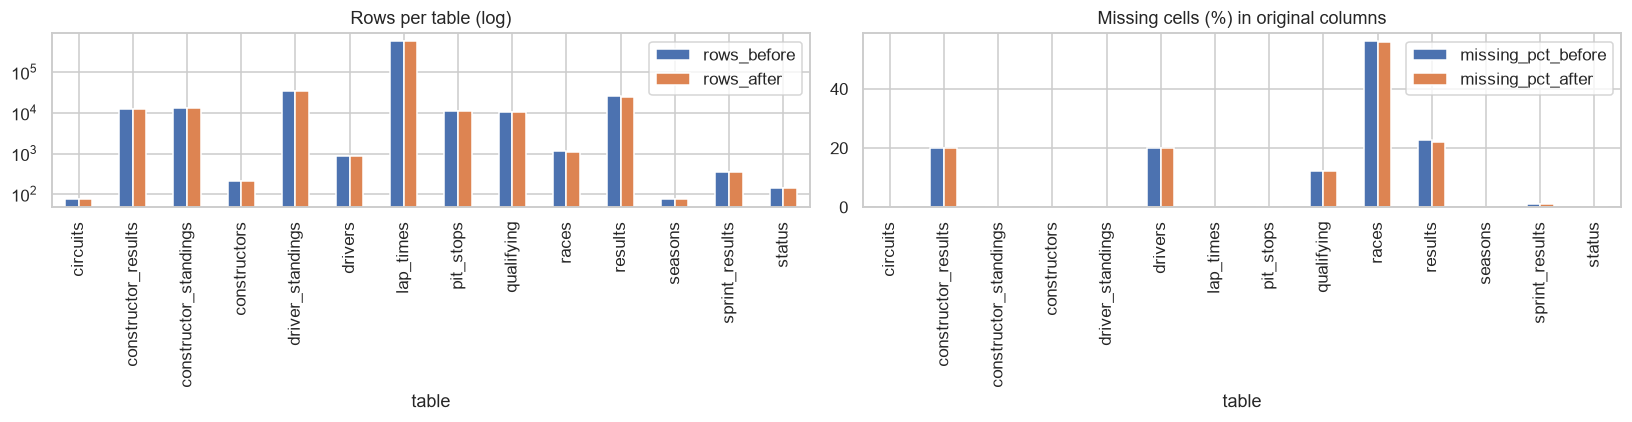

,rows_before,rows_after,dtype_changes,missing_pct_before,missing_pct_after,keys_ok_before,keys_ok_after,fk_orphans_before,fk_orphans_after,columns_added,columns_dropped
table,,,,,,,,,,,
circuits,77,77,9,0.00,0.00,True,True,0,0,country_iso,
constructor_results,12625,12604,5,19.97,19.97,True,True,0,0,,
constructor_standings,13391,13365,7,0.00,0.00,True,True,0,0,,
constructors,212,212,5,0.00,0.00,True,True,0,0,,
driver_standings,34863,34194,7,0.00,0.00,True,True,0,0,,
drivers,861,861,9,20.12,20.12,True,True,0,0,nationality_iso,
lap_times,589081,589081,6,0.00,0.00,True,True,0,0,time_sec,
pit_stops,11371,11371,7,0.00,0.00,True,True,0,0,"duration_sec, duration_sec_outlier",
qualifying,10494,10494,9,12.35,12.35,True,True,0,0,"q1_sec, q2_sec, q3_sec, q1_sec_outlier, q2_sec...",


In [33]:
CLEAN = {t: T[t] for t in TABLES}
assert_keys(CLEAN, "end of cleaning")
for t, df in CLEAN.items():
    for c in df.columns:
        if df[c].dtype == object or str(df[c].dtype).startswith(("string", "str")):
            assert not df[c].astype("string").eq(r"\N").any(), f"'\\N' left in {t}.{c}"
assert frame_hash(RAW) == RAW_HASH, "RAW was modified!"
print("✅ no '\\N' left in any cleaned table | ✅ RAW unchanged (hash matches)")

pk_after = pd.concat([key_report(CLEAN, PRIMARY_KEYS, "primary key"), key_report(CLEAN, NATURAL_KEYS, "natural grain")])
fk_after = fk_report(CLEAN)
orph = lambda fk: fk.assign(table=fk.child.str.split(".").str[0]).groupby("table").orphans.sum()
rows = []
for t in TABLES:
    raw, cl = RAW[t], CLEAN[t]
    common = [c for c in raw.columns if c in cl.columns]
    rows.append({"table": t, "rows_before": len(raw), "rows_after": len(cl),
                 "dtype_changes": sum(str(raw[c].dtype) != str(cl[c].dtype) for c in common),
                 "missing_pct_before": round(100 * raw[common].apply(lambda s: _null(s.str.strip())).to_numpy().mean(), 2),
                 "missing_pct_after": round(100 * cl[common].isna().to_numpy().mean(), 2),
                 "keys_ok_before": bool(pk_before[pk_before.table == t].ok.all()),
                 "keys_ok_after": bool(pk_after[pk_after.table == t].ok.all()),
                 "fk_orphans_before": int(orph(fk_before).get(t, 0)), "fk_orphans_after": int(orph(fk_after).get(t, 0)),
                 "columns_added": ", ".join(c for c in cl.columns if c not in raw.columns),
                 "columns_dropped": ", ".join(c for c in raw.columns if c not in cl.columns)})
BEFORE_AFTER = pd.DataFrame(rows).set_index("table")
BEFORE_AFTER.to_csv(OUT_DIR / "cleaning_before_after.csv")
pd.DataFrame(CLEANING_LOG).to_csv(OUT_DIR / "cleaning_log.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
BEFORE_AFTER[["rows_before", "rows_after"]].plot.bar(ax=axes[0], logy=True, title="Rows per table (log)")
BEFORE_AFTER[["missing_pct_before", "missing_pct_after"]].plot.bar(ax=axes[1], title="Missing cells (%) in original columns")
plt.tight_layout(); savefig("cleaning_before_after")
BEFORE_AFTER

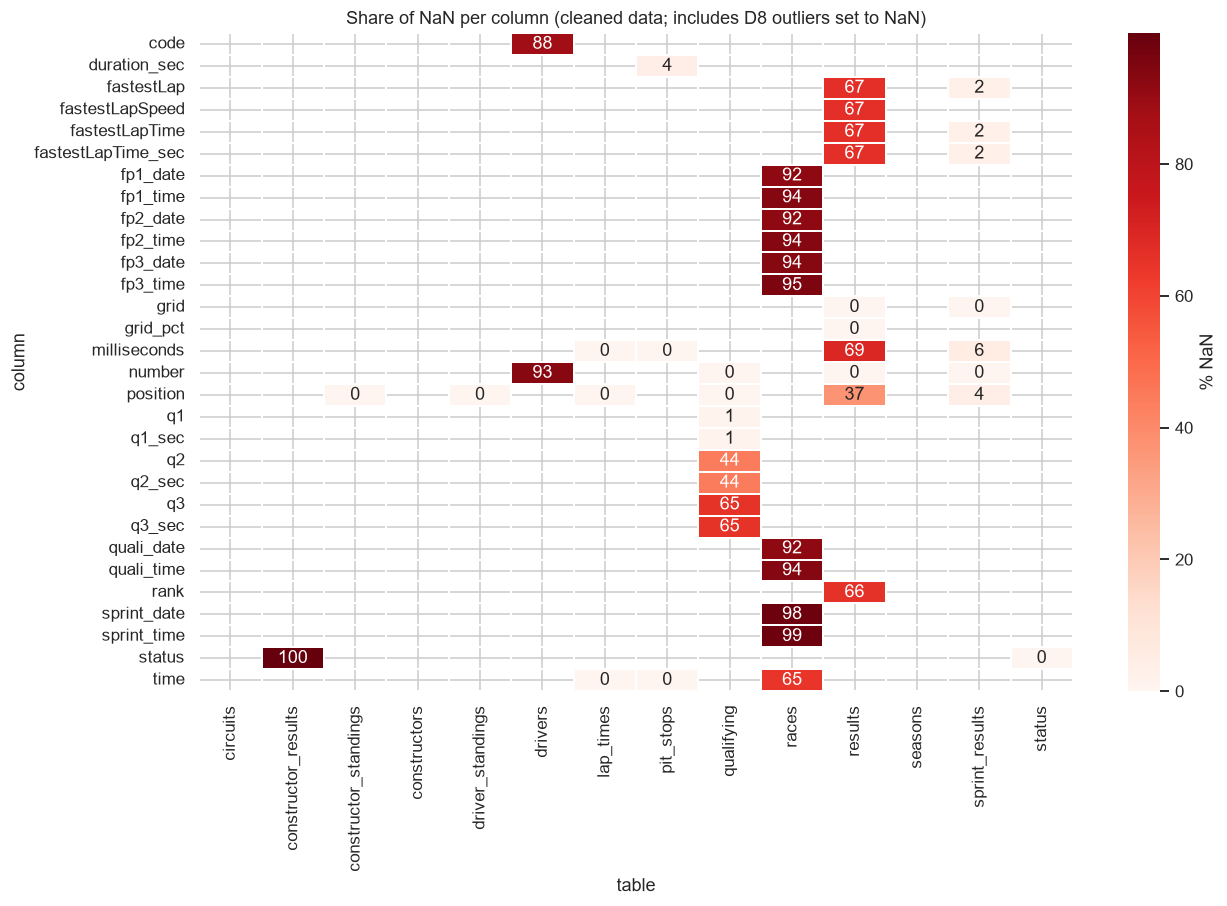

In [34]:
# Missing-value heatmap after cleaning (compare with the sentinel heatmap in §3.1)
nan_after = pd.DataFrame([{"table": t, "column": c, "nan_pct": 100 * CLEAN[t][c].isna().mean()}
                          for t in TABLES for c in CLEAN[t].columns])
piv = nan_after.pivot_table(index="column", columns="table", values="nan_pct")
piv = piv.loc[piv.max(axis=1) > 0]
plt.figure(figsize=(12, max(4, 0.28 * len(piv))))
sns.heatmap(piv, cmap="Reds", annot=True, fmt=".0f", cbar_kws={"label": "% NaN"}, linewidths=.3)
plt.title("Share of NaN per column (cleaned data; includes D8 outliers set to NaN)")
plt.tight_layout(); savefig("audit_nan_heatmap_after")

In [35]:
# dtypes before vs after (semantic typing)
dtype_cmp = pd.concat([pd.DataFrame({"table": t, "column": [c for c in RAW[t].columns if c in CLEAN[t]],
                                     "raw_dtype": [str(RAW[t][c].dtype) for c in RAW[t].columns if c in CLEAN[t]],
                                     "clean_dtype": [str(CLEAN[t][c].dtype) for c in RAW[t].columns if c in CLEAN[t]]})
                       for t in ["results", "qualifying", "races", "pit_stops", "drivers"]])
dtype_cmp

,table,column,raw_dtype,clean_dtype
0,results,resultId,str,Int64
1,results,raceId,str,Int64
2,results,driverId,str,Int64
3,results,constructorId,str,Int64
4,results,number,str,Int64
5,results,grid,str,float64
6,results,position,str,Int64
7,results,positionText,str,string
8,results,positionOrder,str,Int64
9,results,points,str,float64


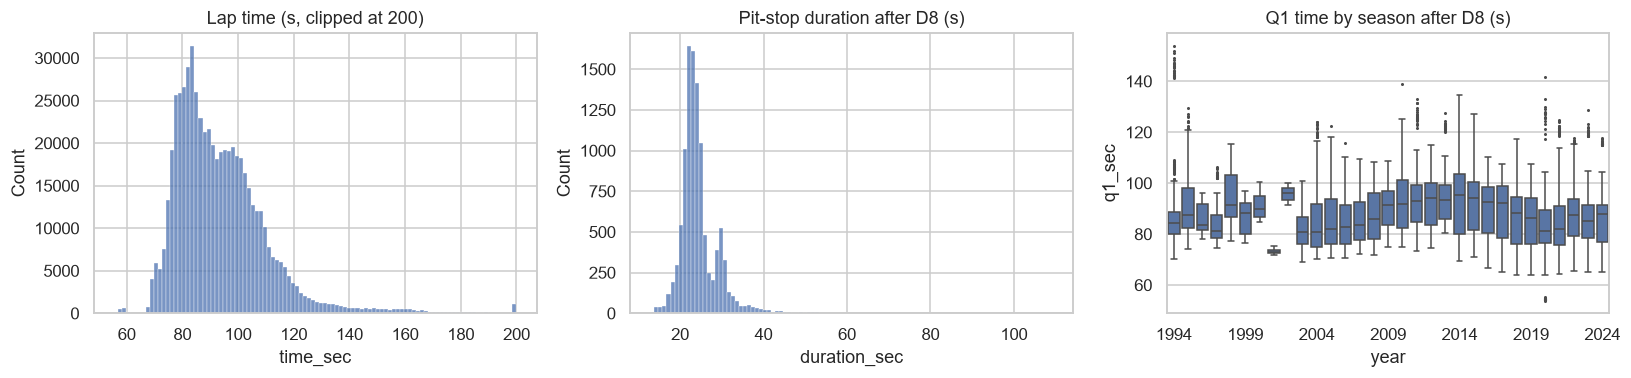

In [36]:
# Distributions of the typed duration columns after D8
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(CLEAN["lap_times"]["time_sec"].clip(upper=200), bins=100, ax=axes[0]); axes[0].set_title("Lap time (s, clipped at 200)")
sns.histplot(CLEAN["pit_stops"]["duration_sec"], bins=100, ax=axes[1]); axes[1].set_title("Pit-stop duration after D8 (s)")
qy = CLEAN["qualifying"].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
sns.boxplot(data=qy, x="year", y="q1_sec", ax=axes[2], fliersize=1); axes[2].set_title("Q1 time by season after D8 (s)")
axes[2].set_xticks(axes[2].get_xticks()[::5])
plt.tight_layout(); savefig("eda_clean_durations")

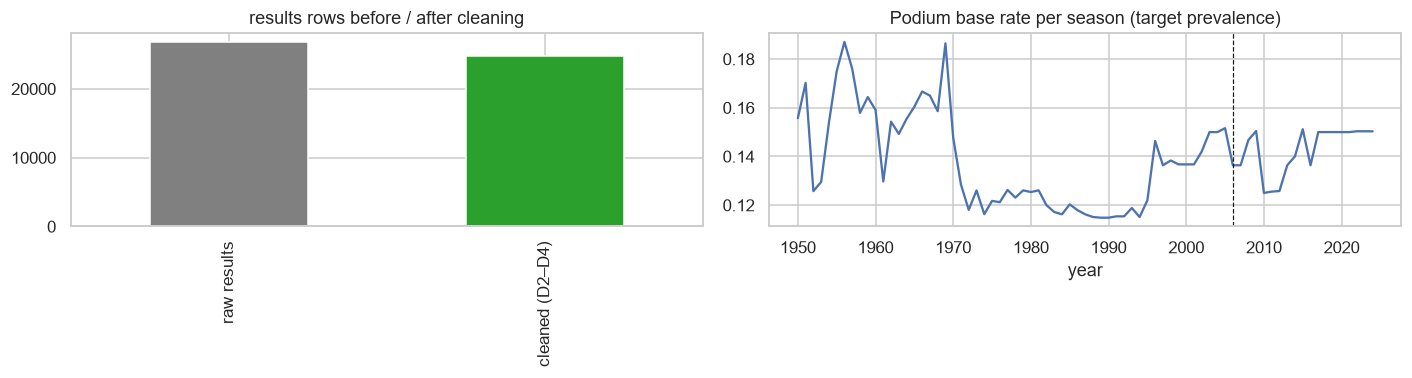

In [37]:
# Rows removed / merged and the target base rate per season
res_c = CLEAN["results"].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
pd.Series({"raw results": len(RAW["results"]), "cleaned (D2–D4)": len(res_c)}).plot.bar(ax=axes[0], color=["grey", "tab:green"])
axes[0].set_title("results rows before / after cleaning")
res_c.podium.astype(float).groupby(res_c.year).mean().plot(ax=axes[1], title="Podium base rate per season (target prevalence)")
axes[1].axvline(MODERN_FROM, color="k", ls="--", lw=.8)
plt.tight_layout(); savefig("eda_clean_grain_and_base_rate")

✍️ **WRITE-UP (impact of cleaning)**
- **Rows.** `results` goes from 26,759 to 24,755 rows:
  - −405 rows from the 11 Indianapolis 500 races (D4; 1,132 rows across all tables);
  - −1,535 non-starters without a grid slot (D2; only 9 in 2006+);
  - −64 from merging 125 shared-drive rows into 61 (D3).

  Primary keys, grain and foreign keys pass after every step, and `RAW` is unchanged (hash check).
- **Types and missing values.** Every column is typed, and the number of missing values after typing equals the number of sentinels (0 parse failures). Missing shares in the original columns barely move (`results` 22.8 % → 21.9 %, only because rows were removed). Cleaning converts sentinels; it neither invents nor fills values. Filling happens per feature in D6.
- **Outliers (D8).**
  - Set to NaN: 481 pit stops outside [1.5 s, 120 s] (e.g. ~51-minute "stops" that are red-flag suspensions) and 1 qualifying time (16:42.640, race 255).
  - The z-score rule would have removed 1,491 pit stops (13 %) and 703 qualifying times, mostly genuine slow ones.
- **Lap cleaning (D9).** Of 589,081 laps, D9 removed 11,041 lap-1 laps, 21,877 pit in/out laps and 42,680 slow laps (safety car / VSC / red flag). The 513,483 clean laps give `pace_ratio` for 10,655 driver-races (median 1.018).
- **Class imbalance.** Podiums are 13.6 % of all rows and 14.2 % in the modern scope (train 14.0 %, validation and test 15.0 %). This is why PR-AUC is the primary metric (§12).

## 7. Data-engineering questions
Shared joined view: cleaned results (D2–D5) ⨝ races ⨝ circuits ⨝ drivers ⨝ constructors ⨝ status (+ D11 group) ⨝ qualifying, with `constructor_family` (D12) and ISO codes (D15). The Indy 500 is excluded (D4).

In [38]:
R = (CLEAN["results"][["resultId", "raceId", "driverId", "constructorId", "grid", "grid_unknown", "positionOrder",
                       "statusId", "status_group", "laps", "podium"]]
     .merge(CLEAN["races"][["raceId", "year", "round", "date", "circuitId"]], on="raceId", how="left")
     .merge(CLEAN["circuits"][["circuitId", "name", "country", "country_iso"]].rename(columns={"name": "circuit"}),
            on="circuitId", how="left")
     .merge(CLEAN["drivers"][["driverId", "driverRef", "nationality", "nationality_iso"]], on="driverId", how="left")
     .merge(CLEAN["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
     .merge(CLEAN["status"], on="statusId", how="left")
     .merge(CLEAN["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
            on=["raceId", "driverId"], how="left"))
R["constructor_family"] = constructor_family(R.constructorId, R.year)
for c in ["grid", "positionOrder", "quali_pos", "laps"]:
    R[c] = R[c].astype("float64")
R["podium"] = R["podium"].astype(int)
assert R.duplicated(["raceId", "driverId"]).sum() == 0
print(R.shape); R.head()

(24755, 25)


,resultId,raceId,driverId,constructorId,grid,grid_unknown,positionOrder,statusId,status_group,laps,podium,year,round,date,circuitId,circuit,country,country_iso,driverRef,nationality,nationality_iso,constructor,status,quali_pos,constructor_family
0,1,18,1,1,1.0,0,1.0,1,finished,58.0,1,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,AUS,hamilton,British,GBR,McLaren,Finished,1.0,McLaren
1,2,18,2,2,5.0,0,2.0,1,finished,58.0,1,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,AUS,heidfeld,German,DEU,BMW Sauber,Finished,5.0,Hinwil
2,3,18,3,3,7.0,0,3.0,1,finished,58.0,1,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,AUS,rosberg,German,DEU,Williams,Finished,7.0,Williams
3,4,18,4,4,11.0,0,4.0,1,finished,58.0,0,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,AUS,alonso,Spanish,ESP,Renault,Finished,12.0,Enstone
4,5,18,5,1,3.0,0,5.0,1,finished,58.0,0,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,AUS,kovalainen,Finnish,FIN,McLaren,Finished,3.0,McLaren


### Q1 — Which circuits convert a front-row start into a podium most often; does the ranking change after 2014?
Front row is measured two ways: **grid** (actual start, after penalties) and **qualifying position** (before penalties).

In [39]:
# DECISION: pre-2014 = 2003–2013 vs 2014–2024; >= 8 front-row starts (about 4 races) per circuit and era;
# ranks are compared only for circuits that appear in both eras.
PRE_HYBRID = (2003, 2013)   # qualifying is complete from 2003 (§4), so grid and qualifying definitions are comparable
HYBRID = (2014, 2024)
Q1_MIN_STARTS = 8           # below this, one podium moves a rate by more than 12 points

def era_of(y):
    if PRE_HYBRID[0] <= y <= PRE_HYBRID[1]: return "pre-2014"
    if HYBRID[0] <= y <= HYBRID[1]: return "2014+"
    return None

R["era"] = R["year"].map(era_of)

def front_row_conversion(df, by):
    fr = df[df[by].isin([1, 2]) & df["era"].notna()]
    out = (fr.groupby(["circuit", "era"]).agg(starts=("podium", "size"), podiums=("podium", "sum"))
             .assign(rate=lambda d: d.podiums / d.starts).reset_index())
    return out[out.starts >= Q1_MIN_STARTS]

q1_grid = front_row_conversion(R, "grid")
q1_quali = front_row_conversion(R, "quali_pos")

# How often do grid and qualifying front rows differ? (penalties / pit-lane starts)
both = R[R.era.notna() & R.quali_pos.notna()]
diff = both[(both.quali_pos <= 2) != (both.grid.between(1, 2))]
print(f"Entries where 'front row' differs between grid and qualifying: {len(diff)} "
      f"({len(diff) / both.quali_pos.le(2).sum():.1%} of qualifying front rows)")
q1_grid.sort_values("rate", ascending=False).head(10)

Entries where 'front row' differs between grid and qualifying: 74 (8.6% of qualifying front rows)


,circuit,era,starts,podiums,rate
23,Circuit de Nevers Magny-Cours,pre-2014,12,11,0.916667
54,Suzuka Circuit,2014+,18,16,0.888889
17,Circuit Park Zandvoort,2014+,8,7,0.875000
36,Jeddah Corniche Circuit,2014+,8,7,0.875000
57,Yas Marina Circuit,2014+,22,19,0.863636
21,Circuit de Monaco,2014+,20,17,0.850000
24,Circuit de Spa-Francorchamps,2014+,22,18,0.818182
19,Circuit de Barcelona-Catalunya,2014+,22,18,0.818182
53,Sochi Autodrom,2014+,16,13,0.812500
26,Circuit of the Americas,2014+,20,16,0.800000


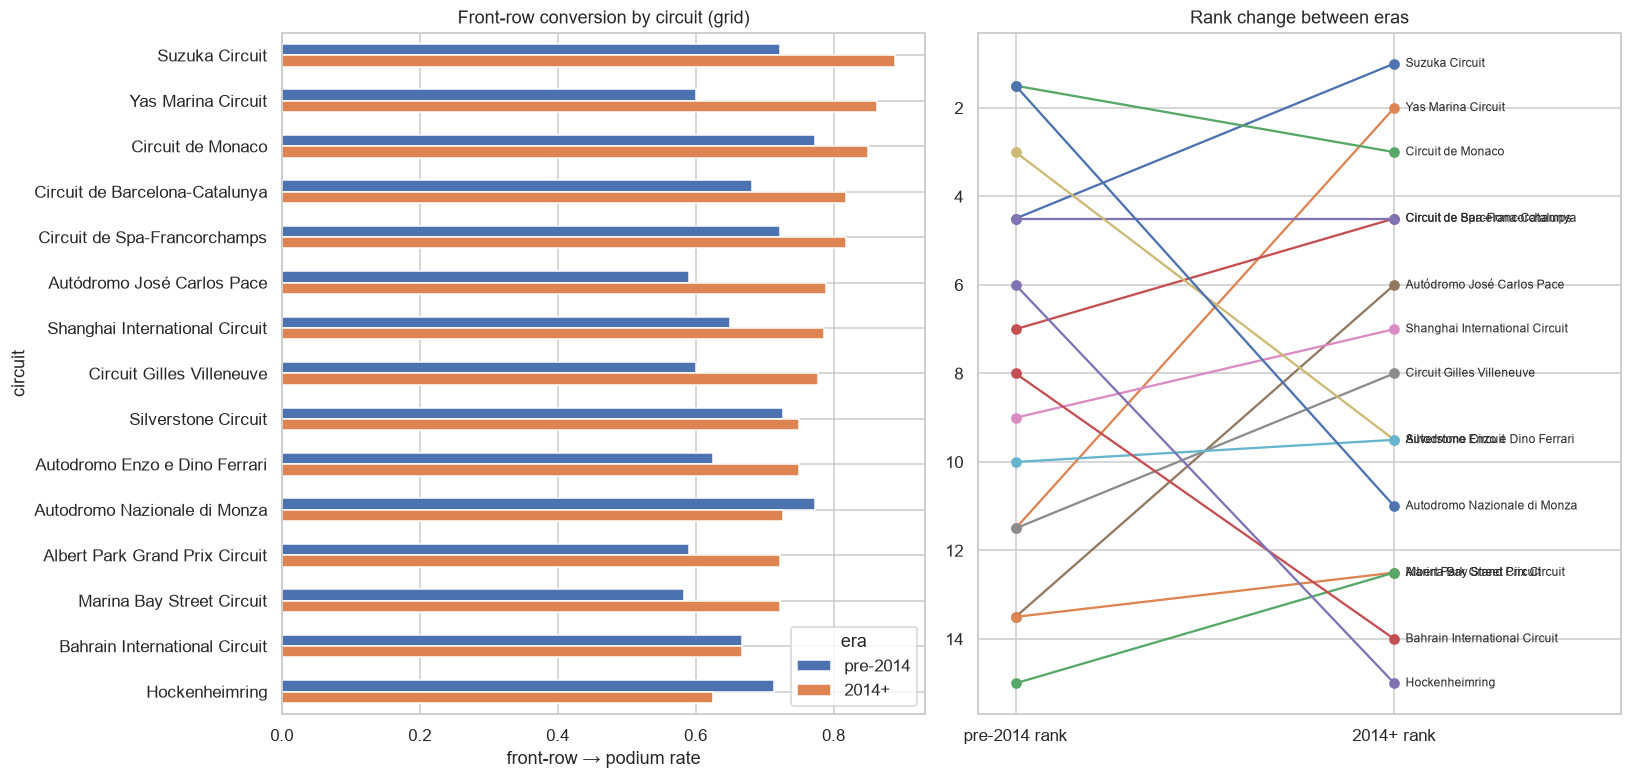

[grid] circuits in both eras: 15 | Spearman rank correlation pre vs 2014+: 0.21 (p=0.456)


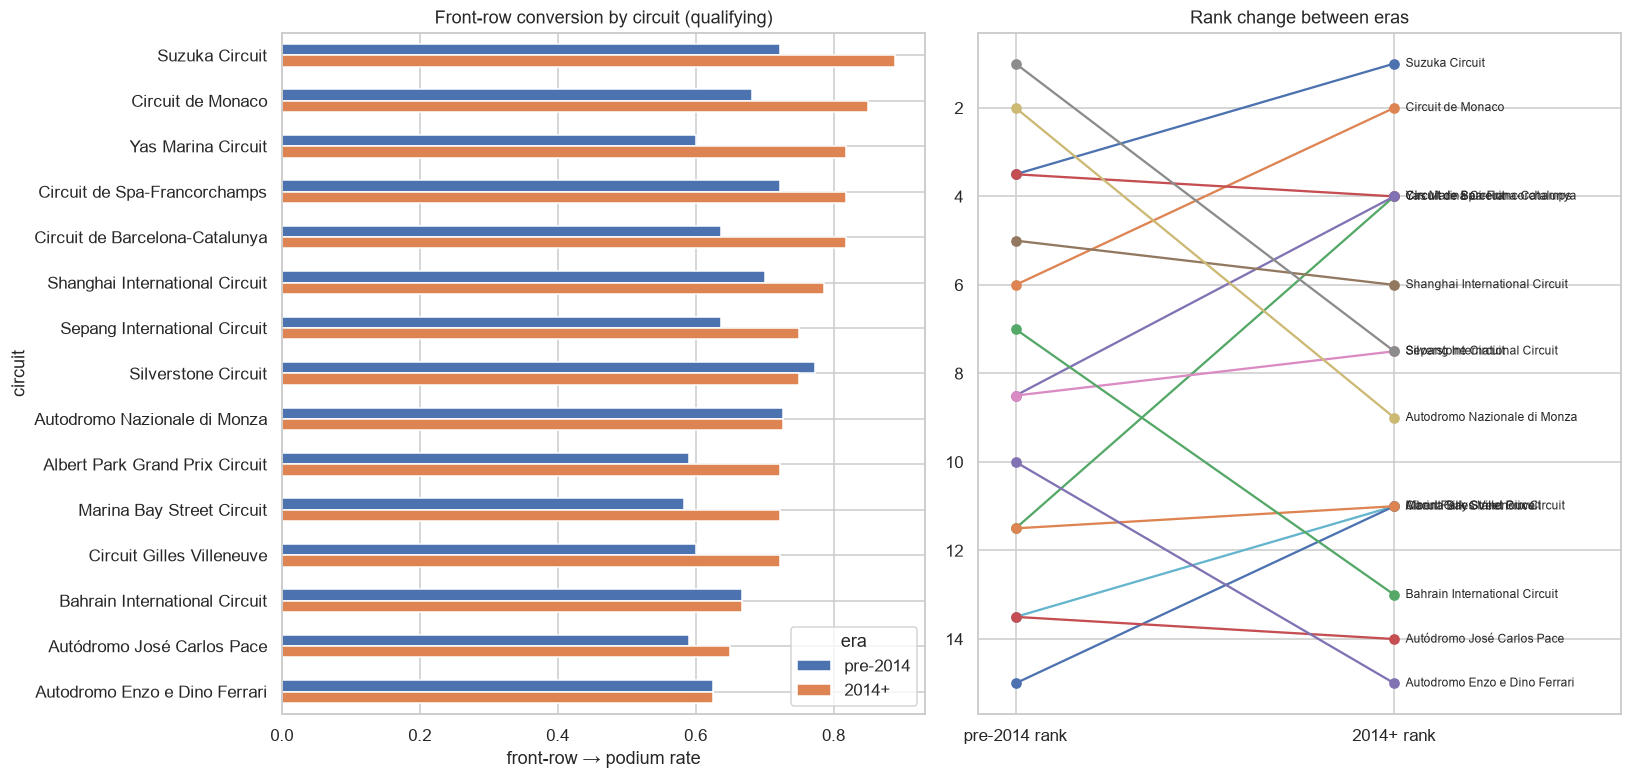

[qualifying] circuits in both eras: 15 | Spearman rank correlation pre vs 2014+: 0.50 (p=0.057)


In [40]:
def plot_q1(tbl, label, top=15):
    wide = tbl.pivot(index="circuit", columns="era", values="rate").dropna()
    wide = wide.sort_values("2014+", ascending=False).head(top)
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.35 * len(wide) + 2))
    wide[["pre-2014", "2014+"]].plot.barh(ax=axes[0]); axes[0].invert_yaxis()
    axes[0].set_xlabel("front-row → podium rate"); axes[0].set_title(f"Front-row conversion by circuit ({label})")
    # slope chart of ranks
    ranks = wide.rank(ascending=False)
    for c, r in ranks.iterrows():
        axes[1].plot([0, 1], [r["pre-2014"], r["2014+"]], marker="o")
        axes[1].text(1.03, r["2014+"], c, va="center", fontsize=8)
    axes[1].set_xticks([0, 1], ["pre-2014 rank", "2014+ rank"]); axes[1].invert_yaxis(); axes[1].set_xlim(-.1, 1.6)
    axes[1].set_title("Rank change between eras")
    plt.tight_layout(); savefig(f"q1_front_row_{label}")
    rho, p = stats.spearmanr(wide["pre-2014"], wide["2014+"]) if len(wide) > 2 else (np.nan, np.nan)
    print(f"[{label}] circuits in both eras: {len(wide)} | Spearman rank correlation pre vs 2014+: {rho:.2f} (p={p:.3f})")

plot_q1(q1_grid, "grid")
plot_q1(q1_quali, "qualifying")

✍️ **WRITE-UP (Q1)**
- **Answer (grid definition).**
  - **2014–2024:** best converters are Suzuka 89 % (16/18), Yas Marina 86 % (19/22) and Monaco 85 % (17/20), then Spa and Barcelona at 82 %.
  - **2003–2013:** Magny-Cours 92 % (11/12; no race after 2008), Monaco and Monza ≈ 77 %, Suzuka / Spa / Silverstone ≈ 72 %.
- **Does the ranking change? Yes.** For the 15 circuits with enough starts in both eras, the Spearman rank correlation is **0.21 (p = 0.46)** on grid and **0.50 (p = 0.06)** on qualifying. Neither shows that the ranking carries over.
  - Monza drops from joint 1st to 11th and Hockenheim to last; Yas Marina (11.5 → 2) and Interlagos (13.5 → 6) rise.
  - Conversion rises at almost every circuit after 2014: in the Mercedes / Red Bull years the front row was usually the fastest car.
- **Grid vs qualifying.** The two definitions disagree for 74 entries (8.6 % of qualifying front rows): penalties and pit-lane starts move qualifiers off the front row. The qualifying-based ranking is more stable across eras (0.50 vs 0.21).
- **Grain:** one row per driver-race (after D2 / D3), filtered to front-row starters. **Missingness:** only 2003+, where qualifying is complete; `grid = 0` handled by D5. **Cutoff:** both grid and qualifying position are known before the start.
- **Caveats:** only 8–22 front-row starts per circuit and era, so one podium moves a rate by 5–12 points. Some circuits exist in one era only, and some layouts changed.

### Q2 — Do drivers podium more often at home, controlling for starting position?
Home = the driver's nationality maps to the circuit's country. The comparison is made **within grid-position strata**, then pooled with a Mantel–Haenszel odds ratio.

In [41]:
# Home race = driver nationality and circuit country map to the same ISO code (D15; 0 unmapped asserted in §5.12)
R["home"] = (R["nationality_iso"] == R["country_iso"]).astype(int)
print("home entries:", int(R.home.sum()), "of", len(R))

# DECISION: strata = pole, P2–3, P4–6, P7–10, P11–15, P16+ (podium rate falls 2–4x from one bin to the next);
# period = all seasons for the largest home sample; the sensitivity table below checks sub-periods.
Q2_GRID_BINS = [0, 1, 3, 6, 10, 15, 40]       # (0,1], (1,3], ...; pit-lane starts land in the last bin
Q2_PERIOD = (1950, 2024)                       # all seasons (Indy 500 already excluded, D4)

q2 = R[R.year.between(*Q2_PERIOD) & (R.grid > 0)].copy()     # grid NaN (unknown slot, pre-2006) is excluded
q2["grid_bin"] = pd.cut(q2.grid, Q2_GRID_BINS)
tab = q2.groupby(["grid_bin", "home"], observed=True).podium.agg(["mean", "size"]).unstack("home")
tab.columns = [f"{a}_{'home' if b else 'away'}" for a, b in tab.columns]
tab

home entries: 1948 of 24755


,mean_away,mean_home,size_away,size_home
grid_bin,,,,
"(0, 1]",0.647969,0.621951,1034,82
"(1, 3]",0.509870,0.550336,2077,149
"(3, 6]",0.260828,0.269912,3117,226
"(6, 10]",0.092278,0.071429,4118,336
"(10, 15]",0.030043,0.024096,5126,415
"(15, 40]",0.007263,0.002729,7297,733


Crude odds ratio (home vs away):            0.84
Grid-adjusted Mantel-Haenszel odds ratio:   0.95  (95% CI 0.80-1.13)
Home entries: 1941 of 24710


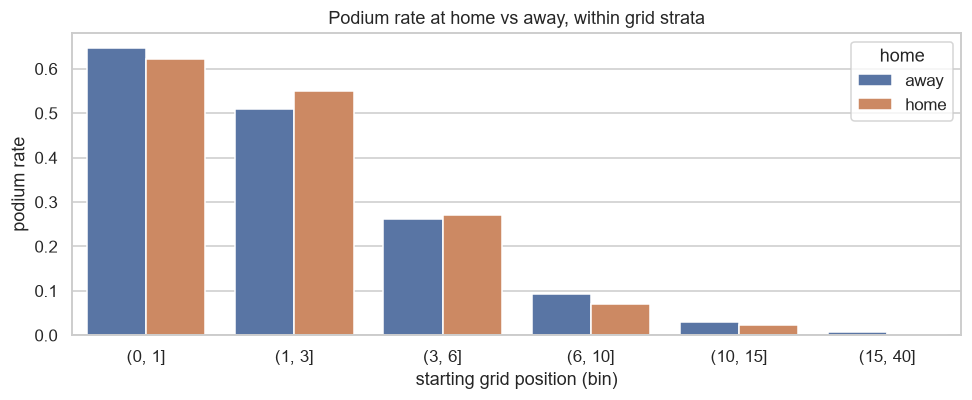

In [42]:
def mantel_haenszel(df, strata, exposure, outcome):
    # Pooled odds ratio across strata with Robins-Breslow-Greenland 95% CI.
    num = den = P_R = PS_QR = Q_S = 0.0
    sumR = sumS = 0.0
    for _, g in df.groupby(strata, observed=True):
        a = ((g[exposure] == 1) & (g[outcome] == 1)).sum(); b = ((g[exposure] == 1) & (g[outcome] == 0)).sum()
        c = ((g[exposure] == 0) & (g[outcome] == 1)).sum(); d = ((g[exposure] == 0) & (g[outcome] == 0)).sum()
        n = a + b + c + d
        if n == 0 or (a + b) == 0 or (c + d) == 0: continue
        Ri, Si = a * d / n, b * c / n
        Pi, Qi = (a + d) / n, (b + c) / n
        sumR += Ri; sumS += Si
        P_R += Pi * Ri; PS_QR += Pi * Si + Qi * Ri; Q_S += Qi * Si
    or_mh = sumR / sumS
    var = P_R / (2 * sumR**2) + PS_QR / (2 * sumR * sumS) + Q_S / (2 * sumS**2)
    lo, hi = np.exp(np.log(or_mh) + np.array([-1.96, 1.96]) * np.sqrt(var))
    return or_mh, lo, hi

crude_or = (lambda t: (t.loc[1, 1] * t.loc[0, 0]) / (t.loc[1, 0] * t.loc[0, 1]))(pd.crosstab(q2.home, q2.podium))
or_mh, lo, hi = mantel_haenszel(q2, "grid_bin", "home", "podium")
print(f"Crude odds ratio (home vs away):            {crude_or:.2f}")
print(f"Grid-adjusted Mantel-Haenszel odds ratio:   {or_mh:.2f}  (95% CI {lo:.2f}-{hi:.2f})")
print(f"Home entries: {q2.home.sum()} of {len(q2)}")

plot_df = q2.groupby(["grid_bin", "home"], observed=True).podium.mean().reset_index()
plot_df["home"] = plot_df.home.map({1: "home", 0: "away"})
plot_df["grid_bin"] = plot_df.grid_bin.astype(str)
plt.figure(figsize=(9, 3.8))
sns.barplot(data=plot_df, x="grid_bin", y="podium", hue="home")
plt.ylabel("podium rate"); plt.xlabel("starting grid position (bin)"); plt.title("Podium rate at home vs away, within grid strata")
plt.tight_layout(); savefig("q2_home_vs_away_by_grid")

In [43]:
# Sensitivity: does the answer depend on the period? (same grid strata, Mantel-Haenszel pooled odds ratio)
sens = []
for label, (a, b) in {"1950–2024 (main)": (1950, 2024), "1950–2005": (1950, 2005), "2006–2024": (2006, 2024)}.items():
    d = R[R.year.between(a, b) & (R.grid > 0)].copy()
    d["grid_bin"] = pd.cut(d.grid, Q2_GRID_BINS)
    o, l, h = mantel_haenszel(d, "grid_bin", "home", "podium")
    crude = (lambda t: (t.loc[1, 1] * t.loc[0, 0]) / (t.loc[1, 0] * t.loc[0, 1]))(pd.crosstab(d.home, d.podium))
    sens.append({"period": label, "entries": len(d), "home_entries": int(d.home.sum()), "crude_OR": crude,
                 "MH_OR": o, "CI_low": l, "CI_high": h})
Q2_SENSITIVITY = pd.DataFrame(sens).set_index("period").round(3)
Q2_SENSITIVITY.to_csv(OUT_DIR / "q2_sensitivity.csv")
Q2_SENSITIVITY

,entries,home_entries,crude_OR,MH_OR,CI_low,CI_high
period,,,,,,
1950–2024 (main),24710,1941,0.844,0.953,0.802,1.133
1950–2005,16805,1643,0.817,0.953,0.790,1.149
2006–2024,7905,298,1.046,0.873,0.566,1.346


✍️ **WRITE-UP (Q2)**
- **Crude:** home entries reach the podium *less* often (odds ratio 0.84). That is mostly because many home entries are one-off local drivers starting near the back.
- **Adjusted for grid position:** within grid strata, the **Mantel–Haenszel odds ratio is 0.95 (95 % CI 0.80–1.13)**. There is no evidence of a home advantage; the crude penalty is explained by starting position. Within each stratum, home and away rates differ by only a few points (pole: 62 % vs 65 %; P2–3: 55 % vs 51 %).
- **Sensitivity:** 1950–2005 gives 0.95 (0.79–1.15) and 2006–2024 gives 0.87 (0.57–1.35, only 298 home entries). The conclusion is the same in every period.
- **Grain:** driver-race, starters with a known grid slot (24,710 rows, 1,941 at home). **Missingness:** 0 unmapped nationalities or countries (D15); the 45 pre-2006 unknown grid slots are excluded. **Cutoff:** home status and grid are both known before the race.
- **Limitations:** nationality is not always where a driver grew up, and dual nationalities are mapped to the first one listed. Drivers from countries without a race contribute only away entries. Top strata contain few home entries (82 on pole).

### Q3 — Mechanical-retirement rate by constructor: 2014–2021 vs 2022–2024
**Mechanical retirement** = a race **start** that ended because a car component failed — not crashes, driver errors or regulation decisions.

In [44]:
# Statuses in the analysis window with their D11 group (codebooks/status_map.csv), so the classification is auditable
q3_window = R[R.year.between(2014, 2024)]
q3_status = q3_window.groupby(["status_group", "status"]).size().rename("count").reset_index()
for g, d in q3_status.groupby("status_group"):
    print(f"{g:13s}: " + ", ".join(f"{s} ({n})" for s, n in d.sort_values("count", ascending=False)[["status", "count"]].values))

ambiguous    : Retired (50), Wheel (11), Puncture (7), Undertray (4), Tyre (4), Front wing (3), Wheel nut (3), Rear wing (3), Damage (2), Technical (2), Vibrations (2), Debris (1), Out of fuel (1), Seat (1)
disqualified : Disqualified (11), Excluded (1)
finished     : Finished (2403)
incident     : Collision (150), Accident (85), Collision damage (59), Spun off (11), Illness (3)
lapped       : +1 Lap (1178), +2 Laps (208), +3 Laps (24), +4 Laps (6), +6 Laps (2), +8 Laps (2), +5 Laps (1), +7 Laps (1)
mechanical   : Engine (81), Brakes (49), Gearbox (42), Power Unit (42), Suspension (25), Hydraulics (15), Electrical (14), Power loss (13), Oil leak (10), Overheating (8), Mechanical (7), Water pressure (7), Turbo (6), Exhaust (5), Battery (5), Fuel pressure (5), ERS (5), Water leak (4), Electronics (4), Radiator (3), Transmission (3), Steering (2), Oil pressure (2), Throttle (2), Driveshaft (2), Fuel leak (2), Clutch (2), Brake duct (1), Fuel pump (1), Differential (1), Drivetrain (1), Coo

In [45]:
# Denominator = race STARTS: every row except the D11 group 'non_start' (e.g. Withdrew after taking a grid slot).
# Numerator, two variants (D11): (a) mechanical only; (b) mechanical + ambiguous.
Q3_ERAS = {"2014-2021": (2014, 2021), "2022-2024": (2022, 2024)}
Q3_MIN_STARTS = 20   # DECISION: >= 20 starts per family and era; smaller samples give CIs wider than the rates
VARIANTS = {"a_mech_only": {"mechanical"}, "b_mech_plus_ambiguous": {"mechanical", "ambiguous"}}

rows = []
for era, (a, b) in Q3_ERAS.items():
    w = R[R.year.between(a, b) & R.status_group.ne("non_start")]
    for v, groups in VARIANTS.items():
        g = (w.assign(mech=w.status_group.isin(groups)).groupby("constructor_family")
               .agg(starts=("mech", "size"), mech_dnf=("mech", "sum"),
                    names=("constructor", lambda s: " / ".join(dict.fromkeys(s)))))
        rows.append(g.assign(era=era, variant=v, rate=g.mech_dnf / g.starts).reset_index())
q3 = pd.concat(rows)
q3 = q3[q3.starts >= Q3_MIN_STARTS]

# Wilson 95% interval per rate (small denominators matter here)
z = 1.96
p, n = q3.rate, q3.starts
centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
q3["lo"], q3["hi"] = centre - half, centre + half
q3.to_csv(OUT_DIR / "q3_mechanical_rates.csv", index=False)

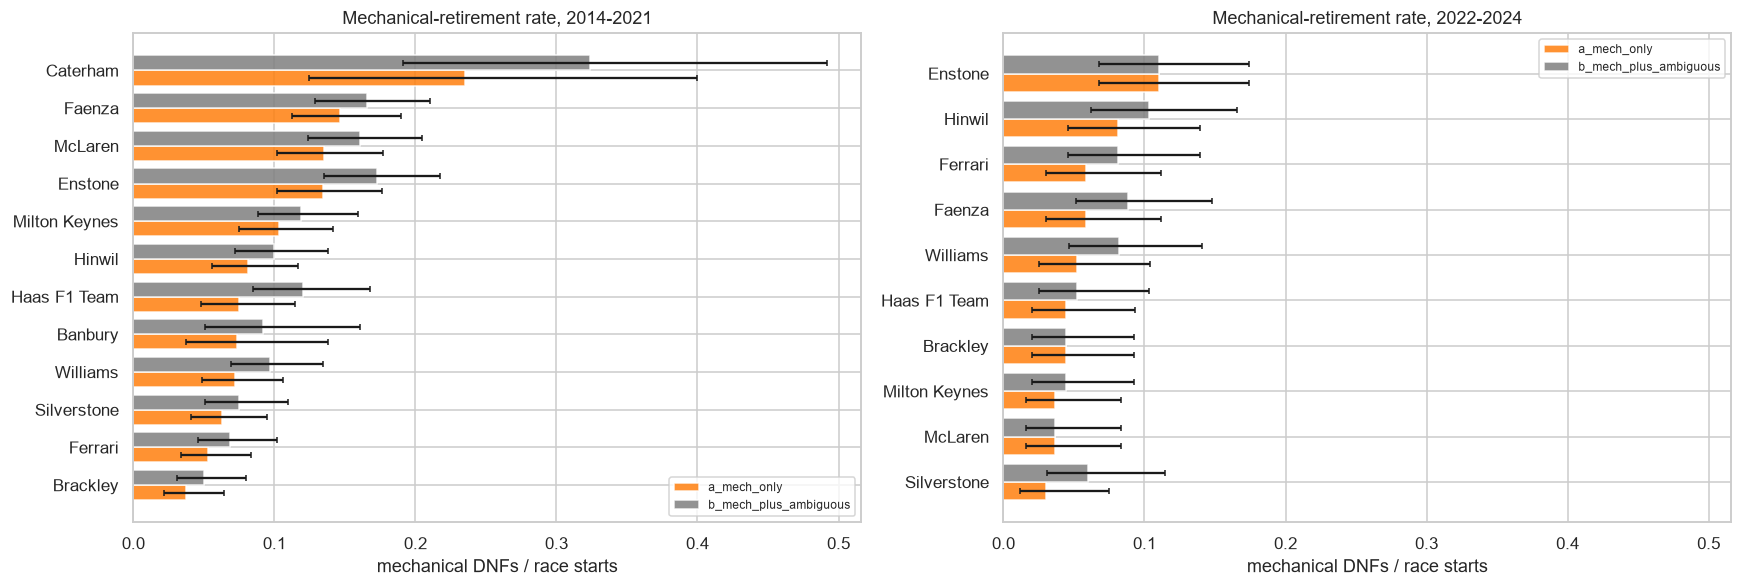

2014-2021: Spearman rank correlation, variant a vs b = 0.95 (p=0.000, n=12)
2022-2024: Spearman rank correlation, variant a vs b = 0.85 (p=0.002, n=10)


variant                       a_mech_only  b_mech_plus_ambiguous  rank_a  rank_b
era       constructor_family                                                    
2014-2021 Caterham                  0.235                  0.324     1.0     1.0
          Faenza                    0.147                  0.166     2.0     3.0
          McLaren                   0.135                  0.160     3.0     4.0
          Enstone                   0.135                  0.172     4.0     2.0
          Milton Keynes             0.103                  0.119     5.0     6.0
          Hinwil                    0.081                  0.100     6.0     7.0
          Haas F1 Team              0.075                  0.120     7.0     5.0
          Banbury                   0.073                  0.092     8.0     9.0
          Williams                  0.072                  0.097     9.0     8.0
          Silverstone               0.063                  0.075    10.0    10.0
          Ferrari                   0.053                  0.069    11.0    11.0
          Brackley                  0.038                  0.050    12.0    12.0
2022-2024 Enstone                   0.110                  0.110     1.0     1.0
          Hinwil                    0.081                  0.103     2.0     2.0
          Faenza                    0.059                  0.088     3.5     3.0
          Ferrari                   0.059                  0.081     3.5     5.0
          Williams                  0.052                  0.082     5.0     4.0
          Haas F1 Team              0.044                  0.052     6.0     7.0
          Brackley                  0.044                  0.044     7.0     8.5
          McLaren                   0.037                  0.037     8.5    10.0
          Milton Keynes             0.037                  0.044     8.5     8.5
          Silverstone               0.030                  0.060    10.0     6.0

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)
for ax, era in zip(axes, Q3_ERAS):
    d = q3[q3.era == era].pivot(index="constructor_family", columns="variant", values=["rate", "lo", "hi"])
    d = d.sort_values(("rate", "a_mech_only"))
    y = np.arange(len(d))
    for off, v, col in [(-0.2, "a_mech_only", "tab:orange"), (0.2, "b_mech_plus_ambiguous", "tab:grey")]:
        r = d[("rate", v)]
        ax.barh(y + off, r, height=0.4, color=col, alpha=.85, label=v,
                xerr=[r - d[("lo", v)], d[("hi", v)] - r], capsize=2)
    ax.set_yticks(y, d.index); ax.set_title(f"Mechanical-retirement rate, {era}")
    ax.set_xlabel("mechanical DNFs / race starts"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("q3_mechanical_dnf_rate")

# Side-by-side rankings of both variants + Spearman rank correlation per era
side = q3.pivot_table(index=["era", "constructor_family"], columns="variant", values="rate")
side["rank_a"] = side.groupby(level="era")["a_mech_only"].rank(ascending=False)
side["rank_b"] = side.groupby(level="era")["b_mech_plus_ambiguous"].rank(ascending=False)
for era, d in side.groupby(level="era"):
    rho, pval = stats.spearmanr(d.a_mech_only, d.b_mech_plus_ambiguous)
    print(f"{era}: Spearman rank correlation, variant a vs b = {rho:.2f} (p={pval:.3f}, n={len(d)})")
side.sort_values(["era", "rank_a"]).round(3)

✍️ **WRITE-UP (Q3)**
- **2014–2021** (variant a, mechanical only): highest are Caterham (23.5 % of starts), Faenza (Toro Rosso / AlphaTauri, 14.7 %), McLaren (13.5 %, the McLaren-Honda years) and Enstone (Lotus / Renault, 13.5 %). Lowest is Brackley (Mercedes, 3.8 %).
- **2022–2024:** highest are Enstone (Alpine, 11.0 %), Hinwil (Alfa Romeo / Sauber, 8.1 %), and Faenza and Ferrari (5.9 %). Lowest are Silverstone (Aston Martin, 3.0 %), McLaren and Red Bull (3.7 %). Rates roughly halve across the field, consistent with mature hybrid power units and the budget-cap era.
- **Classification:** the D11 codebook (`codebooks/status_map.csv`: 57 mechanical labels, 30 ambiguous). The ranking is robust to the ambiguous labels: the Spearman correlation between variant (a) and variant (b, ambiguous counted as mechanical) is **0.95** (2014–21) and **0.85** (2022–24), and the top team in each era does not change. "Retired" (50 in the window) is the biggest ambiguous label.
- **Denominator:** race starts, i.e. every row except group `non_start` (11 "Withdrew" in the window). **Grain:** one row per start. **Families (D12)** join renamed teams, so Toro Rosso → AlphaTauri → RB is compared as one team.
- **Uncertainty:** Wilson 95 % intervals are in the figure. With roughly 130–330 starts per family and era, differences under about 4 points overlap.

## 8. Modeling table — one row per (raceId, driverId) ✅
**Prediction cutoff:** after qualifying, before the race starts.
- Every history feature uses *strictly earlier* races only (`shift(1)` on a chronological order).
- Everything else comes from the current race's **qualifying, grid or sprint**, all known at the cutoff.

Histories are computed on **all seasons** (Indy excluded). `DATA_SCOPE` then keeps only the rows in scope, so 2006 is not a cold start.

**Forbidden** (current race, post-race): `position`, `positionText`, `positionOrder` (except to build the target), `points`, `laps`, `milliseconds`, `fastestLap*`, `rank`, `statusId` / `status_group`, pit stops, lap times / `pace_ratio`, `race_shortened`, and standings published after this race.
The table may contain **only** whitelisted features, plus IDs and the target (fixed step 9).

In [47]:
FORM_WINDOW = 5          # DECISION: last 5 races ≈ a quarter season — tracks upgrades, smooths a single DNF
SCOPE_FROM, SCOPE_TO = SCOPE_YEARS[DATA_SCOPE]

base = (CLEAN["results"][["resultId", "raceId", "driverId", "constructorId", "grid", "grid_pct", "pitlane_start",
                          "grid_unknown", "field_size", "positionOrder", "points", "status_group", "podium"]]
        .merge(CLEAN["races"][["raceId", "year", "round", "date", "circuitId"]], on="raceId")
        .sort_values(["date", "raceId", "driverId"]).reset_index(drop=True))
base["podium"] = base.podium.astype(int)
base["finished"] = base.status_group.isin(["finished", "lapped"]).astype(int)   # D11 codebook
base["con_family"] = constructor_family(base.constructorId, base.year)           # D12 lineage
# Scale-free points (D13 reasoning applied to form): share of the race's best points haul. Removes the 2010 scoring
# change (win 10 -> 25), half-points races and fastest-lap bonuses. Used ONLY shifted into past-only features.
base["pts_frac"] = (base.points / base.groupby("raceId").points.transform("max")).fillna(0.0)
# NOTE: positionOrder, points, status_group and finished are used ONLY (a) as the target and (b) shifted into past-only features.
print(base.shape)

(24755, 20)


In [48]:
# ---- Grid & qualifying features (known at the cutoff) -------------------------------------
quali = CLEAN["qualifying"].copy()                                    # grain already unique (asserted in §5)
quali["q_best_sec"] = quali[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)  # D8 outliers are already NaN
quali["pole_sec"] = quali.groupby("raceId").q_best_sec.transform("min")
quali["gap_to_pole_sec"] = quali.q_best_sec - quali.pole_sec
quali["gap_to_pole_pct"] = 100 * quali.gap_to_pole_sec / quali.pole_sec
knockout = (quali.raceId.map(CLEAN["races"].set_index("raceId").year) >= MODERN_FROM).to_numpy(bool)
# reached Q2/Q3 uses the raw time strings (an outlier time still means the driver took part); structural NaN before 2006
quali["reached_q2"] = np.where(knockout, quali.q2.notna().astype(float), np.nan)
quali["reached_q3"] = np.where(knockout, quali.q3.notna().astype(float), np.nan)
QUALI_COLS = ["quali_pos", "gap_to_pole_sec", "gap_to_pole_pct", "reached_q2", "reached_q3"]
quali = quali.rename(columns={"position": "quali_pos"})[["raceId", "driverId", *QUALI_COLS]]

df = base.merge(quali, on=["raceId", "driverId"], how="left")
df["grid_minus_quali"] = df.grid - df.quali_pos            # grid penalties / pit-lane starts / 2021-22 sprint grids

# ---- Sprint (D14) ------------------------------------------------------------------------
df = df.merge(SPRINT, on=["raceId", "driverId"], how="left")
df["is_sprint_weekend"] = df.raceId.isin(SPRINT_RACES).astype(int)
assert df.loc[df.is_sprint_weekend == 0, "sprint_finish_pct"].isna().all()

In [49]:
# ---- Pre-race standings (D13 + D7): after the previous round, or last season's final round for round 1
df = df.merge(RACE_ORDER[["raceId", "standings_src_raceId", "is_round_1"]], on="raceId", how="left")
df = df.merge(DS, on=["standings_src_raceId", "driverId"], how="left")
df = df.merge(CS, on=["standings_src_raceId", "con_family"], how="left")   # renamed teams matched by family
src_dates = df.standings_src_raceId.map(CLEAN["races"].set_index("raceId").date)
assert (src_dates.dropna() < df.loc[src_dates.notna(), "date"]).all(), "standings must be dated before the race"
print("round-1 rows with last-season standings:",
      int((df.is_round_1.eq(1) & df.drv_pts_share.notna()).sum()), "of", int(df.is_round_1.sum()))

round-1 rows with last-season standings: 1348 of 1610


In [50]:
# ---- Form features: rolling over PREVIOUS races only --------------------------------------
df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
W = FORM_WINDOW

def past_roll(frame, keys, col, how="mean"):
    # shift(1) => the current race is never included; window = last W races of the group
    return frame.groupby(keys)[col].transform(lambda s: s.astype("float64").shift(1).rolling(W, min_periods=1).agg(how))

df = df.merge(PACE[["raceId", "driverId", "pace_ratio"]], on=["raceId", "driverId"], how="left")   # D9
df["drv_avg_finish_lastN"] = past_roll(df, "driverId", "positionOrder")
df["drv_podium_rate_lastN"] = past_roll(df, "driverId", "podium")
df["drv_finish_rate_lastN"] = past_roll(df, "driverId", "finished")
df["drv_pts_frac_lastN"] = past_roll(df, "driverId", "pts_frac")
df["drv_pace_ratio_lastN"] = past_roll(df, "driverId", "pace_ratio")
# D6 step 1 (domain fill): a driver with no previous race has exactly 0 starts and 0 podiums
df["drv_career_starts"] = df.groupby("driverId").cumcount()
df["drv_career_podiums"] = df.groupby("driverId").podium.transform(lambda s: s.shift(1).fillna(0).cumsum())

# Constructor form by FAMILY (D12): aggregate to one row per (family, race) first so team-mates' current results can't leak
con_race = (df.groupby(["con_family", "raceId", "date"], as_index=False)
              .agg(con_best_finish=("positionOrder", "min"), con_podiums=("podium", "sum"), con_points=("points", "sum")))
con_race["con_pts_frac"] = (con_race.con_points / con_race.groupby("raceId").con_points.transform("max")).fillna(0.0)
# Pit-crew speed: team median of (stop duration / race median stop), outliers already NaN (D8)
pst = CLEAN["pit_stops"][["raceId", "driverId", "duration_sec"]].dropna().merge(
    df[["raceId", "driverId", "con_family"]], on=["raceId", "driverId"], how="inner")
pst["ratio"] = pst.duration_sec / pst.groupby("raceId").duration_sec.transform("median")
con_race = con_race.merge(pst.groupby(["raceId", "con_family"]).ratio.median().rename("con_pit_ratio").reset_index(),
                          on=["raceId", "con_family"], how="left").sort_values(["date", "raceId"]).reset_index(drop=True)
con_race["con_best_finish_lastN"] = past_roll(con_race, "con_family", "con_best_finish")
con_race["con_podiums_lastN"] = past_roll(con_race, "con_family", "con_podiums", "sum")
con_race["con_pts_frac_lastN"] = past_roll(con_race, "con_family", "con_pts_frac")
con_race["con_pit_ratio_lastN"] = past_roll(con_race, "con_family", "con_pit_ratio")
df = df.merge(con_race[["con_family", "raceId", "con_pit_ratio", "con_best_finish_lastN", "con_podiums_lastN",
                        "con_pts_frac_lastN", "con_pit_ratio_lastN"]], on=["con_family", "raceId"], how="left")
df["pit_data_available"] = (df.year >= FIRST_SEASON["pit_stops"]).astype(int)        # D1 / D6
assert df.loc[df.pit_data_available == 0, "con_pit_ratio_lastN"].isna().all()

# Circuit history: previous visits only. First visit: rate stays NaN + flag ("never been here" != "0 %")
df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
gdc = df.groupby(["driverId", "circuitId"])
df["drv_circuit_visits"] = gdc.cumcount()
df["drv_circuit_podium_rate"] = gdc.podium.transform(lambda s: s.shift(1).expanding().mean())
df["drv_circuit_first_visit"] = df.drv_circuit_visits.eq(0).astype(int)
assert df.loc[df.drv_circuit_first_visit == 1, "drv_circuit_podium_rate"].isna().all()

# Driver age at race date
df = df.merge(CLEAN["drivers"][["driverId", "dob"]], on="driverId", how="left")
df["drv_age"] = (df.date - df.dob).dt.days / 365.25

In [51]:
# ---- Feature groups, whitelist and the modelling table -------------------------------------
FEATURE_GROUPS = {
    "grid":       ["grid", "grid_pct", "pitlane_start", "grid_unknown", "grid_minus_quali", "field_size"],
    "qualifying": ["quali_pos", "gap_to_pole_sec", "gap_to_pole_pct", "reached_q2", "reached_q3"],
    "standings":  ["drv_champ_rank", "drv_pts_share", "drv_gap_to_leader_share",
                   "con_champ_rank", "con_pts_share", "con_gap_to_leader_share", "is_round_1"],
    "driver_form": ["drv_avg_finish_lastN", "drv_podium_rate_lastN", "drv_finish_rate_lastN", "drv_pts_frac_lastN"],
    "constructor_form": ["con_best_finish_lastN", "con_podiums_lastN", "con_pts_frac_lastN"],
    "pace_pit":   ["drv_pace_ratio_lastN", "con_pit_ratio_lastN", "pit_data_available"],
    "experience": ["drv_career_starts", "drv_career_podiums", "drv_circuit_visits", "drv_circuit_podium_rate",
                   "drv_circuit_first_visit", "drv_age"],
    "sprint":     ["is_sprint_weekend", "sprint_finish_pct"],
}
# Fixed step 9: explicit WHITELIST, written out on purpose (not derived from FEATURE_GROUPS)
ALLOWED_FEATURES = {
    "grid", "grid_pct", "pitlane_start", "grid_unknown", "grid_minus_quali", "field_size",
    "quali_pos", "gap_to_pole_sec", "gap_to_pole_pct", "reached_q2", "reached_q3",
    "drv_champ_rank", "drv_pts_share", "drv_gap_to_leader_share", "con_champ_rank", "con_pts_share",
    "con_gap_to_leader_share", "is_round_1",
    "drv_avg_finish_lastN", "drv_podium_rate_lastN", "drv_finish_rate_lastN", "drv_pts_frac_lastN",
    "con_best_finish_lastN", "con_podiums_lastN", "con_pts_frac_lastN",
    "drv_pace_ratio_lastN", "con_pit_ratio_lastN", "pit_data_available",
    "drv_career_starts", "drv_career_podiums", "drv_circuit_visits", "drv_circuit_podium_rate",
    "drv_circuit_first_visit", "drv_age", "is_sprint_weekend", "sprint_finish_pct",
}
ALL_CANDIDATES = [f for fs in FEATURE_GROUPS.values() for f in fs]
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date"]
TARGET = "podium"
# Inference-time guard: post-race fields are rejected by predict_podium (§17)
FORBIDDEN = {"position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status", "status_group", "finished",
             "q_best_sec", "pace_ratio", "n_clean_laps", "con_pit_ratio", "race_shortened", "pts_frac", "con_pts_frac"}

assert set(ALL_CANDIDATES) <= ALLOWED_FEATURES, f"not whitelisted: {set(ALL_CANDIDATES) - ALLOWED_FEATURES}"
assert not (ALLOWED_FEATURES & FORBIDDEN)

FULL_TABLE = df[ID_COLS + ALL_CANDIDATES + [TARGET]].copy()        # all seasons — used by the scope comparison (§14.2)
for c in ALL_CANDIDATES:
    FULL_TABLE[c] = pd.to_numeric(FULL_TABLE[c], errors="coerce").astype("float64")
FULL_TABLE = FULL_TABLE.merge(RACE_FLAGS, on="raceId", how="left")  # D16, for error analysis only — never a feature
RACE_SHORTENED = FULL_TABLE.pop("race_shortened")

MT = FULL_TABLE[FULL_TABLE.year.between(SCOPE_FROM, SCOPE_TO)].reset_index(drop=True)
assert set(MT.columns) <= ALLOWED_FEATURES | set(ID_COLS) | {TARGET}, "a non-whitelisted column is in the modelling table"
assert not MT.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert MT[TARGET].notna().all()
print(f"Modeling table [{DATA_SCOPE} {SCOPE_FROM}–{SCOPE_TO}]: {MT.shape} | podium rate: {MT[TARGET].mean():.4f} "
      f"| full table (all seasons): {FULL_TABLE.shape}")
MT.to_csv(OUT_DIR / "modeling_table.csv", index=False)
MT.head()

Modeling table [modern 2006–2024]: (7905, 44) | podium rate: 0.1423 | full table (all seasons): (24755, 44)


,raceId,driverId,constructorId,circuitId,year,round,date,grid,grid_pct,pitlane_start,grid_unknown,grid_minus_quali,field_size,quali_pos,gap_to_pole_sec,gap_to_pole_pct,reached_q2,reached_q3,drv_champ_rank,drv_pts_share,drv_gap_to_leader_share,con_champ_rank,con_pts_share,con_gap_to_leader_share,is_round_1,drv_avg_finish_lastN,drv_podium_rate_lastN,drv_finish_rate_lastN,drv_pts_frac_lastN,con_best_finish_lastN,con_podiums_lastN,con_pts_frac_lastN,drv_pace_ratio_lastN,con_pit_ratio_lastN,pit_data_available,drv_career_starts,drv_career_podiums,drv_circuit_visits,drv_circuit_podium_rate,drv_circuit_first_visit,drv_age,is_sprint_weekend,sprint_finish_pct,podium
0,53,2,2,3,2006,1,2006-03-12,10.0,0.454545,0.0,0.0,0.0,22.0,10.0,0.743,0.814559,1.0,1.0,11.0,0.210526,0.789474,8.0,0.104712,0.895288,1.0,12.2,0.0,0.8,0.06,8.4,0.0,0.100000,1.024095,NaN,0.0,98.0,4.0,2.0,0.0,0.0,28.837782,0.0,NaN,0
1,53,3,3,3,2006,1,2006-03-12,12.0,0.545455,0.0,0.0,0.0,22.0,12.0,1.405,1.540317,1.0,0.0,NaN,NaN,NaN,5.0,0.345550,0.654450,1.0,NaN,NaN,NaN,NaN,7.8,0.0,0.224762,NaN,NaN,0.0,0.0,0.0,0.0,NaN,1.0,20.706366,0.0,NaN,0
2,53,4,4,3,2006,1,2006-03-12,4.0,0.181818,0.0,0.0,0.0,22.0,4.0,0.000,0.000000,1.0,1.0,1.0,1.000000,0.000000,1.0,1.000000,0.000000,1.0,2.2,1.0,1.0,0.76,2.0,7.0,0.857778,1.003321,NaN,0.0,70.0,23.0,2.0,0.5,0.0,24.618754,0.0,NaN,1
3,53,8,1,3,2006,1,2006-03-12,22.0,1.000000,0.0,0.0,0.0,22.0,22.0,NaN,NaN,0.0,0.0,2.0,0.842105,0.157895,2.0,0.952880,0.047120,1.0,2.0,0.8,1.0,0.82,1.2,6.0,0.849524,1.001742,NaN,0.0,87.0,30.0,2.0,0.5,0.0,26.401095,0.0,NaN,1
4,53,11,8,3,2006,1,2006-03-12,20.0,0.909091,0.0,0.0,0.0,22.0,20.0,6.196,6.792742,0.0,0.0,23.0,0.007519,0.992481,NaN,NaN,NaN,1.0,16.4,0.0,0.4,0.00,NaN,NaN,NaN,1.023671,NaN,0.0,52.0,1.0,2.0,0.0,0.0,29.117043,0.0,NaN,0


In [52]:
# ---- D6 log: cells filled by domain knowledge (step 1) vs left for the train-median imputer (step 2) ----
step1 = {
    "drv_career_starts": int((MT.drv_career_starts == 0).sum()),          # rookies: 0 is the true value
    "drv_career_podiums": int((MT.drv_career_starts == 0).sum()),
    "drv_circuit_podium_rate": 0,                                         # first visit: stays NaN + flag
    "drv_circuit_first_visit": int(MT.drv_circuit_first_visit.sum()),
    "con_pit_ratio_lastN": 0, "pit_data_available": int((MT.pit_data_available == 0).sum()),
    "sprint_finish_pct": 0, "is_sprint_weekend": int((MT.is_sprint_weekend == 0).sum()),
}
D6_LOG = pd.DataFrame({"filled_step1_domain": pd.Series(step1),
                       "left_for_step2_median": MT[ALL_CANDIDATES].isna().sum()}).fillna(0).astype(int)
D6_LOG = D6_LOG.loc[ALL_CANDIDATES]
for f, r in D6_LOG.iterrows():
    if r.filled_step1_domain or r.left_for_step2_median:
        log_step("D6", "modeling_table", "missing features: domain fill / median + indicator", column=f,
                 cells_affected=int(r.filled_step1_domain + r.left_for_step2_median),
                 notes=f"step 1: {r.filled_step1_domain}, step 2: {r.left_for_step2_median}")
pd.DataFrame(CLEANING_LOG).to_csv(OUT_DIR / "cleaning_log.csv", index=False)
D6_LOG.to_csv(OUT_DIR / "missing_fill_log.csv")
D6_LOG[D6_LOG.sum(axis=1) > 0]

,filled_step1_domain,left_for_step2_median
grid_minus_quali,0,23
quali_pos,0,23
gap_to_pole_sec,0,98
gap_to_pole_pct,0,98
reached_q2,0,23
reached_q3,0,23
drv_champ_rank,0,165
drv_pts_share,0,165
drv_gap_to_leader_share,0,165
con_champ_rank,0,30


### 8.1 Leakage tests ✅
For random rows, each feature is recomputed independently, using **only races with an earlier date**. The result must match the vectorised version exactly. This covers:
- driver form;
- the D9 pace feature;
- the pit feature (by constructor family);
- standings, which must come from the previous round, or for round 1 from last season.

In [53]:
rng = np.random.default_rng(SEED)
full = df.sort_values(["date", "raceId"])
fam_of = df.set_index(["raceId", "driverId"]).con_family
cr = con_race.sort_values(["date", "raceId"])
race_year = CLEAN["races"].set_index("raceId").year
for idx in rng.choice(MT.index, 300, replace=False):
    row = MT.loc[idx]
    past = full[(full.driverId == row.driverId) & (full.date < row.date)].tail(FORM_WINDOW)
    for feat, col in [("drv_avg_finish_lastN", "positionOrder"), ("drv_podium_rate_lastN", "podium"),
                      ("drv_pace_ratio_lastN", "pace_ratio"), ("drv_pts_frac_lastN", "pts_frac")]:
        exp = past[col].astype(float).mean() if len(past) else np.nan
        assert np.isclose(row[feat], exp, equal_nan=True), (idx, feat, row[feat], exp)
    fam_past = cr[(cr.con_family == fam_of[(row.raceId, row.driverId)]) & (cr.date < row.date)].tail(FORM_WINDOW)
    exp_pit = fam_past.con_pit_ratio.mean() if len(fam_past) else np.nan
    assert np.isclose(row.con_pit_ratio_lastN, exp_pit, equal_nan=True), (idx, row.con_pit_ratio_lastN, exp_pit)
    src = RACE_ORDER.set_index("raceId").standings_src_raceId[row.raceId]
    if pd.notna(src):
        assert CLEAN["races"].set_index("raceId").date[src] < row.date
        if row.is_round_1 == 1:
            assert race_year[src] == row.year - 1, "round-1 standings must come from last season"
print("✅ 300 random rows: form, points-share, pace and pit features use only earlier races; "
      "standings come from the previous round (or last season's final round for round 1)")

✅ 300 random rows: form, points-share, pace and pit features use only earlier races; standings come from the previous round (or last season's final round for round 1)


## 9. Feature selection ✅
Evidence per candidate feature: univariate relationship with the target, mutual information, missingness by season, and redundancy (correlation).

In [54]:
# Evidence is computed on the TRAINING seasons only, so validation/test never influence feature selection
MT_TRAIN = MT[MT.year.between(SCOPE_FROM, TRAIN_END)].reset_index(drop=True)
ev = []
mi = mutual_info_classif(MT_TRAIN[ALL_CANDIDATES].fillna(MT_TRAIN[ALL_CANDIDATES].median()).fillna(0), MT_TRAIN[TARGET],
                         random_state=SEED)
for f, m in zip(ALL_CANDIDATES, mi):
    x = MT_TRAIN[f]; ok = x.notna()
    r, p = stats.pointbiserialr(MT_TRAIN.loc[ok, TARGET], x[ok]) if ok.sum() > 2 and x[ok].nunique() > 1 else (np.nan, np.nan)
    auc = roc_auc_score(MT_TRAIN.loc[ok, TARGET], x[ok]) if x[ok].nunique() > 1 else np.nan
    ev.append({"feature": f, "group": next(g for g, fs in FEATURE_GROUPS.items() if f in fs),
               "missing_pct": round(100 * x.isna().mean(), 1), "point_biserial_r": r, "p_value": p,
               "univariate_auc": max(auc, 1 - auc) if pd.notna(auc) else np.nan, "mutual_info": m})
EVIDENCE = pd.DataFrame(ev).sort_values("mutual_info", ascending=False)
EVIDENCE.to_csv(OUT_DIR / "feature_evidence.csv", index=False)
try:   # Styler needs jinja2; fall back to a plain table so Run All never stops here
    display(EVIDENCE.style.format({"point_biserial_r": "{:.3f}", "p_value": "{:.1e}", "univariate_auc": "{:.3f}",
                                   "mutual_info": "{:.4f}"})
            .background_gradient(subset=["mutual_info", "univariate_auc"], cmap="Greens"))
except (ImportError, AttributeError):
    display(EVIDENCE.round(4))

,feature,group,missing_pct,point_biserial_r,p_value,univariate_auc,mutual_info
6,quali_pos,qualifying,0.400000,-0.500,0.0e+00,0.918,0.1765
1,grid_pct,grid,0.000000,-0.502,0.0e+00,0.918,0.1749
0,grid,grid,0.000000,-0.498,0.0e+00,0.918,0.1701
8,gap_to_pole_pct,qualifying,1.300000,-0.286,5.7e-114,0.902,0.1560
7,gap_to_pole_sec,qualifying,1.300000,-0.272,1.4e-102,0.900,0.1540
15,con_pts_share,standings,0.500000,0.561,0.0e+00,0.896,0.1501
24,con_pts_frac_lastN,constructor_form,0.200000,0.558,0.0e+00,0.896,0.1491
11,drv_champ_rank,standings,2.400000,-0.466,2.2e-319,0.894,0.1477
13,drv_gap_to_leader_share,standings,2.400000,-0.568,0.0e+00,0.893,0.1451
16,con_gap_to_leader_share,standings,0.500000,-0.561,0.0e+00,0.896,0.1449


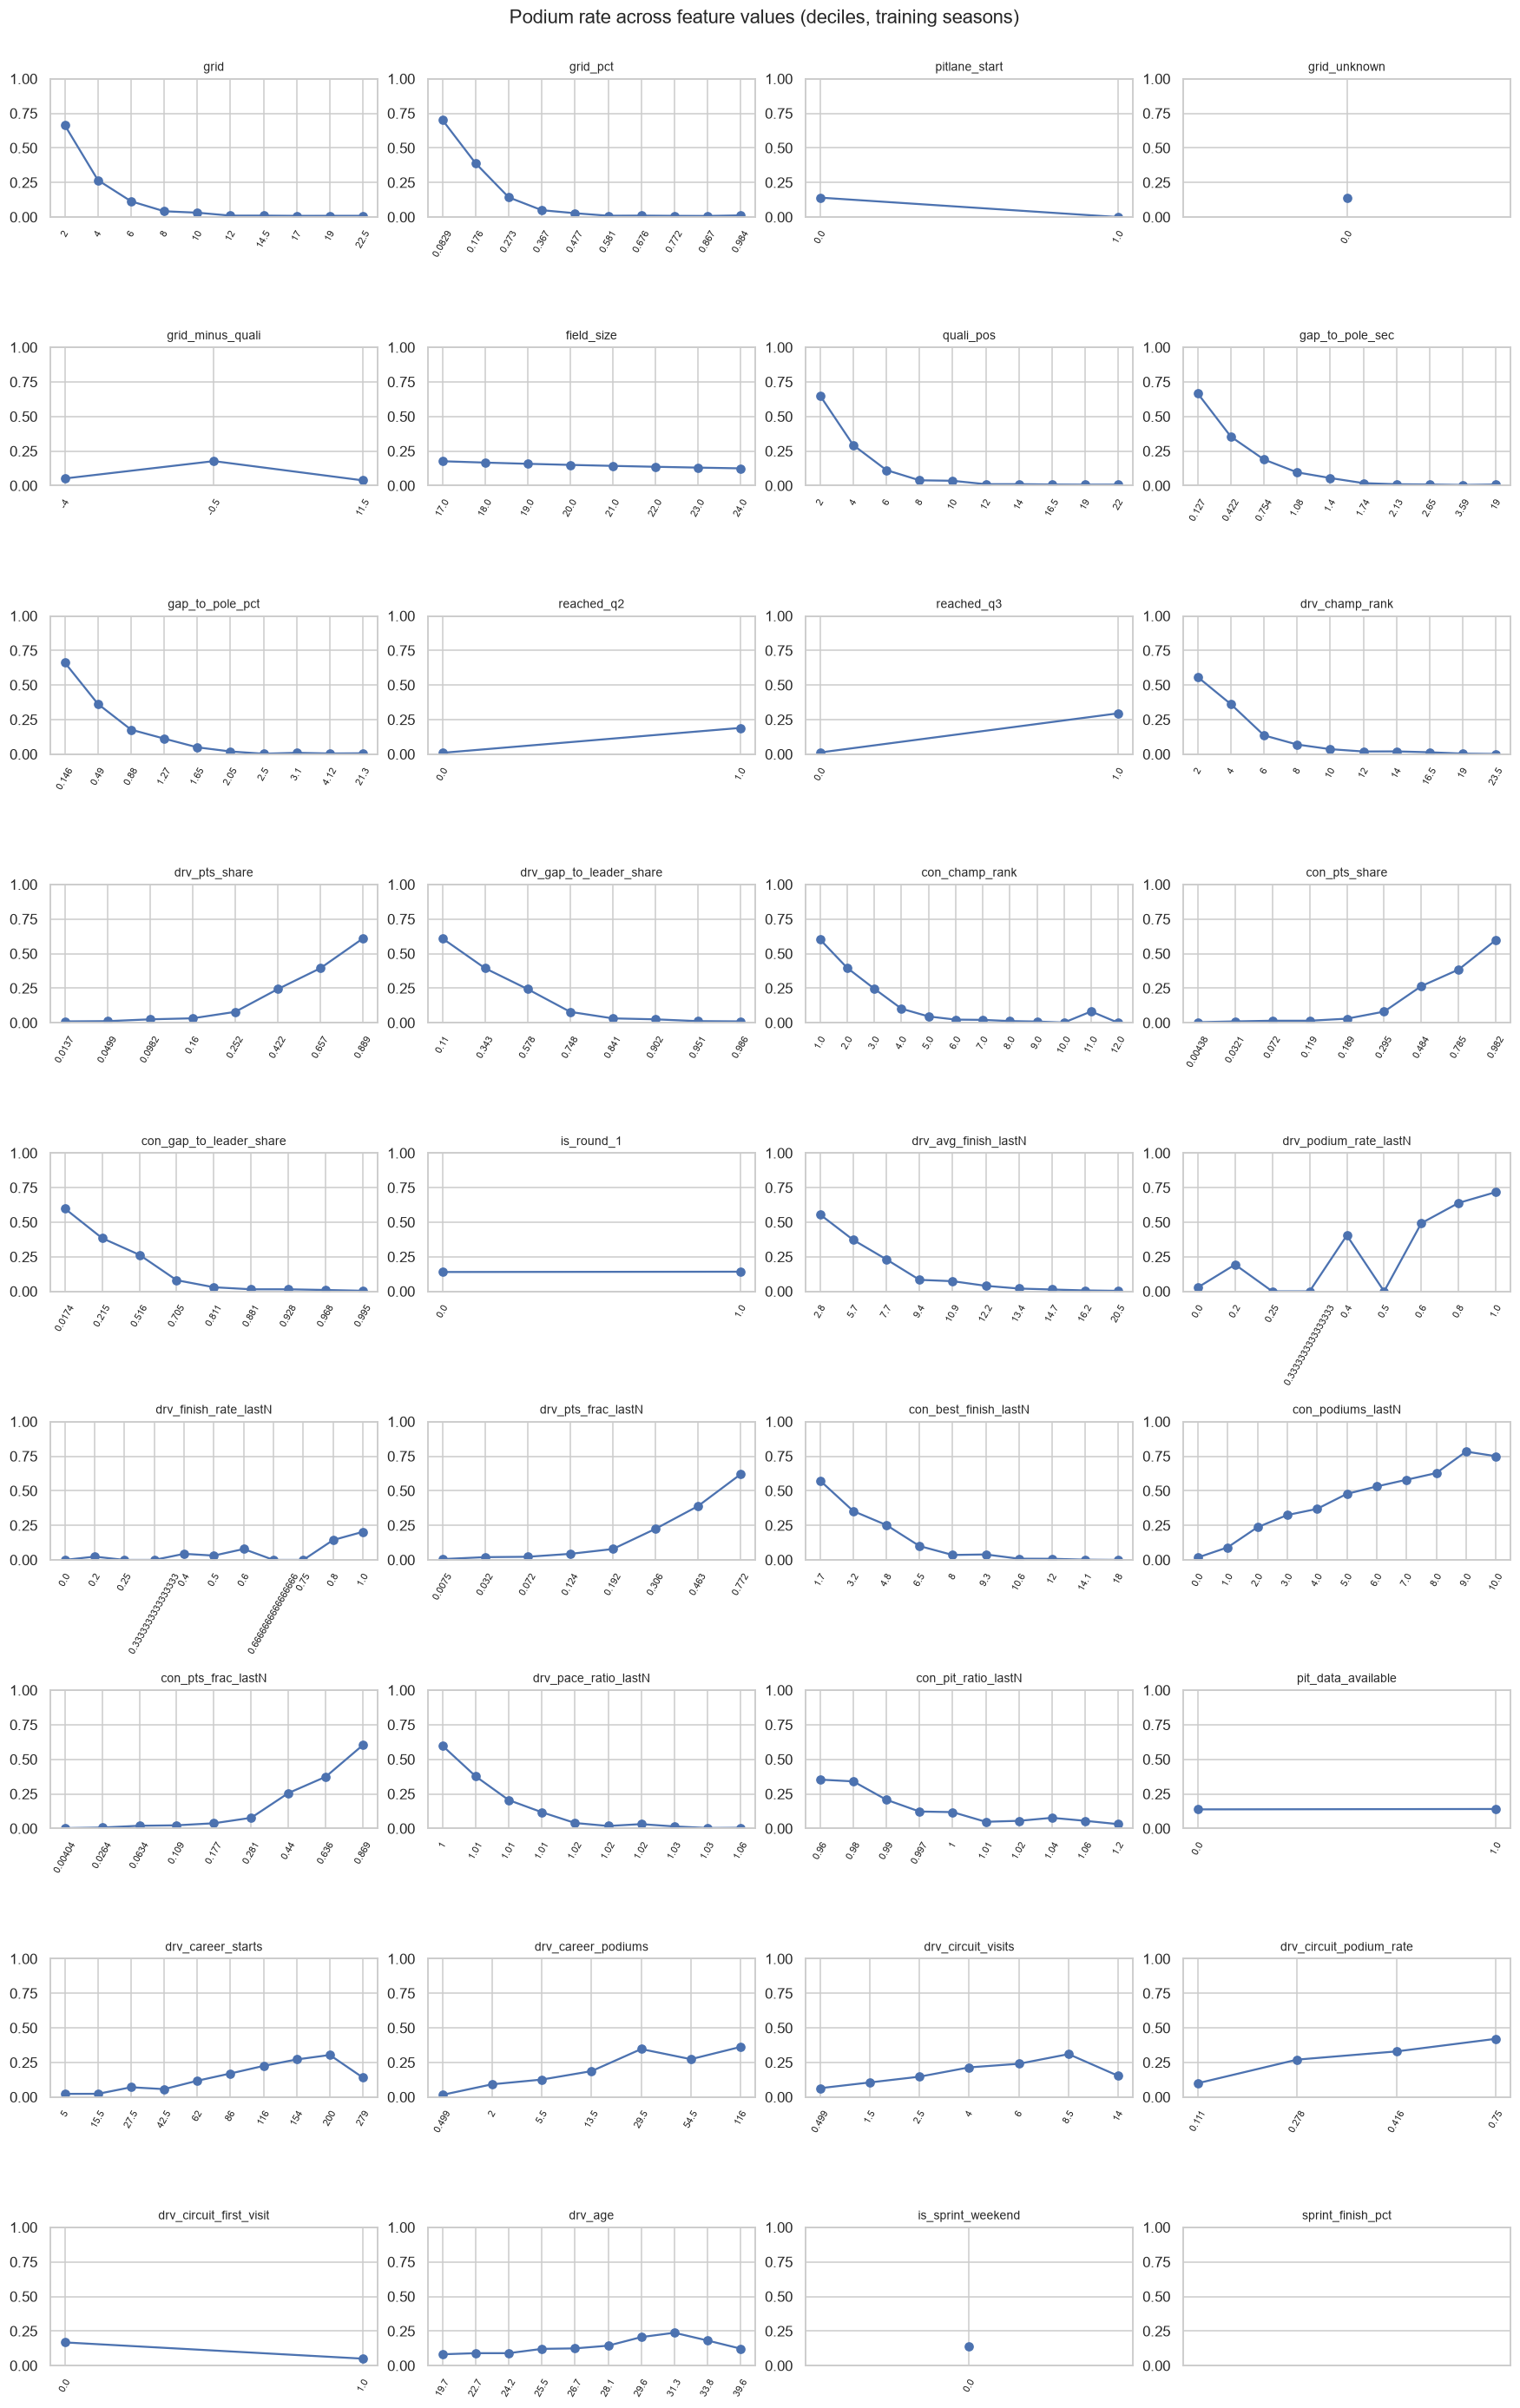

In [55]:
# Podium rate vs each feature (quantile bins) — one panel per feature
feats = ALL_CANDIDATES
ncol = 4; nrow = int(np.ceil(len(feats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.8 * nrow))
for ax, f in zip(axes.ravel(), feats):
    x = MT_TRAIN[f]
    if x.nunique() <= 12:
        g = MT_TRAIN.groupby(x).podium.mean()
    else:
        g = MT_TRAIN.groupby(pd.qcut(x, 10, duplicates="drop"), observed=True).podium.mean()
        g.index = [f"{i.mid:.3g}" for i in g.index]
    ax.plot(range(len(g)), g.values, marker="o"); ax.set_xticks(range(len(g)), g.index, rotation=60, fontsize=7)
    ax.set_title(f, fontsize=9); ax.set_ylim(0, 1)
for ax in axes.ravel()[len(feats):]: ax.axis("off")
fig.suptitle("Podium rate across feature values (deciles, training seasons)", y=1.0)
plt.tight_layout(); savefig("features_univariate_podium_rate")

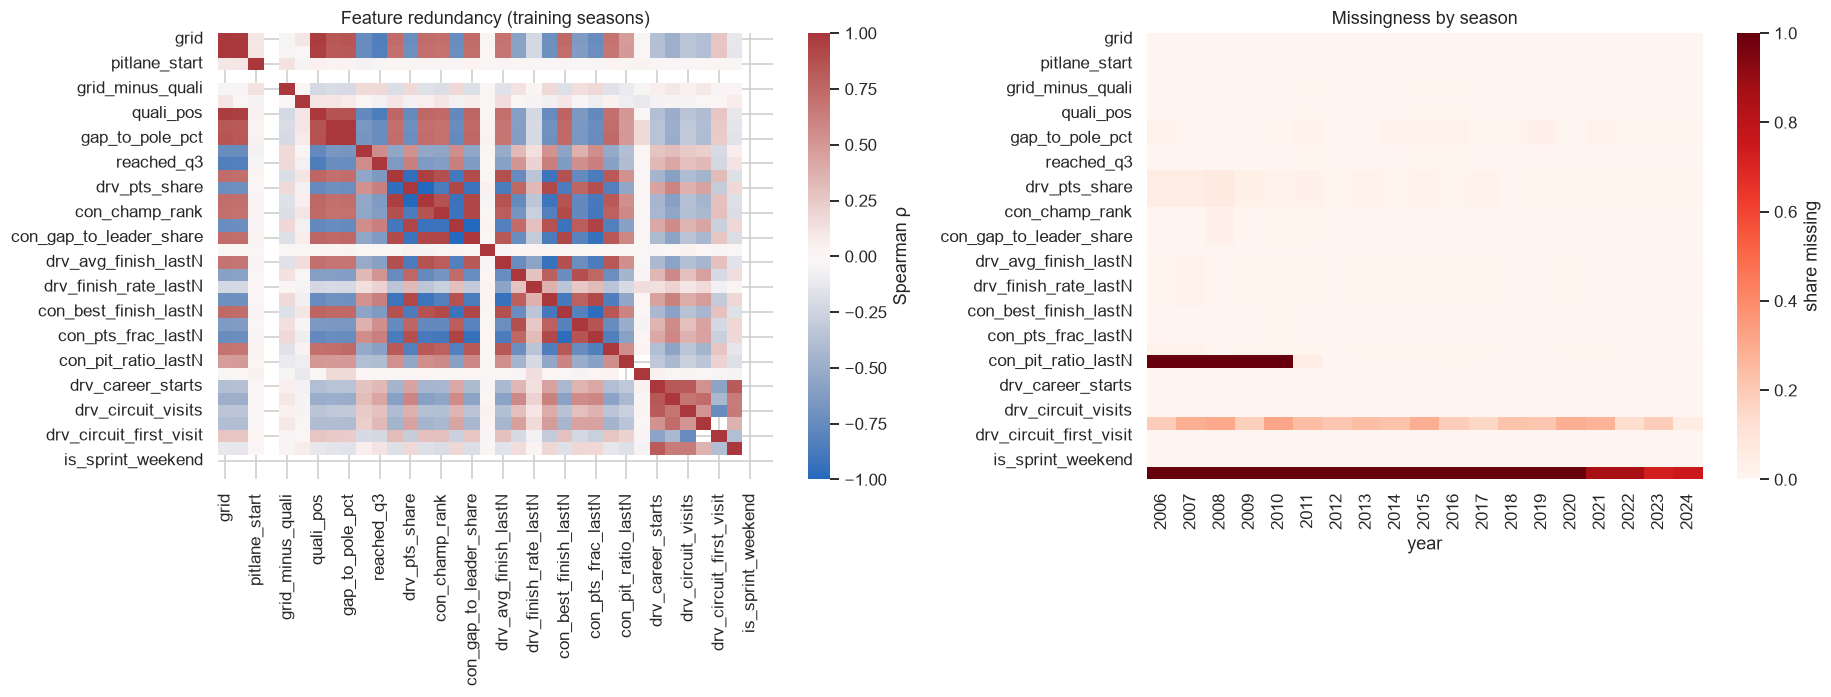

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(MT_TRAIN[ALL_CANDIDATES].corr(method="spearman"), cmap="vlag", center=0, ax=axes[0], cbar_kws={"label": "Spearman ρ"})
axes[0].set_title("Feature redundancy (training seasons)")
miss = MT.groupby("year")[ALL_CANDIDATES].apply(lambda d: d.isna().mean())
sns.heatmap(miss.T, cmap="Reds", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "share missing"})
axes[1].set_title("Missingness by season")
plt.tight_layout(); savefig("features_corr_and_missingness")

In [57]:
# DECISION (§9): rule-based selection on the TRAINING seasons only — validation and test never inform the choice.
# Rule 1: drop features that are empty or constant in the training seasons (the model cannot learn from them).
# Rule 2: greedy redundancy filter — visit features by univariate AUC (high -> low); drop a feature whose |Spearman rho|
#         with an already-kept feature is >= 0.95 (it duplicates information the model already has).
REDUNDANCY_RHO = 0.95
DROPPED = {}
for f in ALL_CANDIDATES:
    x = MT_TRAIN[f]
    if x.notna().sum() == 0:
        DROPPED[f] = "empty in the training seasons"
    elif x.nunique(dropna=True) <= 1:
        DROPPED[f] = f"constant in the training seasons (= {x.dropna().iloc[0]:g})"
auc = EVIDENCE.set_index("feature").univariate_auc
rho = MT_TRAIN[ALL_CANDIDATES].corr(method="spearman").abs()
order = sorted([f for f in ALL_CANDIDATES if f not in DROPPED], key=lambda f: -auc[f])   # stable: ties keep list order
selected = []
for f in order:
    partner = next((s for s in selected if rho.loc[f, s] >= REDUNDANCY_RHO), None)
    if partner:
        DROPPED[f] = f"|rho| = {rho.loc[f, partner]:.3f} with {partner} (univariate AUC {auc[f]:.3f} vs {auc[partner]:.3f})"
    else:
        selected.append(f)

FEATURES = [f for f in ALL_CANDIDATES if f in selected]
SELECTED_GROUPS = {g: [f for f in fs if f in selected] for g, fs in FEATURE_GROUPS.items()}
SELECTED_GROUPS = {g: fs for g, fs in SELECTED_GROUPS.items() if fs}
CATEGORICAL = []   # DECISION: no one-hot IDs — team/circuit strength is already carried by form and standings
FEATURE_SELECTION = pd.DataFrame({"feature": ALL_CANDIDATES,
                                  "group": [next(g for g, fs in FEATURE_GROUPS.items() if f in fs) for f in ALL_CANDIDATES],
                                  "kept": [f in selected for f in ALL_CANDIDATES],
                                  "reason_dropped": [DROPPED.get(f, "") for f in ALL_CANDIDATES]})
FEATURE_SELECTION.to_csv(OUT_DIR / "feature_selection.csv", index=False)
print(f"{len(FEATURES)} of {len(ALL_CANDIDATES)} features kept; groups: {list(SELECTED_GROUPS)}")
FEATURE_SELECTION[~FEATURE_SELECTION.kept]

26 of 36 features kept; groups: ['grid', 'qualifying', 'standings', 'driver_form', 'constructor_form', 'pace_pit', 'experience']


,feature,group,kept,reason_dropped
0,grid,grid,False,|rho| = 0.969 with quali_pos (univariate AUC 0...
1,grid_pct,grid,False,|rho| = 0.958 with quali_pos (univariate AUC 0...
3,grid_unknown,grid,False,constant in the training seasons (= 0)
7,gap_to_pole_sec,qualifying,False,|rho| = 0.988 with gap_to_pole_pct (univariate...
12,drv_pts_share,standings,False,|rho| = 0.959 with drv_champ_rank (univariate ...
13,drv_gap_to_leader_share,standings,False,|rho| = 0.959 with drv_champ_rank (univariate ...
15,con_pts_share,standings,False,|rho| = 1.000 with con_gap_to_leader_share (un...
22,con_best_finish_lastN,constructor_form,False,|rho| = 0.972 with con_pts_frac_lastN (univari...
34,is_sprint_weekend,sprint,False,constant in the training seasons (= 0)
35,sprint_finish_pct,sprint,False,empty in the training seasons


✍️ **WRITE-UP (feature selection)**
- **Rule (training seasons 2006–2020 only):**
  1. drop features that are empty or constant in training;
  2. apply a greedy redundancy filter: drop a feature whose |Spearman ρ| with a kept feature of higher univariate AUC is ≥ 0.95.

  **26 of 36** features are kept (`outputs/feature_selection.csv`).
- **Dropped:**
  - `grid` and `grid_pct` (ρ 0.97 / 0.96 with `quali_pos`). Grid is still recoverable as `quali_pos + grid_minus_quali`.
  - `gap_to_pole_sec` (0.99 with the percentage version, which is comparable across circuits).
  - `drv_pts_share` and `drv_gap_to_leader_share` (0.96 with `drv_champ_rank`).
  - `con_pts_share` (1.00 with `con_gap_to_leader_share`).
  - `con_best_finish_lastN` (0.97 with `con_pts_frac_lastN`).
  - `grid_unknown` and `is_sprint_weekend` (constant in training).
  - `sprint_finish_pct` (empty: sprints only start in 2021).
- **Evidence for the kept features** (univariate AUC on train):
  - qualifying: `quali_pos` 0.92, `gap_to_pole_pct` 0.90;
  - standings: `con_gap_to_leader_share` 0.90, `drv_champ_rank` 0.89;
  - form: `drv_pts_frac_lastN` 0.90, `con_pts_frac_lastN` 0.90, `drv_pace_ratio_lastN` 0.89;
  - experience: `drv_career_podiums` 0.80.

  Weak on their own but kept as context for interactions: `grid_minus_quali` 0.56 (penalties), `drv_age` 0.58, `pitlane_start` (rare but large effect), and `field_size`, `is_round_1`, `pit_data_available`. These tell the model when other features are less reliable.
- **All valid at the cutoff:**
  - qualifying and grid are known once the grid is set;
  - standings come from the previous round (round 1: last season's final standings), asserted ✅;
  - form, points share, pace, pit and circuit history use only earlier races (`shift(1)`; leakage test on 300 rows ✅);
  - age is known.

  No current-race outcome is in the whitelist.

## 10. Train / validation / test split
Rows are not i.i.d.: drivers' form carries over between races and the sport drifts from season to season. A **time-based split by season** (whole races stay together) mirrors real use: predict the future from the past.
**Split (cleaning plan §1):** train = first scope season … 2020, validation 2021–22, test 2023–24. Validation and test are identical for both scopes, which keeps the scope comparison (§14.2) fair. Validation includes 2022, the first season of the ground-effect regulations, so model selection already sees the newest era.

,rows,races,seasons,podium_rate
split,,,,
test,918,46,2023–2024,0.150327
train,6108,285,2006–2020,0.139980
val,879,44,2021–2022,0.150171


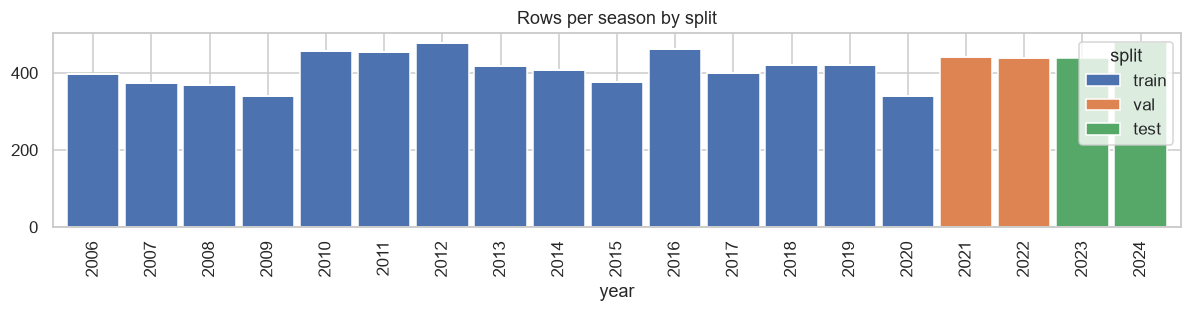

In [58]:
TRAIN_YEARS = (SCOPE_FROM, TRAIN_END)

split = np.select([MT.year.between(*TRAIN_YEARS), MT.year.between(*VAL_YEARS), MT.year.between(*TEST_YEARS)],
                  ["train", "val", "test"], default="unused")
MT["split"] = split
assert (MT.split != "unused").all()
tr, va, te = (MT[MT.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
X_tr, y_tr = tr[FEATURES + CATEGORICAL], tr[TARGET]
X_va, y_va = va[FEATURES + CATEGORICAL], va[TARGET]
X_te, y_te = te[FEATURES + CATEGORICAL], te[TARGET]

assert set(tr.raceId).isdisjoint(va.raceId) and set(va.raceId).isdisjoint(te.raceId)
summary = MT.groupby("split").agg(rows=("podium", "size"), races=("raceId", "nunique"),
                                  seasons=("year", lambda s: f"{s.min()}–{s.max()}"), podium_rate=("podium", "mean"))
display(summary)

fig, ax = plt.subplots(figsize=(11, 3))
MT.groupby(["year", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]].plot.bar(stacked=True, ax=ax, width=.9)
ax.set_title("Rows per season by split"); plt.tight_layout(); savefig("split_rows_per_season")

## 11. Preprocessing ✅ + preprocessing-order experiments

transformed train shape: (6108, 43)


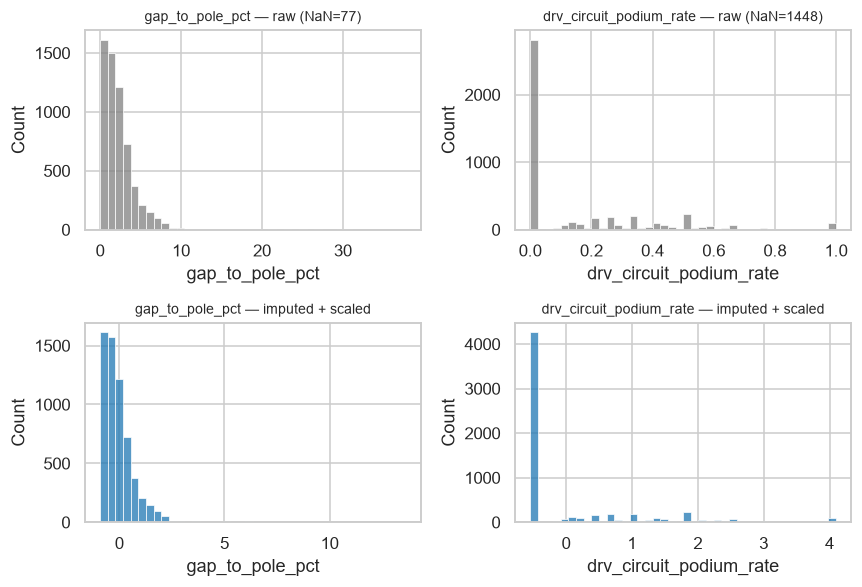

,raw_mean,raw_std,raw_nan,after_mean,after_std,after_nan
gap_to_pole_pct,2.378,2.615,77,0.0,1.0,0
drv_circuit_podium_rate,0.154,0.235,1448,0.0,1.0,0


In [59]:
def make_preprocessor(numeric=None, categorical=None, impute="median", scale=True, order="impute_then_scale",
                      add_indicator=True):
    numeric = FEATURES if numeric is None else numeric
    categorical = CATEGORICAL if categorical is None else categorical
    imp = SimpleImputer(strategy=impute, add_indicator=add_indicator)
    if not scale:
        num_steps = [("impute", imp)]
    elif order == "impute_then_scale":
        num_steps = [("impute", imp), ("scale", StandardScaler())]
    else:  # scale_then_impute: StandardScaler ignores NaN when fitting
        num_steps = [("scale", StandardScaler()), ("impute", imp)]
    transformers = [("num", Pipeline(num_steps), numeric)]
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

pre = make_preprocessor().fit(X_tr)
Xt_tr = pd.DataFrame(pre.transform(X_tr), columns=pre.get_feature_names_out())
print("transformed train shape:", Xt_tr.shape)

# Effect of preprocessing on distributions / ranges
show = [f for f in ["grid", "gap_to_pole_pct", "drv_pts_share", "drv_circuit_podium_rate"] if f in FEATURES]
fig, axes = plt.subplots(2, len(show), figsize=(4 * len(show), 5.5))
for j, f in enumerate(show):
    sns.histplot(X_tr[f], bins=40, ax=axes[0, j], color="grey"); axes[0, j].set_title(f"{f} — raw (NaN={X_tr[f].isna().sum()})", fontsize=9)
    sns.histplot(Xt_tr[f], bins=40, ax=axes[1, j], color="tab:blue"); axes[1, j].set_title(f"{f} — imputed + scaled", fontsize=9)
plt.tight_layout(); savefig("preprocessing_effect")
pd.DataFrame({"raw_mean": X_tr[show].mean(), "raw_std": X_tr[show].std(), "raw_nan": X_tr[show].isna().sum(),
              "after_mean": Xt_tr[show].mean(), "after_std": Xt_tr[show].std(), "after_nan": Xt_tr[show].isna().sum()}).round(3)

## 12. Evaluation harness ✅
Five metrics per model and split: **ROC-AUC, PR-AUC, F1, precision, recall** (F1/precision/recall at a threshold chosen on validation). The test set is only touched in §14.

In [60]:
PRIMARY_METRIC = "pr_auc"      # DECISION: podiums are ~14 % of rows; PR-AUC rewards ranking podium finishers on top
SECONDARY_METRIC = "f1"        # DECISION: quality of the actual yes/no call at the validation-chosen threshold
THRESHOLD_STRATEGY = "max_f1"  # DECISION: beat "top 3 per race" on validation for every model (§13.5)

def get_proba(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return np.asarray(model.predict(X, verbose=0)).ravel()   # Keras wrapper

def top3_labels(proba, race_ids):
    # Domain rule: exactly 3 podium predictions per race (highest probabilities).
    r = pd.Series(proba).groupby(np.asarray(race_ids)).rank(ascending=False, method="first")
    return (r <= 3).astype(int).to_numpy()

def choose_threshold(y, proba, strategy=None):
    strategy = strategy or THRESHOLD_STRATEGY
    if strategy == "fixed_0.5" or strategy == "top3_per_race":
        return 0.5
    p, r, t = precision_recall_curve(y, proba)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])

def evaluate(y, proba, threshold, race_ids=None):
    pred = top3_labels(proba, race_ids) if (THRESHOLD_STRATEGY == "top3_per_race" and race_ids is not None) \
           else (proba >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y, proba), "pr_auc": average_precision_score(y, proba),
            "f1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0)}

RESULTS, MODELS = [], {}

def register(name, model, features=None, note=""):
    # Fit is done by the caller. Threshold is chosen on VALIDATION; logs train + val metrics.
    feats = features or (FEATURES + CATEGORICAL)
    p_tr, p_va = get_proba(model, tr[feats]), get_proba(model, va[feats])
    thr = choose_threshold(y_va, p_va)
    MODELS[name] = {"model": model, "features": feats, "threshold": thr, "note": note}
    for split_name, y, p, rid in [("train", y_tr, p_tr, tr.raceId), ("val", y_va, p_va, va.raceId)]:
        RESULTS.append({"model": name, "split": split_name, "threshold": thr, **evaluate(y, p, thr, rid), "note": note})
    return pd.DataFrame([r for r in RESULTS if r["model"] == name]).set_index("split").round(4)

def results_table(splits=("train", "val")):
    d = pd.DataFrame(RESULTS)
    d = d[d.split.isin(splits)].drop_duplicates(["model", "split"], keep="last")
    return d.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "f1", "precision", "recall"]).round(4)

In [61]:
# ---- Preprocessing-order experiments (same model, same features; only the preprocessing changes) ----
def lr_pipe(pre_, **kw):
    return Pipeline([("pre", pre_), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", **kw))])

exp = []
# E1: impute -> scale  vs  scale -> impute
for order in ["impute_then_scale", "scale_then_impute"]:
    m = lr_pipe(make_preprocessor(order=order)).fit(X_tr, y_tr)
    exp.append({"experiment": "E1 order", "variant": order, **evaluate(y_va, get_proba(m, X_va), 0.5)})
# E2: fit preprocessing on TRAIN only  vs  on ALL data before splitting (leaky)
m = lr_pipe(make_preprocessor()).fit(X_tr, y_tr)
exp.append({"experiment": "E2 fit scope", "variant": "fit on train only", **evaluate(y_va, get_proba(m, X_va), 0.5)})
leaky_pre = make_preprocessor().fit(pd.concat([X_tr, X_va, X_te]))
clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(leaky_pre.transform(X_tr), y_tr)
exp.append({"experiment": "E2 fit scope", "variant": "fit on all data (leaky)",
            **evaluate(y_va, clf.predict_proba(leaky_pre.transform(X_va))[:, 1], 0.5)})
# E3: missing-value indicators on / off
for ind in [True, False]:
    m = lr_pipe(make_preprocessor(add_indicator=ind)).fit(X_tr, y_tr)
    exp.append({"experiment": "E3 indicators", "variant": f"add_indicator={ind}", **evaluate(y_va, get_proba(m, X_va), 0.5)})

PREPROC_EXPERIMENTS = pd.DataFrame(exp).round(4)
PREPROC_EXPERIMENTS.to_csv(OUT_DIR / "preprocessing_experiments.csv", index=False)
PREPROC_EXPERIMENTS

,experiment,variant,roc_auc,pr_auc,f1,precision,recall
0,E1 order,impute_then_scale,0.9472,0.7223,0.6816,0.5398,0.9242
1,E1 order,scale_then_impute,0.9473,0.7217,0.6852,0.5419,0.9318
2,E2 fit scope,fit on train only,0.9472,0.7223,0.6816,0.5398,0.9242
3,E2 fit scope,fit on all data (leaky),0.9472,0.7215,0.6816,0.5398,0.9242
4,E3 indicators,add_indicator=True,0.9472,0.7223,0.6816,0.5398,0.9242
5,E3 indicators,add_indicator=False,0.9464,0.7163,0.6852,0.5419,0.9318


✍️ **WRITE-UP (preprocessing experiments)** (validation PR-AUC, logistic regression)
- **E1, order:** impute → scale 0.7223 vs scale → impute 0.7217. Only about 2.6 % of cells are imputed, and scale-first just puts the imputed value at the median of the *scaled* column instead of the raw median, so the difference is negligible.
- **E2, fit scope:** fitting the imputer and scaler on all data, including validation and test, gives 0.7215 vs 0.7223 with train-only fitting. It brings no gain and would be leakage, so train-only fitting is kept on principle. The effect is small because these scale-free features barely drift between 2006–20 and 2021–24.
- **E3, missing-value indicators:** with indicators 0.7223, without 0.7163 (+0.006). Missingness itself is informative: no previous standings means a rookie or a new team, and no pit data means before 2011. So `add_indicator=True` is kept.
- The preprocessing figure shows the effect on the distributions: centred, unit variance, NaN filled.

## 13. Models
At least **three distinct attempts** are shown, each in its own cell, all on the same rows and features: reference rule → **logistic regression baseline** → tuned LR → random forest → tuned RF → shallow FFNN.

In [62]:
# Reference (not a learned model): rank by starting grid. Tells us what the models must beat.
class GridRule:
    def predict_proba(self, X):
        g = X["grid"].where(X["grid"] > 0, 99).fillna(99).to_numpy(float)
        s = 1 / g
        return np.column_stack([1 - s, s])
register("ref_grid_rule", GridRule(), features=["grid"], note="1/grid score, not learned")

,model,threshold,roc_auc,pr_auc,f1,precision,recall,note
split,,,,,,,,
train,ref_grid_rule,0.25,0.9182,0.6441,0.6660,0.5830,0.7766,"1/grid score, not learned"
val,ref_grid_rule,0.25,0.9113,0.6293,0.6688,0.5852,0.7803,"1/grid score, not learned"


### 13.1 Baseline — logistic regression ✅

In [63]:
lr_base = lr_pipe(make_preprocessor()).fit(X_tr, y_tr)
register("lr_baseline", lr_base, note="C=1, class_weight=balanced")

,model,threshold,roc_auc,pr_auc,f1,precision,recall,note
split,,,,,,,,
train,lr_baseline,0.7244,0.9395,0.7105,0.6831,0.5986,0.7953,"C=1, class_weight=balanced"
val,lr_baseline,0.7244,0.9472,0.7223,0.7176,0.6391,0.8182,"C=1, class_weight=balanced"


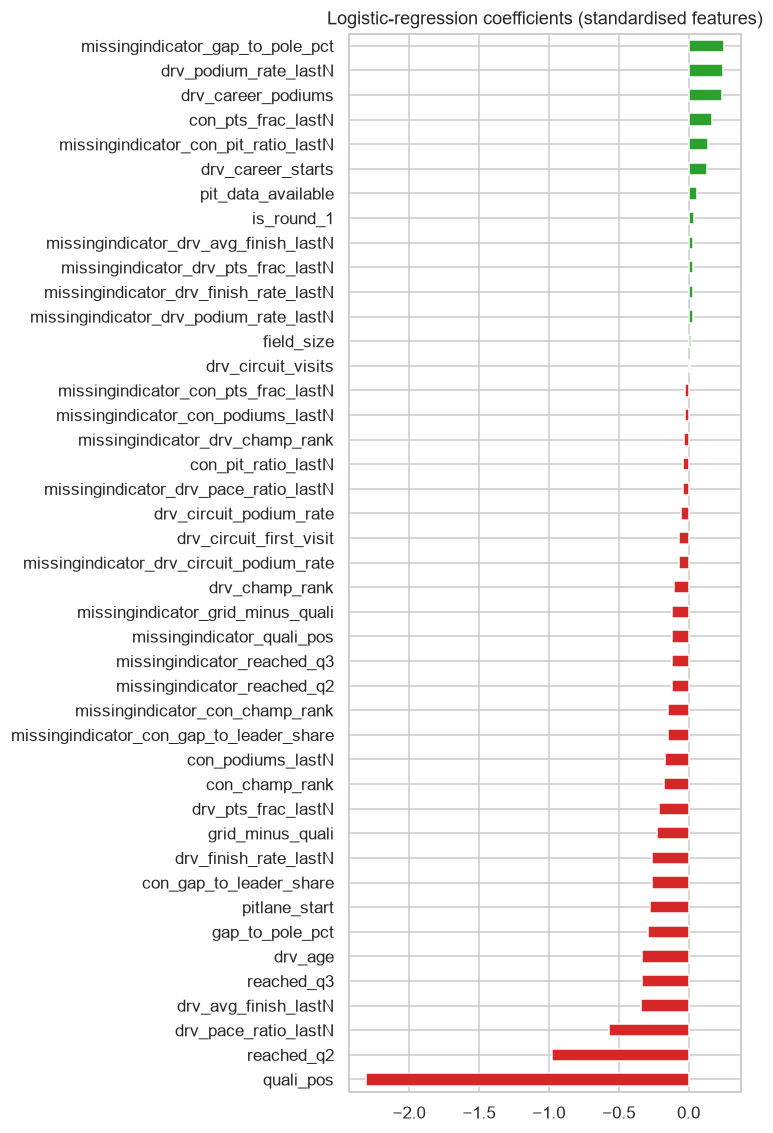

In [64]:
coef = pd.Series(lr_base.named_steps["clf"].coef_[0], index=lr_base.named_steps["pre"].get_feature_names_out()).sort_values()
plt.figure(figsize=(7, 0.22 * len(coef) + 1)); coef.plot.barh(color=np.where(coef > 0, "tab:green", "tab:red"))
plt.title("Logistic-regression coefficients (standardised features)"); plt.tight_layout(); savefig("lr_coefficients")

### 13.2 Hyperparameter tuning on validation ✅

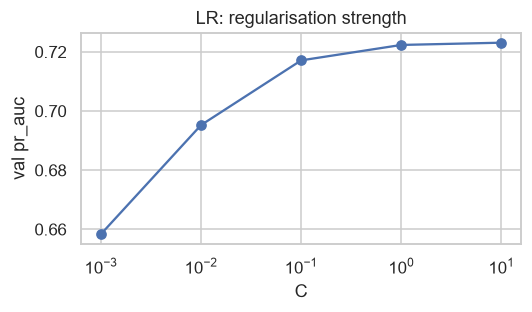

,model,threshold,roc_auc,pr_auc,f1,precision,recall,note
split,,,,,,,,
train,lr_tuned,0.7241,0.9396,0.7104,0.6830,0.5979,0.7965,C=10.0
val,lr_tuned,0.7241,0.9472,0.7231,0.7176,0.6391,0.8182,C=10.0


In [65]:
def tune_on_val(name, make_model, grid, metric=None):
    metric = metric or PRIMARY_METRIC
    rows = []
    for params in grid:
        m = make_model(**params).fit(X_tr, y_tr)
        rows.append({**params, metric: evaluate(y_va, get_proba(m, X_va), 0.5)[metric]})
    res = pd.DataFrame(rows).sort_values(metric, ascending=False)
    res.to_csv(OUT_DIR / f"tuning_{name}.csv", index=False)
    best = {k: v for k, v in res.iloc[0].items() if k != metric}
    best = {k: (int(v) if isinstance(v, float) and float(v).is_integer() and k != "C" else v) for k, v in best.items()}
    return best, res

LR_GRID = [{"C": c} for c in [0.001, 0.01, 0.1, 1, 10]]          # DECISION: log-spaced, strong -> weak regularisation
best_lr, lr_tuning = tune_on_val("lr", lambda C: lr_pipe(make_preprocessor(), C=C), LR_GRID)
plt.figure(figsize=(5, 3)); plt.semilogx(lr_tuning.sort_values("C").C, lr_tuning.sort_values("C")[PRIMARY_METRIC], marker="o")
plt.xlabel("C"); plt.ylabel(f"val {PRIMARY_METRIC}"); plt.title("LR: regularisation strength"); plt.tight_layout(); savefig("tuning_lr")

lr_tuned = lr_pipe(make_preprocessor(), C=best_lr["C"]).fit(X_tr, y_tr)
register("lr_tuned", lr_tuned, note=f"C={best_lr['C']}")

### 13.3 Random forest ✅

In [66]:
def rf_pipe(**kw):
    params = dict(n_estimators=300, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample")
    params.update(kw)
    return Pipeline([("pre", make_preprocessor(scale=False)), ("clf", RandomForestClassifier(**params))])

rf_default = rf_pipe().fit(X_tr, y_tr)
register("rf_default", rf_default, note="sklearn defaults, 300 trees")

,model,threshold,roc_auc,pr_auc,f1,precision,recall,note
split,,,,,,,,
train,rf_default,0.2667,1.0000,1.0000,0.9688,0.9396,1.0000,"sklearn defaults, 300 trees"
val,rf_default,0.2667,0.9328,0.6465,0.6990,0.6102,0.8182,"sklearn defaults, 300 trees"


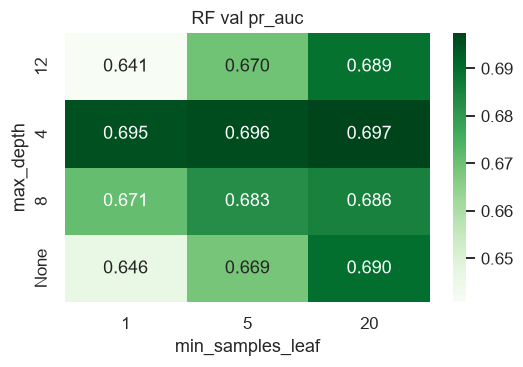

,model,threshold,roc_auc,pr_auc,f1,precision,recall,note
split,,,,,,,,
train,rf_tuned,0.7107,0.9410,0.7051,0.6850,0.5900,0.8164,"{'max_depth': 4, 'min_samples_leaf': 20}"
val,rf_tuned,0.7107,0.9407,0.6974,0.7013,0.6136,0.8182,"{'max_depth': 4, 'min_samples_leaf': 20}"


In [67]:
RF_GRID = [{"max_depth": d, "min_samples_leaf": l} for d in [4, 8, 12, None] for l in [1, 5, 20]]   # DECISION: depth x leaf size = overfitting control
best_rf, rf_tuning = tune_on_val("rf", lambda **p: rf_pipe(**p), RF_GRID)
pv = rf_tuning.assign(max_depth=rf_tuning.max_depth.fillna(-1).astype(int).astype(str).replace("-1", "None")) \
              .pivot(index="max_depth", columns="min_samples_leaf", values=PRIMARY_METRIC)
plt.figure(figsize=(5, 3.5)); sns.heatmap(pv, annot=True, fmt=".3f", cmap="Greens"); plt.title(f"RF val {PRIMARY_METRIC}")
plt.tight_layout(); savefig("tuning_rf")

best_rf = {k: (None if pd.isna(v) else v) for k, v in best_rf.items()}
rf_tuned = rf_pipe(**best_rf).fit(X_tr, y_tr)
register("rf_tuned", rf_tuned, note=str(best_rf))

### 13.4 Shallow feed-forward neural network (Keras) ✅
Same preprocessor as the LR (impute + scale), fitted on train only. Early stopping watches **validation PR-AUC**.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 43)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,953 (7.63 KB)

 Trainable params: 1,953 (7.63 KB)

 Non-trainable params: 0 (0.00 B)

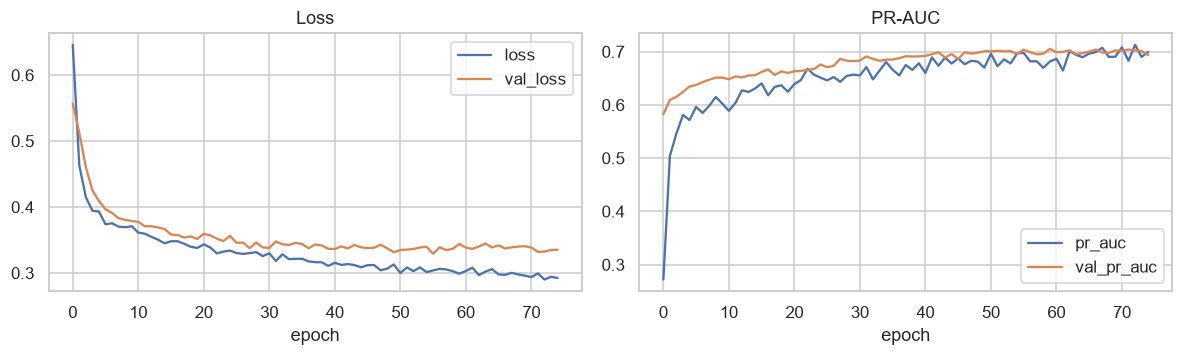

,model,threshold,roc_auc,pr_auc,f1,precision,recall,note
split,,,,,,,,
train,ffnn,0.7009,0.9501,0.7330,0.6935,0.5872,0.8468,"hidden=(32, 16), dropout=0.2, l2=0.0001, epoch..."
val,ffnn,0.7009,0.9426,0.7043,0.7059,0.5969,0.8636,"hidden=(32, 16), dropout=0.2, l2=0.0001, epoch..."


In [68]:
# requires: tensorflow
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(SEED)

NN_HIDDEN = (32, 16)   # DECISION: 2 small layers (~2k weights for ~6k rows): shallow, little room to overfit
NN_DROPOUT = 0.2       # DECISION: light dropout + L2 + early stopping on validation PR-AUC
NN_L2 = 1e-4
NN_LR = 1e-3

nn_pre = make_preprocessor().fit(X_tr)
A_tr, A_va = nn_pre.transform(X_tr).astype("float32"), nn_pre.transform(X_va).astype("float32")

def build_ffnn(n_in, hidden=NN_HIDDEN, dropout=NN_DROPOUT, l2=NN_L2, lr=NN_LR):
    inp = keras.Input(shape=(n_in,))
    x = inp
    for h in hidden:
        x = keras.layers.Dense(h, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.AUC(name="roc_auc")])
    return m

pos = y_tr.mean()
class_weight = {0: 0.5 / (1 - pos), 1: 0.5 / pos}
net = build_ffnn(A_tr.shape[1])
net.summary()
hist = net.fit(A_tr, y_tr.to_numpy(), validation_data=(A_va, y_va.to_numpy()), epochs=200, batch_size=256,
               class_weight=class_weight, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)])

h = pd.DataFrame(hist.history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
h[["loss", "val_loss"]].plot(ax=axes[0], title="Loss"); h[["pr_auc", "val_pr_auc"]].plot(ax=axes[1], title="PR-AUC")
for ax in axes: ax.set_xlabel("epoch")
plt.tight_layout(); savefig("nn_training_curves")

class KerasPipeline:
    # Gives the Keras model the same predict_proba(X_dataframe) interface as the sklearn pipelines.
    def __init__(self, pre, net): self.pre, self.net = pre, net
    def predict_proba(self, X):
        p = self.net.predict(self.pre.transform(X).astype("float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])

ffnn = KerasPipeline(nn_pre, net)
register("ffnn", ffnn, note=f"hidden={NN_HIDDEN}, dropout={NN_DROPOUT}, l2={NN_L2}, epochs={len(h)}")

### 13.5 Train / validation comparison ✅

roc_auc          pr_auc              f1         precision          recall        
split           train     val   train     val   train     val     train     val   train     val
model                                                                                          
ffnn           0.9501  0.9426  0.7330  0.7043  0.6935  0.7059    0.5872  0.5969  0.8468  0.8636
lr_baseline    0.9395  0.9472  0.7105  0.7223  0.6831  0.7176    0.5986  0.6391  0.7953  0.8182
lr_tuned       0.9396  0.9472  0.7104  0.7231  0.6830  0.7176    0.5979  0.6391  0.7965  0.8182
ref_grid_rule  0.9182  0.9113  0.6441  0.6293  0.6660  0.6688    0.5830  0.5852  0.7766  0.7803
rf_default     1.0000  0.9328  1.0000  0.6465  0.9688  0.6990    0.9396  0.6102  1.0000  0.8182
rf_tuned       0.9410  0.9407  0.7051  0.6974  0.6850  0.7013    0.5900  0.6136  0.8164  0.8182

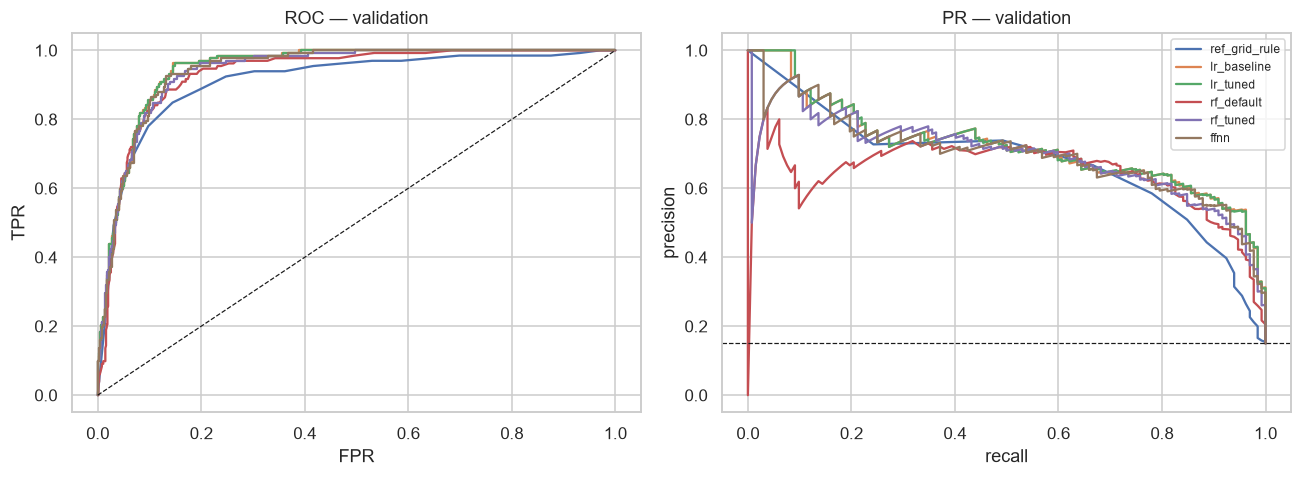

In [69]:
cmp_trval = results_table(("train", "val"))
display(cmp_trval)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, m in MODELS.items():
    p = get_proba(m["model"], va[m["features"]])
    fpr, tpr, _ = roc_curve(y_va, p); prec, rec, _ = precision_recall_curve(y_va, p)
    axes[0].plot(fpr, tpr, label=name); axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set(xlabel="FPR", ylabel="TPR", title="ROC — validation")
axes[1].axhline(y_va.mean(), color="k", ls="--", lw=.8); axes[1].set(xlabel="recall", ylabel="precision", title="PR — validation")
axes[1].legend(fontsize=8); plt.tight_layout(); savefig("val_roc_pr_curves")

In [70]:
# Threshold-strategy evidence (VALIDATION only): max-F1 probability threshold vs "exactly 3 podiums per race"
rows = []
for name, m in MODELS.items():
    p = get_proba(m["model"], va[m["features"]])
    rows.append({"model": name, "threshold": m["threshold"],
                 "val_f1_max_f1_threshold": f1_score(y_va, (p >= m["threshold"]).astype(int)),
                 "val_f1_top3_per_race": f1_score(y_va, top3_labels(p, va.raceId))})
THRESHOLD_CMP = pd.DataFrame(rows).set_index("model").round(4)
THRESHOLD_CMP.to_csv(OUT_DIR / "threshold_strategy.csv")
THRESHOLD_CMP

,threshold,val_f1_max_f1_threshold,val_f1_top3_per_race
model,,,
ref_grid_rule,0.2500,0.6688,0.6667
lr_baseline,0.7244,0.7176,0.6970
lr_tuned,0.7241,0.7176,0.6818
rf_default,0.2667,0.6990,0.6742
rf_tuned,0.7107,0.7013,0.6515
ffnn,0.7009,0.7059,0.6591


✍️ **WRITE-UP (models)** (PR-AUC; train → validation)
- **Reference rule** (rank by 1/grid): validation 0.629, ROC-AUC 0.911. This is the bar every learned model must clear.
- **Logistic regression, baseline:** a linear score of the standardised features passed through a sigmoid. `class_weight="balanced"` counters the 14 % positive rate.
  - 0.711 → **0.722**: no overfitting.
  - Limitation: it models only linear, additive effects, and correlated features split their weight (see the coefficients).
- **Tuned LR (C = 10):** 0.723. Regularisation barely matters with 6,108 rows and 26 features.
- **Random forest:** averages many decision trees fitted on bootstrap samples.
  - Default (unlimited depth) memorises the training data: 1.000 → 0.646.
  - Tuned (depth 4, leaf 20): 0.705 → 0.697. No overfitting, but below LR.
  - Limitation: step-shaped predictions, so it needs depth to model the smooth grid → probability curve.
- **Shallow FFNN** (32-16, dropout 0.2, L2, early stopping on validation PR-AUC): 0.733 → 0.704. Slight overfit and no gain over LR. Limitation: it needs more data to beat a linear model on a few already-informative features.
- **Verdict:** every learned model beats the grid rule by about +0.07–0.09. The extra complexity of RF and FFNN does not beat LR, because the signal is mostly monotonic (qualifying position, form, standings).
- **Threshold:** a max-F1 threshold on validation beats "top 3 per race" for every model (LR: F1 0.718 vs 0.682).

## 14. Final evaluation on the unseen test set ✅
All hyperparameters and thresholds were fixed on validation above. This section is the **only** place the test set is scored.

In [71]:
FINAL_MODEL_NAME = max((n for n in MODELS if n != "ref_grid_rule"),
                       key=lambda n: next(r[PRIMARY_METRIC] for r in reversed(RESULTS) if r["model"] == n and r["split"] == "val"))
# DECISION: best validation PR-AUC (the test set is never used to choose); it is also the simplest model.
print("Final model (by validation", PRIMARY_METRIC, "):", FINAL_MODEL_NAME)

for name, m in MODELS.items():
    p = get_proba(m["model"], te[m["features"]])
    RESULTS.append({"model": name, "split": "test", "threshold": m["threshold"], **evaluate(y_te, p, m["threshold"], te.raceId), "note": m["note"]})

COMPARISON = results_table(("train", "val", "test"))
COMPARISON.to_csv(OUT_DIR / "model_comparison.csv")
COMPARISON

Final model (by validation pr_auc ): lr_tuned


roc_auc                  pr_auc                      f1                 precision                  recall                
split            test   train     val    test   train     val    test   train     val      test   train     val    test   train     val
model                                                                                                                                  
ffnn           0.9247  0.9501  0.9426  0.7127  0.7330  0.7043  0.6554  0.6935  0.7059    0.5370  0.5872  0.5969  0.8406  0.8468  0.8636
lr_baseline    0.9280  0.9395  0.9472  0.7129  0.7105  0.7223  0.6788  0.6831  0.7176    0.5833  0.5986  0.6391  0.8116  0.7953  0.8182
lr_tuned       0.9281  0.9396  0.9472  0.7130  0.7104  0.7231  0.6788  0.6830  0.7176    0.5833  0.5979  0.6391  0.8116  0.7965  0.8182
ref_grid_rule  0.9111  0.9182  0.9113  0.6638  0.6441  0.6293  0.6667  0.6660  0.6688    0.5847  0.5830  0.5852  0.7754  0.7766  0.7803
rf_default     0.9225  1.0000  0.9328  0.6678  1.0000  0.6465  0.6185  0.9688  0.6990    0.5144  0.9396  0.6102  0.7754  1.0000  0.8182
rf_tuned       0.9258  0.9410  0.9407  0.7092  0.7051  0.6974  0.6300  0.6850  0.7013    0.5450  0.5900  0.6136  0.7464  0.8164  0.8182

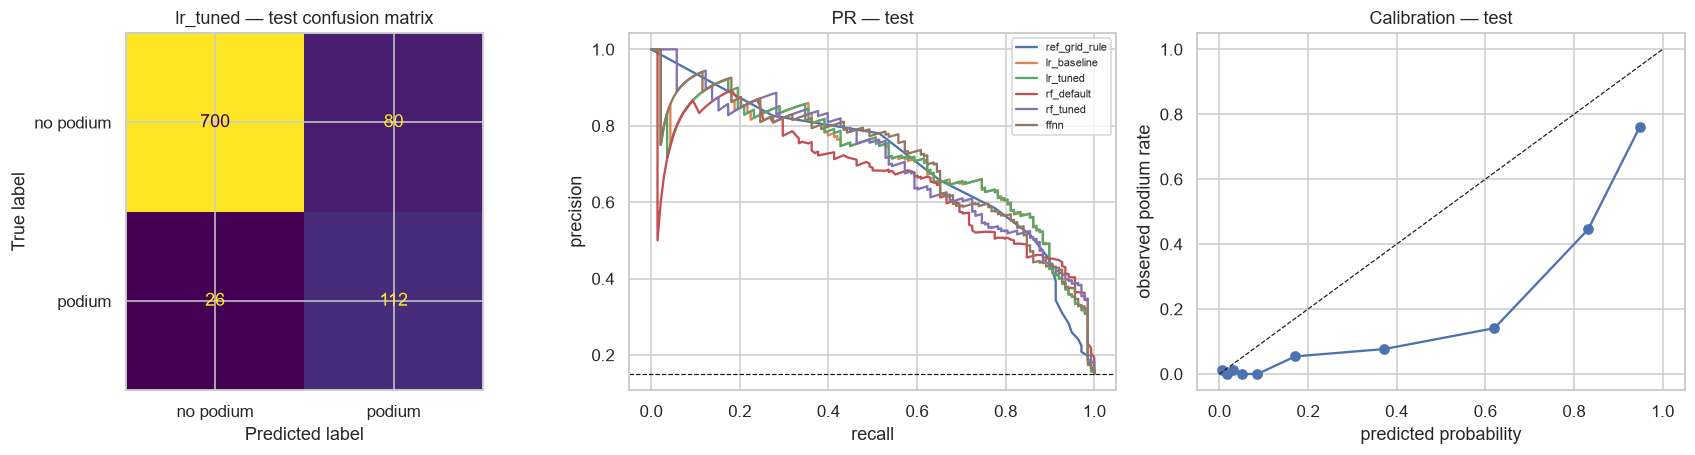

,pr_auc,roc_auc
year,,
2023,0.766,0.929
2024,0.673,0.927


In [72]:
fm = MODELS[FINAL_MODEL_NAME]
p_te = get_proba(fm["model"], te[fm["features"]])
pred_te = top3_labels(p_te, te.raceId) if THRESHOLD_STRATEGY == "top3_per_race" else (p_te >= fm["threshold"]).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["no podium", "podium"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"{FINAL_MODEL_NAME} — test confusion matrix")
for name, m in MODELS.items():
    p = get_proba(m["model"], te[m["features"]]); prec, rec, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rec, prec, label=name)
axes[1].axhline(y_te.mean(), color="k", ls="--", lw=.8); axes[1].set(xlabel="recall", ylabel="precision", title="PR — test"); axes[1].legend(fontsize=7)
frac, mean_p = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
axes[2].plot(mean_p, frac, marker="o"); axes[2].plot([0, 1], [0, 1], "k--", lw=.8)
axes[2].set(xlabel="predicted probability", ylabel="observed podium rate", title="Calibration — test")
plt.tight_layout(); savefig("test_confusion_pr_calibration")

# Per-season stability on test
season = te.assign(p=p_te).groupby("year").apply(lambda d: pd.Series({"pr_auc": average_precision_score(d.podium, d.p),
                                                                       "roc_auc": roc_auc_score(d.podium, d.p)}))
season.round(3)

✍️ **WRITE-UP (test results)**
- **`lr_tuned` on 2023–24:** **PR-AUC 0.713**, ROC-AUC 0.928, F1 0.679 (precision 0.583, recall 0.812). It finds 112 of 138 podiums with 80 false alarms.
- **Generalisation:** the validation → test drop is small (0.723 → 0.713), so the model generalises to unseen seasons of the same regulation era.
- **Per season:** 2023 scores 0.766 and 2024 0.673. 2023 was Red Bull-dominated and predictable; 2024 had four different winning teams.
- **vs reference:** the grid rule scores 0.664 on test, so the model adds +0.049. All learned models land between 0.668 and 0.713 on test; the ordering among RF / FFNN / LR is within noise.
- **Metric choice:**
  - **Primary, PR-AUC:** podiums are 15 % of test rows, and what matters is ranking podium finishers on top. ROC-AUC is inflated by the many easy backmarkers (≈ 0.93 for every model).
  - **Secondary, F1:** the quality of the actual yes/no call at the threshold fixed on validation (0.724).
- **Calibration:** the probabilities are **over-confident** (predicted ≈ 0.6 ↔ observed ≈ 0.15), because `class_weight="balanced"` up-weights podiums about 6×. Use the scores for ranking and thresholding; calibrate (e.g. isotonic regression on validation) if real probabilities are needed.

## 14.2 Scope comparison: modern (2006–2024) vs all seasons (1950–2024)
This is the empirical proof behind D1. The same features and model settings (LR baseline settings, the tuned RF, the FFNN architecture) are fitted on **two training windows**:
- modern: 2006–2020;
- all: 1950–2020.

Both are scored on the **same** validation (2021–22) and test (2023–24) rows. Thresholds are chosen on validation. The scope decision is made on **validation**; test is reported for completeness.

In [73]:
def run_scope(scope):
    a, _ = SCOPE_YEARS[scope]
    trn = FULL_TABLE[FULL_TABLE.year.between(a, TRAIN_END)].reset_index(drop=True)
    val = FULL_TABLE[FULL_TABLE.year.between(*VAL_YEARS)].reset_index(drop=True)
    tst = FULL_TABLE[FULL_TABLE.year.between(*TEST_YEARS)].reset_index(drop=True)
    feats = FEATURES + CATEGORICAL
    Xa, ya = trn[feats], trn[TARGET]
    out = {"scope": scope, "train_seasons": f"{a}–{TRAIN_END}", "train_rows": len(trn),
           "pct_feature_cells_missing": round(100 * trn[FEATURES].isna().to_numpy().mean(), 2),
           "val_rows": len(val), "test_rows": len(tst)}
    models = {"LR": lr_pipe(make_preprocessor(), C=1.0).fit(Xa, ya), "RF": rf_pipe(**best_rf).fit(Xa, ya)}
    pre_s = make_preprocessor().fit(Xa)
    A, Av = pre_s.transform(Xa).astype("float32"), pre_s.transform(val[feats]).astype("float32")
    pos_s = ya.mean()
    tf.keras.utils.set_random_seed(SEED)
    net_s = build_ffnn(A.shape[1])
    net_s.fit(A, ya.to_numpy(), validation_data=(Av, val[TARGET].to_numpy()), epochs=200, batch_size=256, verbose=0,
              class_weight={0: 0.5 / (1 - pos_s), 1: 0.5 / pos_s},
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)])
    models["FFNN"] = KerasPipeline(pre_s, net_s)
    for name, m in models.items():
        pv, pt = get_proba(m, val[feats]), get_proba(m, tst[feats])
        thr = choose_threshold(val[TARGET], pv)
        for split_name, y, p, rid in [("val", val[TARGET], pv, val.raceId), ("test", tst[TARGET], pt, tst.raceId)]:
            for k, v in evaluate(y, p, thr, rid).items():
                if k in ("roc_auc", "pr_auc", "f1"):
                    out[f"{name}_{split_name}_{k}"] = round(v, 4)
    return out

# Same validation / test rows in both scopes (they come from the same FULL_TABLE)
assert MT[MT.split == "val"][["raceId", "driverId"]].reset_index(drop=True).equals(
    FULL_TABLE[FULL_TABLE.year.between(*VAL_YEARS)][["raceId", "driverId"]].reset_index(drop=True))
SCOPE_COMPARISON = pd.DataFrame([run_scope(s) for s in ["modern", "all"]]).set_index("scope")
SCOPE_COMPARISON.to_csv(OUT_DIR / "scope_comparison.csv")
SCOPE_COMPARISON.T

scope,modern,all
train_seasons,2006–2020,1950–2020
train_rows,6108,22958
pct_feature_cells_missing,2.59,20.78
val_rows,879,879
test_rows,918,918
LR_val_roc_auc,0.9472,0.9418
LR_val_pr_auc,0.7223,0.7048
LR_val_f1,0.7176,0.7217
LR_test_roc_auc,0.928,0.9224
LR_test_pr_auc,0.7129,0.6936


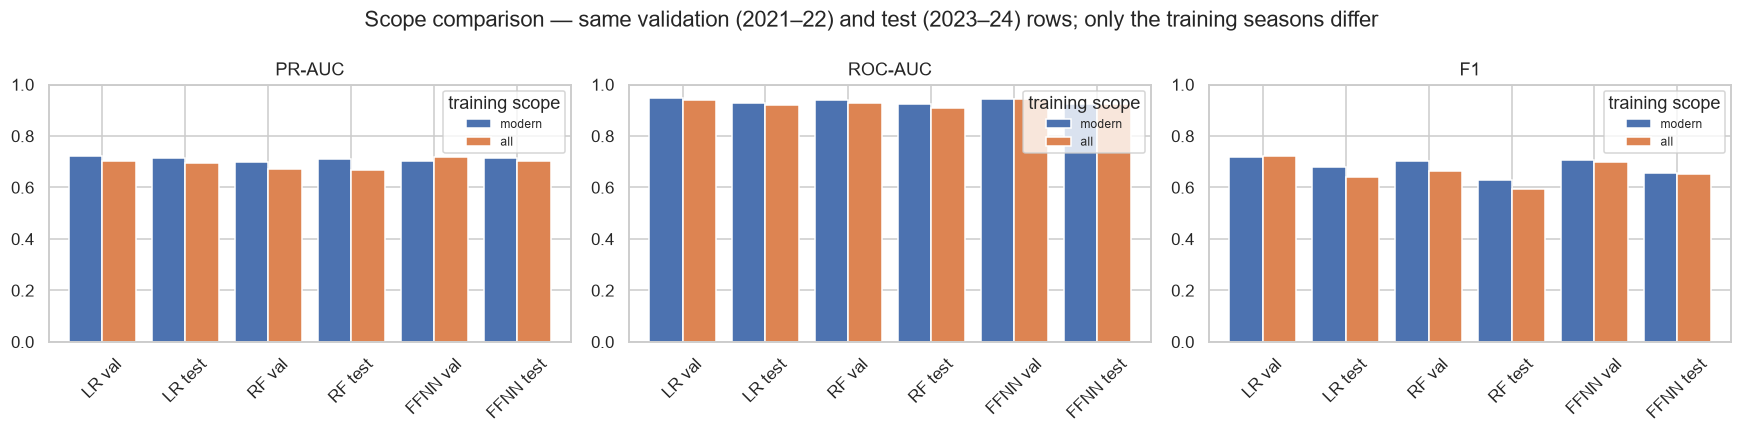

In [74]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["pr_auc", "roc_auc", "f1"]):
    d = pd.DataFrame({f"{m} {s}": SCOPE_COMPARISON[f"{m}_{s}_{metric}"] for m in ["LR", "RF", "FFNN"] for s in ["val", "test"]})
    d.T.plot.bar(ax=ax, rot=45, width=.8); ax.set_title(metric.upper().replace("_", "-")); ax.set_ylim(0, 1)
    ax.legend(title="training scope", fontsize=8)
plt.suptitle("Scope comparison — same validation (2021–22) and test (2023–24) rows; only the training seasons differ")
plt.tight_layout(); savefig("scope_comparison")

✍️ **WRITE-UP (scope comparison)**
- **Setup:** same features, same settings, same 879 validation and 918 test rows. Only the training window differs: 6,108 rows (2006–20) vs 22,958 rows (1950–20).
- **Validation PR-AUC (modern vs all):**

  | model | modern | all | better |
  |---|---|---|---|
  | LR | 0.722 | 0.705 | modern |
  | RF | 0.697 | 0.670 | modern |
  | FFNN | 0.704 | 0.719 | all |

  Test agrees for LR (0.713 vs 0.694) and RF (0.709 vs 0.670). For the FFNN the test result flips to favour modern (0.713 vs 0.701).
- **Why:** 20.8 % of feature cells are missing in the all-seasons training data vs 2.6 % in modern. There is no qualifying data before 1994, grid slots are sometimes unknown, and pace data starts in 1996. Podium patterns from the 1950s–90s (30+ car fields, high retirement rates) also differ from 2021–24. Four times the rows does not make up for this.
- **Decision D1 confirmed:** modern 2006–2024 is the main scope. Two of three models are better on validation, and the definitions are consistent. The FFNN is the exception, and we report it.

## 15. Feature-group ablation ✅
Remove one group at a time, retrain with **fixed** hyperparameters, compare to the full model on validation (and test, for reporting only).

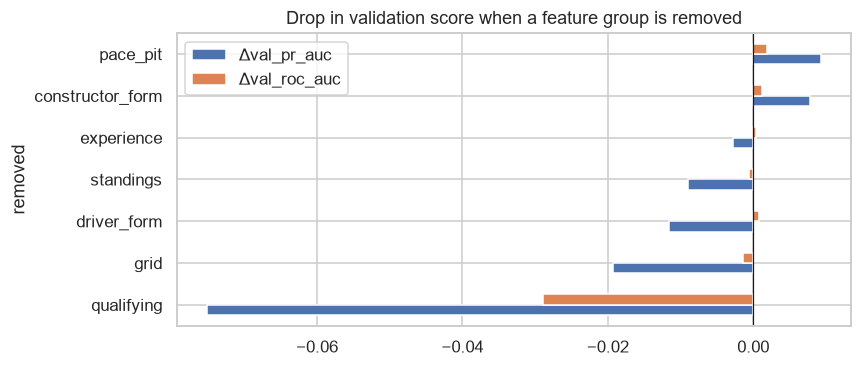

,val_roc_auc,val_pr_auc,val_f1,val_precision,val_recall,test_roc_auc,test_pr_auc,test_f1,test_precision,test_recall,Δval_pr_auc,Δval_roc_auc,Δtest_pr_auc
removed,,,,,,,,,,,,,
(none — full model),0.9407,0.6974,0.6458,0.4921,0.9394,0.9258,0.7092,0.5767,0.4214,0.9130,0.0000,0.0000,0.0000
grid,0.9393,0.6782,0.6474,0.4960,0.9318,0.9256,0.7097,0.5833,0.4286,0.9130,-0.0192,-0.0014,0.0005
qualifying,0.9117,0.6224,0.5917,0.4368,0.9167,0.8893,0.5973,0.5254,0.3713,0.8986,-0.0751,-0.0290,-0.1119
standings,0.9401,0.6885,0.6594,0.5149,0.9167,0.9277,0.7141,0.5799,0.4233,0.9203,-0.0090,-0.0006,0.0049
driver_form,0.9414,0.6858,0.6310,0.4751,0.9394,0.9258,0.7075,0.5746,0.4148,0.9348,-0.0116,0.0007,-0.0018
constructor_form,0.9419,0.7053,0.6423,0.4900,0.9318,0.9272,0.7053,0.5753,0.4200,0.9130,0.0079,0.0012,-0.0040
pace_pit,0.9426,0.7067,0.6525,0.5020,0.9318,0.9273,0.7128,0.5872,0.4295,0.9275,0.0093,0.0019,0.0036
experience,0.9410,0.6946,0.6526,0.5000,0.9394,0.9264,0.7143,0.5839,0.4276,0.9203,-0.0028,0.0003,0.0051


In [75]:
ABLATION_MODEL = lambda: rf_pipe(**best_rf)     # DECISION: tuned RF — no scaling needed, captures interactions

def fit_eval(feats):
    m = Pipeline([("pre", make_preprocessor(numeric=feats, scale=False)), ("clf", ABLATION_MODEL().named_steps["clf"])])
    m.fit(tr[feats + CATEGORICAL], y_tr)
    out = {}
    for s, d, y in [("val", va, y_va), ("test", te, y_te)]:
        out[s] = evaluate(y, get_proba(m, d[feats + CATEGORICAL]), 0.5)
    return out

abl = []
full_scores = fit_eval(FEATURES)
abl.append({"removed": "(none — full model)", **{f"{s}_{k}": v for s, d in full_scores.items() for k, v in d.items()}})
for g, fs in SELECTED_GROUPS.items():
    remaining = [f for f in FEATURES if f not in fs]
    sc = fit_eval(remaining)
    abl.append({"removed": g, **{f"{s}_{k}": v for s, d in sc.items() for k, v in d.items()}})
ABLATION = pd.DataFrame(abl).set_index("removed")
for k in ["val_pr_auc", "val_roc_auc", "test_pr_auc"]:
    ABLATION[f"Δ{k}"] = ABLATION[k] - ABLATION.loc["(none — full model)", k]
ABLATION.to_csv(OUT_DIR / "ablation.csv")

d = ABLATION.drop("(none — full model)")[["Δval_pr_auc", "Δval_roc_auc"]].sort_values("Δval_pr_auc")
d.plot.barh(figsize=(8, 3.5)); plt.axvline(0, color="k", lw=.8)
plt.title("Drop in validation score when a feature group is removed"); plt.tight_layout(); savefig("ablation")
ABLATION.round(4)

✍️ **WRITE-UP (ablation)** (tuned RF, fixed hyperparameters; Δ validation PR-AUC when the group is removed)
- **Qualifying** matters most: **−0.075** (−0.112 on test). It is the core signal.
- **Grid** (−0.019), **driver form** (−0.012) and **standings** (−0.009) add a little; **experience** −0.003.
- Removing **constructor form** (+0.008) or **pace / pit** (+0.009) slightly *improves* validation. Their information is already carried by standings and qualifying (car pace shows up in qualifying), so for this model they mostly add noise.
- **Compared with §9:** grid, standings and form all had univariate AUC ≈ 0.89–0.92, but most of that signal overlaps with qualifying. Univariate evidence measures signal; ablation measures *unique* signal.

## 16. Explainability (XAI)
> **Not causal.** Importance means *the model relies on the feature to predict*, not that the feature *causes* podiums. Correlated features (e.g. grid and qualifying position) share and swap importance.

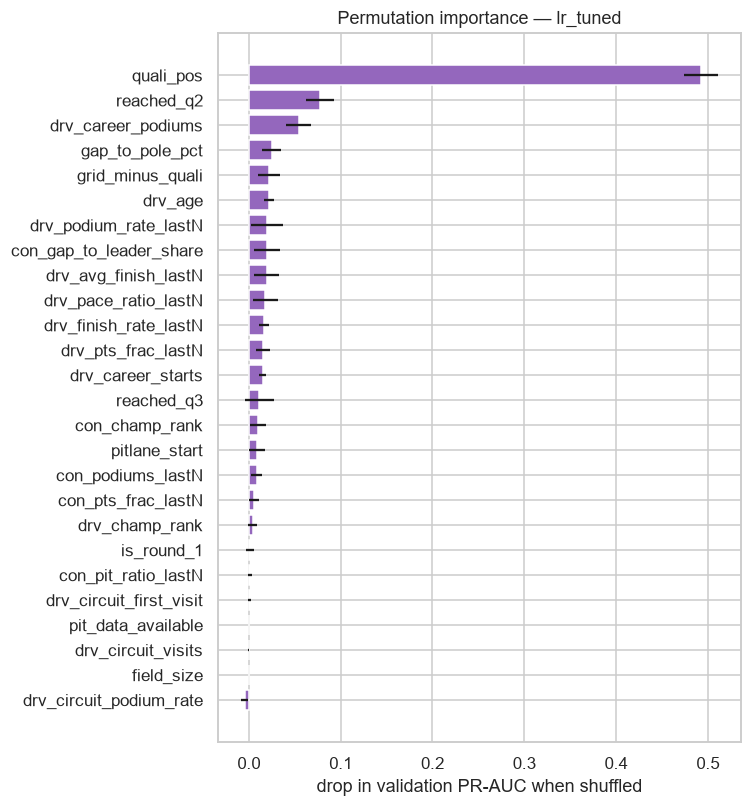

In [76]:
# 16.1 Permutation importance (model-agnostic, on VALIDATION)
XAI_MODEL_NAME = FINAL_MODEL_NAME     # DECISION: explain the model we actually use (§14)
xm = MODELS[XAI_MODEL_NAME]
pi = permutation_importance(xm["model"], va[xm["features"]], y_va, scoring="average_precision",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
PI = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=xm["features"]).sort_values("mean")
PI.to_csv(OUT_DIR / "permutation_importance.csv")
plt.figure(figsize=(7, 0.25 * len(PI) + 1)); plt.barh(PI.index, PI["mean"], xerr=PI["std"], color="tab:purple")
plt.xlabel("drop in validation PR-AUC when shuffled"); plt.title(f"Permutation importance — {XAI_MODEL_NAME}")
plt.tight_layout(); savefig("xai_permutation_importance")

Background dataset has 6108 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6108 when initializing the masker.


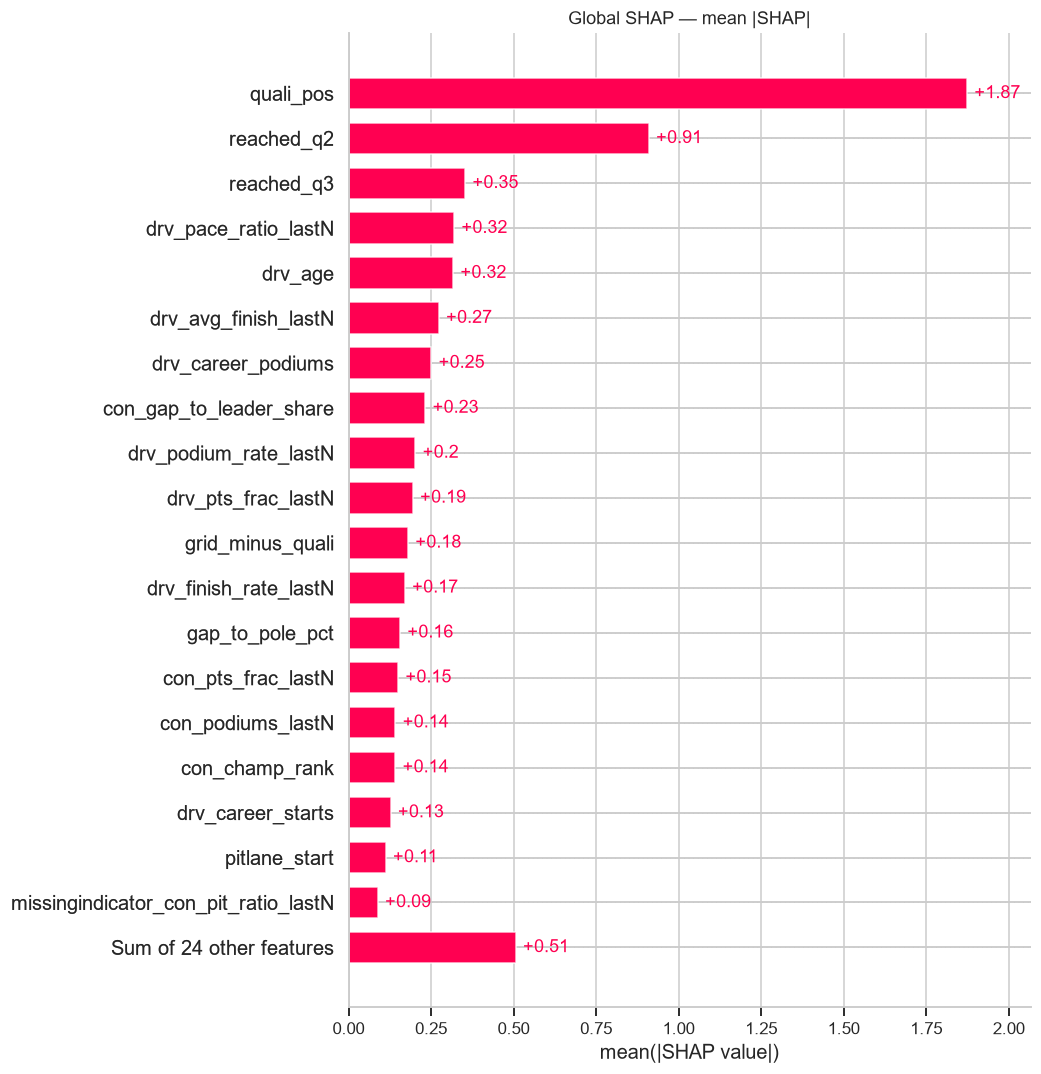

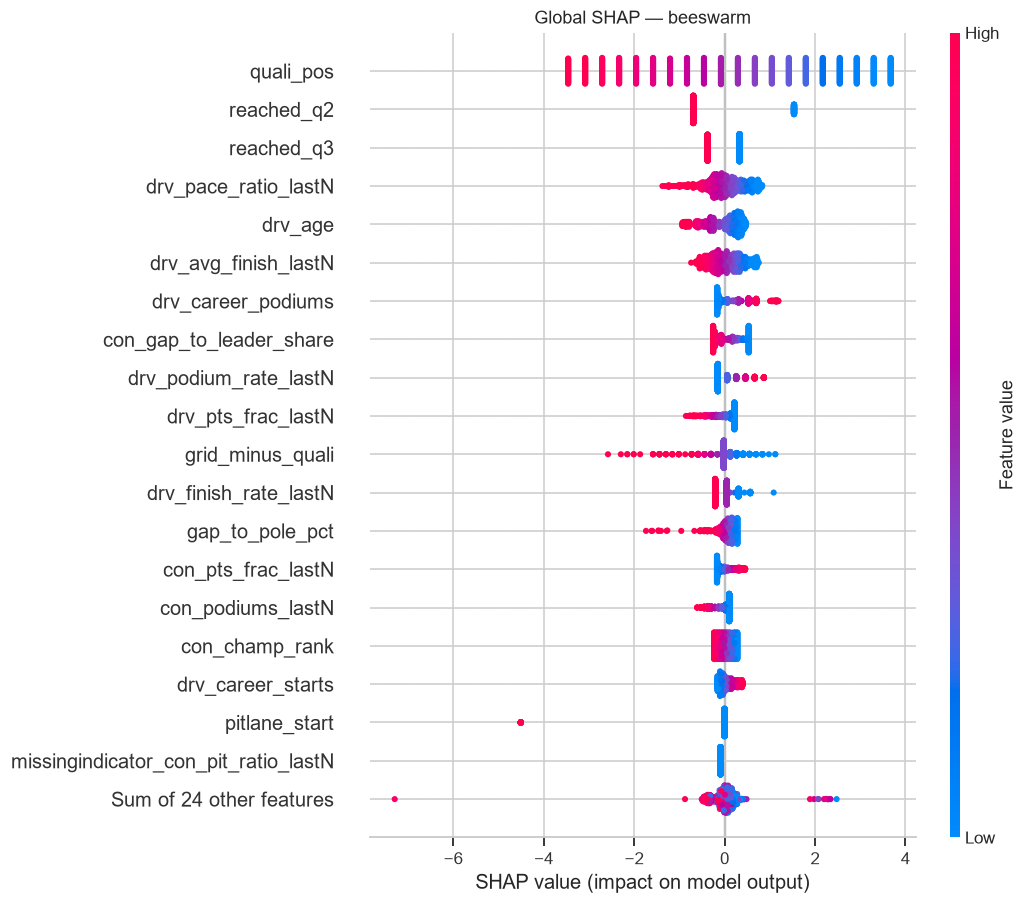

In [77]:
# requires: shap
shap = _ensure("shap")

pipe = xm["model"]
pre_x, clf_x = pipe.named_steps["pre"], pipe.named_steps["clf"]
fnames = list(pre_x.get_feature_names_out())
Z_tr = pd.DataFrame(pre_x.transform(tr[xm["features"]]), columns=fnames)
Z_va = pd.DataFrame(pre_x.transform(va[xm["features"]]), columns=fnames)
Z_sample = Z_va.sample(min(1500, len(Z_va)), random_state=SEED)

if isinstance(clf_x, RandomForestClassifier):
    explainer = shap.TreeExplainer(clf_x)
else:
    explainer = shap.LinearExplainer(clf_x, Z_tr)
sv = explainer(Z_sample)
if sv.values.ndim == 3:            # tree models: (rows, features, classes) -> keep the podium class
    sv = sv[:, :, 1]

shap.plots.bar(sv, max_display=20, show=False); plt.title("Global SHAP — mean |SHAP|"); savefig("xai_shap_bar")
shap.plots.beeswarm(sv, max_display=20, show=False); plt.title("Global SHAP — beeswarm"); savefig("xai_shap_beeswarm")

confident_hit: raceId=1055 driverId=1 year=2021 grid=1.0 p=0.983 actual=1


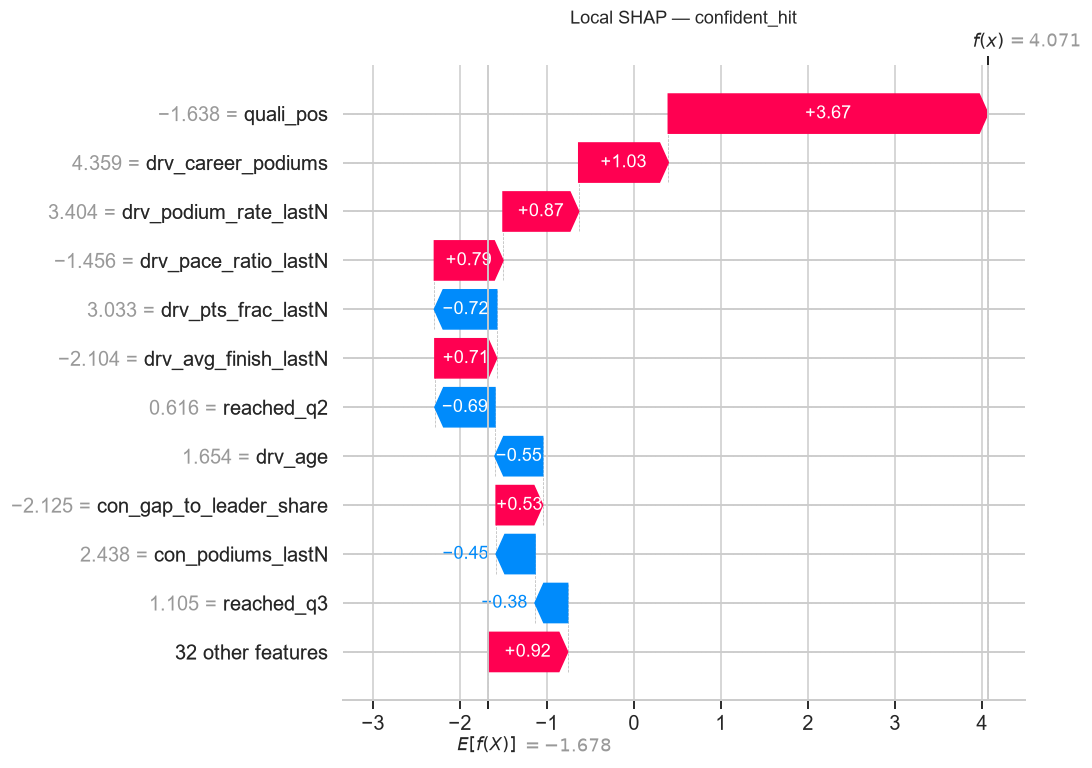

missed_podium: raceId=1062 driverId=839 year=2021 grid=8.0 p=0.113 actual=1


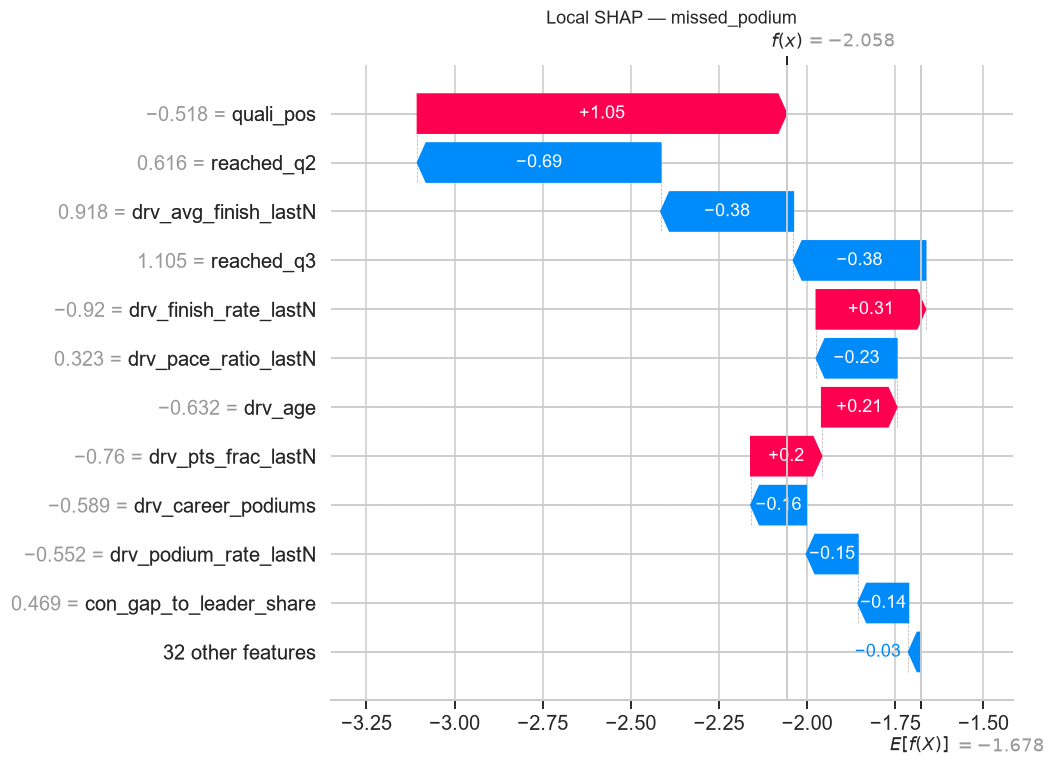

In [78]:
# requires: shap
# 16.2 Local explanation — pick specific rows to explain
p_va_x = get_proba(xm["model"], va[xm["features"]])
cand = va.assign(p=p_va_x)
# DECISION: the most confident correct podium, and the podium the model considered least likely
ROW_HIT = cand[(cand.podium == 1)].p.idxmax()
ROW_MISS = cand[(cand.podium == 1)].p.idxmin()

for label, i in [("confident_hit", ROW_HIT), ("missed_podium", ROW_MISS)]:
    r = cand.loc[i]
    print(f"{label}: raceId={r.raceId} driverId={r.driverId} year={r.year} grid={r.grid} p={r.p:.3f} actual={r.podium}")
    e = explainer(Z_va.loc[[i]])
    e = e[0, :, 1] if e.values.ndim == 3 else e[0]
    shap.plots.waterfall(e, max_display=12, show=False); plt.title(f"Local SHAP — {label}"); savefig(f"xai_shap_waterfall_{label}")

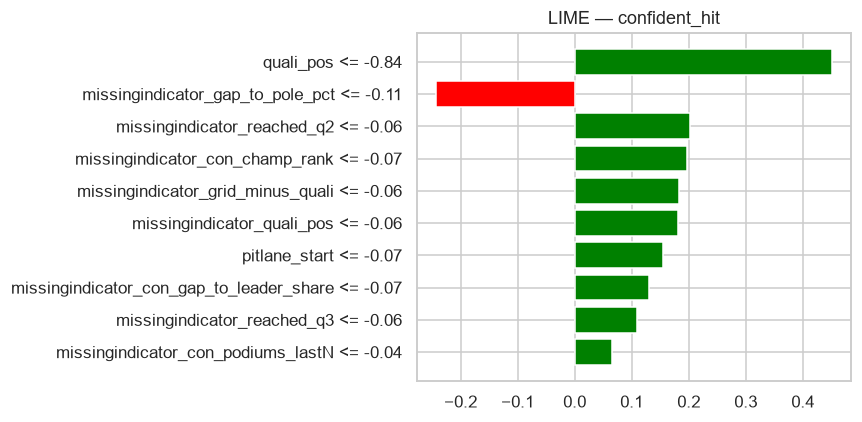

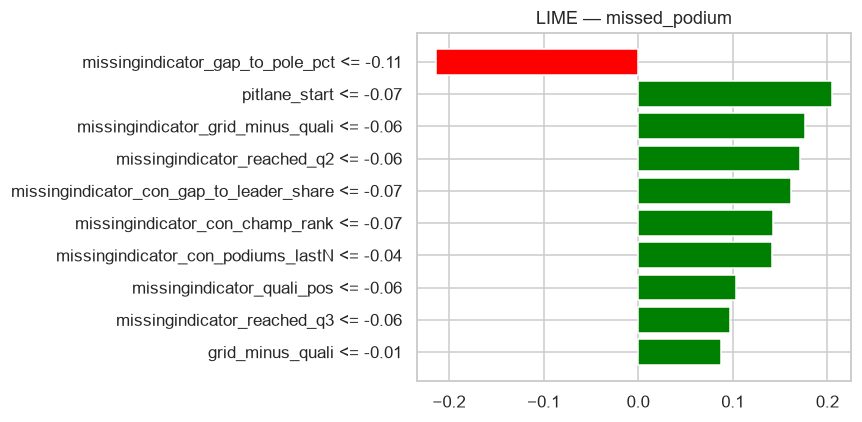

In [79]:
# requires: lime
lime_tabular = _ensure("lime.lime_tabular", "lime")
lime_exp = lime_tabular.LimeTabularExplainer(Z_tr.to_numpy(), feature_names=fnames, class_names=["no podium", "podium"],
                                             mode="classification", random_state=SEED, discretize_continuous=True)
for label, i in [("confident_hit", ROW_HIT), ("missed_podium", ROW_MISS)]:
    ex = lime_exp.explain_instance(Z_va.loc[i].to_numpy(), clf_x.predict_proba, num_features=10)
    fig = ex.as_pyplot_figure(); fig.set_size_inches(8, 4); plt.title(f"LIME — {label}"); plt.tight_layout()
    savefig(f"xai_lime_{label}", fig)

✍️ **WRITE-UP (XAI)** (model explained: `lr_tuned`)
> **Not causal:** the model *uses* these features to predict. That does not show they *cause* podiums.

- **Global.**
  - **Permutation importance** (drop in validation PR-AUC when the feature is shuffled): `quali_pos` 0.49 is far ahead of `reached_q2` 0.08, `drv_career_podiums` 0.05, then `gap_to_pole_pct`, `grid_minus_quali` and `drv_age` at about 0.02.
  - **SHAP** agrees on the top features: `quali_pos` dominates, followed by `reached_q2` / `reached_q3`, `drv_pace_ratio_lastN`, `drv_age` and `drv_avg_finish_lastN`.
- **Directions (beeswarm).** A better (lower) qualifying position, faster recent pace, better recent finishes and more career podiums push towards a podium. A pit-lane start and a grid penalty (`grid_minus_quali` > 0) push strongly down.
- **Odd-looking signs.** `reached_q2` / `reached_q3` and `drv_age` push *down*. These features are strongly correlated with `quali_pos` and career podiums, and in a linear model correlated features share and offset their weights, so each sign only holds given the others. This is exactly why importance is not a causal effect.
- **Local 1, confident hit:** Hamilton, **2021 Spanish GP**, on pole. p = 0.98, and he won. The prediction is driven by `quali_pos` = 1 and strong form.
- **Local 2, missed podium:** Ocon, **2021 Hungarian GP**, started P8. p = 0.11, but he **won** after the first-corner pile-up took out several front-runners. In SHAP, the P8 qualifying lifts the score above a typical entry, while weak recent finishes (`drv_avg_finish_lastN`), slower recent pace and the `reached_q2` / `reached_q3` terms pull it down. Those last two are the collinearity artefact described above; he did reach Q3. That is a reasonable pre-race view; the result came from an incident the model cannot know at the cutoff.
- **LIME vs SHAP.** For the Ocon row, LIME's top terms are missing-value indicators and `pitlane_start`: binary columns that are almost always 0. This is an artefact of how LIME perturbs and discretises near-constant columns. SHAP is exact for a linear model, so we trust it here; LIME's instability is a known limitation.

## 17. Inference function ✅
`predict_podium(record)` takes a dict of **pre-race** fields for one driver in one race. Missing features are imputed by the fitted pipeline; post-race fields are rejected so the function itself cannot be fed leakage.

In [80]:
def predict_podium(record: dict, model_name: str = None, threshold: float = None, verbose: bool = True):
    model_name = model_name or FINAL_MODEL_NAME
    m = MODELS[model_name]
    feats = m["features"]
    thr = m["threshold"] if threshold is None else threshold

    leaked = sorted(set(record) & FORBIDDEN)
    if leaked:
        raise ValueError(f"Post-race fields are not allowed at prediction time: {leaked}")
    unknown = sorted(set(record) - set(feats) - set(ID_COLS))
    missing = [f for f in feats if record.get(f) is None or (isinstance(record.get(f), float) and np.isnan(record.get(f)))]

    X = pd.DataFrame([{f: record.get(f, np.nan) for f in feats}])
    X = X.apply(pd.to_numeric, errors="coerce")
    proba = float(get_proba(m["model"], X)[0])
    out = {"model": model_name, "podium_probability": round(proba, 4), "predicted_podium": bool(proba >= thr),
           "threshold": round(thr, 4), "n_missing_features": len(missing), "missing_features": missing,
           "ignored_fields": unknown}
    if verbose:
        print(json.dumps(out, indent=2, default=str))
    return out

def record_from_table(raceId, driverId):
    r = MT[(MT.raceId == raceId) & (MT.driverId == driverId)]
    assert len(r) == 1, "not in modeling table"
    return r.iloc[0][ID_COLS + FEATURES].to_dict()

In [81]:
# Demo 1: complete record (a real test-set entry)
complete = te[te[FEATURES].notna().all(axis=1)]   # no missing feature (sprint features exist only on sprint weekends)
demo = complete.sort_values(["date"]).iloc[-1]
rec_full = record_from_table(demo.raceId, demo.driverId)
print("actual podium:", int(demo.podium))
_ = predict_podium(rec_full)

# Demo 2: partially missing record — e.g. qualifying data and standings unavailable
rec_partial = {k: v for k, v in rec_full.items() if k not in FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["standings"]}
_ = predict_podium(rec_partial)

# Demo 3: leakage guard
try:
    predict_podium({**rec_full, "points": 25})
except ValueError as e:
    print("Rejected as expected ->", e)

actual podium: 0
{
  "model": "lr_tuned",
  "podium_probability": 0.9203,
  "predicted_podium": true,
  "threshold": 0.7241,
  "n_missing_features": 0,
  "missing_features": [],
  "ignored_fields": []
}
{
  "model": "lr_tuned",
  "podium_probability": 0.0,
  "predicted_podium": false,
  "threshold": 0.7241,
  "n_missing_features": 8,
  "missing_features": [
    "quali_pos",
    "gap_to_pole_pct",
    "reached_q2",
    "reached_q3",
    "drv_champ_rank",
    "con_champ_rank",
    "con_gap_to_leader_share",
    "is_round_1"
  ],
  "ignored_fields": []
}
Rejected as expected -> Post-race fields are not allowed at prediction time: ['points']


## 18. Decision log, limitations & report material

In [82]:
DECISIONS = {
    "Data scope (D1)": f"{DATA_SCOPE} {SCOPE_YEARS[DATA_SCOPE]}",
    "Split": f"train {TRAIN_YEARS}, val {VAL_YEARS}, test {TEST_YEARS}",
    "Form window (races)": FORM_WINDOW,
    "Selected groups": ", ".join(SELECTED_GROUPS), "Categorical features": CATEGORICAL or "none",
    "Primary / secondary metric": f"{PRIMARY_METRIC} / {SECONDARY_METRIC}", "Threshold strategy": THRESHOLD_STRATEGY,
    "Final model": FINAL_MODEL_NAME, "Q1 eras / min starts": f"{PRE_HYBRID} vs {HYBRID}, ≥{Q1_MIN_STARTS}",
    "Q2 grid bins / period": f"{Q2_GRID_BINS}, {Q2_PERIOD}", "Q3 min starts": Q3_MIN_STARTS,
}
pd.Series(DECISIONS, name="current value").to_frame()

,current value
Data scope (D1),"modern (2006, 2024)"
Split,"train (2006, 2020), val (2021, 2022), test (20..."
Form window (races),5
Selected groups,"grid, qualifying, standings, driver_form, cons..."
Categorical features,none
Primary / secondary metric,pr_auc / f1
Threshold strategy,max_f1
Final model,lr_tuned
Q1 eras / min starts,"(2003, 2013) vs (2014, 2024), ≥8"
Q2 grid bins / period,"[0, 1, 3, 6, 10, 15, 40], (1950, 2024)"


In [83]:
# Everything the report needs, in one place
print("Figures saved:", len(list(FIG_DIR.glob('*.png'))), "->", FIG_DIR)
print("Tables saved :", sorted(p.name for p in OUT_DIR.glob('*.csv')))

Figures saved: 33 -> outputs\figures
Tables saved : ['ablation.csv', 'cleaning_before_after.csv', 'cleaning_log.csv', 'decision_summary.csv', 'feature_evidence.csv', 'feature_selection.csv', 'missing_fill_log.csv', 'missingness_types.csv', 'model_comparison.csv', 'modeling_table.csv', 'permutation_importance.csv', 'preprocessing_experiments.csv', 'q2_sensitivity.csv', 'q3_mechanical_rates.csv', 'scope_comparison.csv', 'threshold_strategy.csv', 'tuning_lr.csv', 'tuning_rf.csv']


In [84]:
# Cleaning decision summary (D1–D16) with counts from the cleaning log — for the report
L = pd.DataFrame(CLEANING_LOG)
cnt = lambda step, col="rows_affected": int(pd.to_numeric(L.loc[L.step == step, col], errors="coerce").fillna(0).sum())
DECISION_SUMMARY = pd.DataFrame([
    ("D1", "Seasons", f"main {SCOPE_YEARS['modern']}, comparison {SCOPE_YEARS['all']}; first seasons {FIRST_SEASON}"),
    ("D2", "Non-starters", f"dropped {int(D2_COUNTS.iloc[:, 0].sum())} rows without a grid slot "
                           f"(modern: {int(D2_COUNTS.iloc[:, 1].sum())}); kept {kept_withdrew} 'Withdrew' with grid > 0"),
    ("D3", "Shared drives", f"merged {len(SHARED_ROWS)} rows into {SHARED_ROWS.groupby(KEY).ngroups} driver-races; "
                            f"{len(PODIUM_EXCEPTIONS)} races without exactly 3 podium rows (all explained)"),
    ("D4", "Indianapolis 500", f"excluded {len(INDY_IDS)} races ({cnt('D4')} rows across tables)"),
    ("D5", "grid = 0", f"{int(CLEAN['results'].pitlane_start.sum())} pit-lane starts -> field_size + 1; "
                       f"{int(CLEAN['results'].grid_unknown.sum())} unknown pre-2006 slots -> NaN"),
    ("D6", "Missing features", f"domain fill {int(D6_LOG.filled_step1_domain.sum())} cells; "
                               f"{int(D6_LOG.left_for_step2_median.sum())} cells left for train-median + indicator"),
    ("D7", "Round-1 standings", f"{int(RACE_ORDER.is_round_1.sum())} round-1 races use last season's final standings"),
    ("D8", "Timing outliers", f"{cnt('D8', 'cells_affected')} cells -> NaN (hard limits only: pit stops outside [1.5 s, 120 s], qualifying > 2x session median)"),
    ("D9", "Lap cleaning", f"{len(clean_laps)} clean laps kept of {len(lt)}; pace_ratio for {int(PACE.pace_ratio.notna().sum())} driver-races"),
    ("D10", "Target", f"podium = positionOrder <= 3; all modern races have exactly 3"),
    ("D11", "Status codebook", f"{len(STATUS_MAP)} labels -> {STATUS_MAP.group.value_counts().to_dict()}"),
    ("D12", "Constructor lineage", f"{len(LINEAGE)} rules, {pd.DataFrame(LINEAGE)[1].nunique()} families"),
    ("D13", "Standings", "rank, pts_share, gap_to_leader_share (no raw points)"),
    ("D14", "Sprint weekends", f"{len(SPRINT_RACES)} sprint weekends; sprint_finish_pct as a feature"),
    ("D15", "ISO countries", f"{len(NATIONALITY_ISO)} nationalities + {len(COUNTRY_ISO)} countries, 0 unmapped"),
    ("D16", "Abnormal races", f"{int(RACE_FLAGS.race_shortened.sum())} races flagged race_shortened (reporting only)"),
], columns=["decision", "topic", "applied (counts)"]).set_index("decision")
DECISION_SUMMARY.to_csv(OUT_DIR / "decision_summary.csv")
DECISION_SUMMARY

,topic,applied (counts)
decision,,
D1,Seasons,"main (2006, 2024), comparison (1950, 2024); fi..."
D2,Non-starters,dropped 1535 rows without a grid slot (modern:...
D3,Shared drives,merged 125 rows into 61 driver-races; 15 races...
D4,Indianapolis 500,excluded 11 races (1132 rows across tables)
D5,grid = 0,77 pit-lane starts -> field_size + 1; 45 unkno...
D6,Missing features,domain fill 11360 cells; 12516 cells left for ...
D7,Round-1 standings,75 round-1 races use last season's final stand...
D8,Timing outliers,482 cells -> NaN (hard limits only: pit stops ...
D9,Lap cleaning,513483 clean laps kept of 589081; pace_ratio f...


### ✍️ Report outline (PDF)
1. **Data audit & cleaning:** sentinels, typing, PK/FK results (before/after tables), decisions D1–D16 with counts (`outputs/decision_summary.csv`).
2. **Data-engineering answers:** Q1, Q2, Q3 with figures, grain, missingness and cutoff notes (write-ups in §7).
3. **Modeling table & features:** each feature and why it is valid at the pre-race cutoff; leakage tests; selection rule (§9).
4. **Split & preprocessing:** season split; preprocessing experiments E1–E3.
5. **Models:** baseline vs others; comparison table (validation + test); PR-AUC primary / F1 secondary; scope comparison (§14.2).
6. **Ablation:** group contributions.
7. **XAI:** global and local explanations, with the explicit **non-causal** statement.
8. **Inference:** complete vs partially missing record demo.
9. **Limitations:**
   - **Qualifying-coverage drift:** complete only from 2003, so the model is restricted to 2006+ (D1); the historical scope is tested in §14.2.
   - **Era sensitivity:** regulation changes (2014, 2022) reshuffle teams. Test is 2023–24 only; 2024 (four winning teams) is harder than 2023.
   - **Calibration:** probabilities are not calibrated (class weighting), so use them as scores.
   - **Sprints:** sprint features are unusable while training ends in 2020; pit-stop data only exists from 2011.
   - **Small samples:** Q1 has 8–22 starts per circuit and era; Q2 has 82 home entries on pole.
   - **Judgement calls:** status groups and constructor lineage; nationality is not always "home".
   - **Unpredictable events:** first-lap incidents, safety cars and weather cap the achievable accuracy (see the Ocon case).
   - **LIME** is unstable on binary columns; SHAP is preferred for the linear model.